# **PDG  - TIME UP AND GO**
* **Esteban Guarin Valencia**
* **Santiago Gomez Robledo**
* **Heiner Danit Rincon**
* **Juan Jose Arias Gallego**

# PIPELINE 1: IMUs (TUG)


Esta sección implementa la arquitectura actualizada de procesamiento de señales inerciales y extracción de biomarcadores cinemáticos para los registros recolectados durante las brigadas clínicas del proyecto TUG-V2. El diseño metodológico se articula bajo el marco híbrido acordado en las sesiones de dirección técnica (Reuniones 6, 7 y 8), combinando los bloques iterativos de entendimiento de negocio, entendimiento de datos, preparación de datos, modelado y evaluación de la metodología CRISP-DM con la preservación estricta de la formulación matemática desarrollada por el equipo predecesor.

El flujo de trabajo se estructura en nueve módulos secuenciales que garantizan la trazabilidad desde los archivos crudos anonimizados hasta las pruebas de hipótesis estadísticas entre pacientes con Enfermedad de Parkinson y sujetos de control. Cada etapa conserva los parámetros de filtrado, ventaneo energético, suavizado por media móvil, umbralización binaria y detección de eventos de paso del código predecesor, asegurando que cualquier registro actual adaptado al esquema JSON histórico produzca exactamente las mismas curvas y métricas tanto en las funciones heredadas como en los módulos actuales.

| Módulo | Componente Metodológico | Propósito y Entregable Verificable |
| :--- | :--- | :--- |
| **Módulo 1** | Configuración del entorno e ingesta | Detección automática del repositorio de 78 grabaciones IMU en entorno local o Google Colab y lectura segura de estructuras JSON. |
| **Módulo 2** | Identificación demográfica y cruce bimodal | Asignación determinística de identificadores de sujeto (`P01` a `P65`), detección de tomas repetidas y cruce temporal con registros de cámara RGB-D (`e-Motion`). |
| **Módulo 3** | Auditoría de calidad y reglas de descarte | Aplicación de los cinco criterios de exclusión clínica y técnica, consolidando 66 muestras válidas (58 pacientes y 8 controles) y 12 descartes documentados. |
| **Módulo 4** | Adaptación de esquema JSON y equivalencia | Transformación del formato actual (`imuData` multifuente) al esquema del proyecto predecesor (`pruebas` a 50,0 Hz) con exportación directa para validación cruzada. |
| **Módulo 5** | Segmentación de levantamiento y sentado | Procesamiento del canal de flexo-extensión lumbar (`espina_base`, eje `b`), reproducción exacta de las gráficas del predecesor y demostración numérica de equivalencia. |
| **Módulo 6** | Detección y caracterización de giros | Procesamiento de la velocidad angular de guiñada (`espina_base`, eje `a`), aislamiento de los giros de 180° y cuantificación de duración y velocidad angular pico. |
| **Módulo 7** | Gráfica compuesta superpuesta de cinco fases | Superposición de las curvas de energía de transición postural y de giro con delimitación vertical contigua de las cinco fases biomecánicas del test TUG. |
| **Módulo 8** | Detección de pasos (`SWING` / `STANCE`) por fase | Identificación de eventos de apoyo y balanceo en ambos tobillos (`izquierda` y `derecha`, eje `x`) e incorporación de la columna de clasificación por fase TUG (`fase_tug`). |
| **Módulo 9** | Procesamiento masivo y análisis estadístico | Extracción automatizada de biomarcadores sobre las 66 muestras válidas y contrastación mediante pruebas de Shapiro-Wilk, $t$ de Welch y $U$ de Mann-Whitney. |

## MÓDULO 1: Configuración del Entorno e Ingesta de Datos Crudos

Este módulo establece las dependencias científicas necesarias para el procesamiento digital de señales (`numpy`, `scipy.signal`, `scipy.stats`, `pandas` y `matplotlib`) y resuelve de manera automática la ubicación del directorio que almacena las 78 grabaciones crudas en formato JSON. La función `buscar_archivos_tug` inspecciona secuencialmente las rutas relativas locales (`Datos IMUs`, `../Datos IMUs`, `datos_extraidos/anonymized_data`) y, en caso de ejecutarse dentro de Google Colaboratory sin archivos locales, realiza el montaje automático de Google Drive en `/content/drive/MyDrive/TUG_Data/`.

La función `cargar_datos_json` encapsula la apertura y deserialización UTF-8 de cada archivo JSON, devolviendo un diccionario estructurado en memoria. El resultado de este módulo verifica la integridad del inventario inicial de 78 archivos recolectados entre febrero y agosto de 2026.

In [3]:
import os
import glob
import json
import hashlib
import datetime
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, find_peaks
from scipy.stats import shapiro, ttest_ind, mannwhitneyu

def buscar_archivos_tug(folder_path=None):
    posibles_rutas = [
        folder_path,
        "Datos IMUs/IMUS",
        "../Datos IMUs/IMUS",
        "./Datos IMUs/IMUS",
        "Datos IMUs",
        "../Datos IMUs",
        "./Datos IMUs",
        "datos_extraidos/anonymized_data",
        "../datos_extraidos/anonymized_data",
        os.path.join(os.getcwd(), "Datos IMUs", "IMUS"),
        os.path.join(os.getcwd(), "Datos IMUs"),
        os.path.join(os.path.dirname(os.getcwd()), "Datos IMUs", "IMUS"),
        os.path.join(os.path.dirname(os.getcwd()), "Datos IMUs"),
        "/content/drive/MyDrive/TUG_Data/IMUS",
        "/content/drive/MyDrive/TUG_Data/"
    ]

    for ruta in posibles_rutas:
        if ruta and os.path.exists(ruta) and os.path.isdir(ruta):
            archivos = sorted(glob.glob(os.path.join(ruta, "*.json")))
            if not archivos and os.path.exists(os.path.join(ruta, "IMUS")):
                archivos = sorted(glob.glob(os.path.join(ruta, "IMUS", "*.json")))
                if archivos:
                    return os.path.join(ruta, "IMUS"), archivos
            elif archivos:
                return ruta, archivos

    try:
        from google.colab import drive
        print("Entorno Google Colab detectado. Montando Google Drive...")
        drive.mount("/content/drive")
        colab_path = "/content/drive/MyDrive/TUG_Data/"
        if os.path.exists(colab_path):
            archivos = sorted(glob.glob(os.path.join(colab_path, "*.json")))
            if archivos:
                return colab_path, archivos
    except Exception:
        pass

    return None, []

def cargar_datos_json(ruta_archivo):
    try:
        with open(ruta_archivo, "r", encoding="utf-8") as f:
            return json.load(f)
    except Exception as e:
        print(f"Error al leer {ruta_archivo}: {e}")
        return None

CARPETA_DATOS, ARCHIVOS_JSON = buscar_archivos_tug()

print("=" * 75)
print("ESTADO DE CARGA DE DATOS CRUDOS (MÓDULO 1)")
print("=" * 75)
if CARPETA_DATOS and ARCHIVOS_JSON:
    print(f"Directorio activo detectado: {CARPETA_DATOS}")
    print(f"Total de grabaciones JSON encontradas: {len(ARCHIVOS_JSON)}")
    print(f"Primer registro cronológico: {os.path.basename(ARCHIVOS_JSON[0])}")
    print(f"Último registro cronológico: {os.path.basename(ARCHIVOS_JSON[-1])}")
else:
    print("No se encontró el directorio de grabaciones JSON.")


ESTADO DE CARGA DE DATOS CRUDOS (MÓDULO 1)
Directorio activo detectado: ../Datos IMUs/IMUS
Total de grabaciones JSON encontradas: 78
Primer registro cronológico: CST_IDI10_BI.json
Último registro cronológico: SMR_IDI9_BW.json


## MÓDULO 2: Identificación Demográfica de Participantes y Cruce con Cámaras RGB-D (e-Motion / VIMOV)

En cumplimiento de los protocolos de privacidad clínica y anonimización de la Fundación Valle del Lili y la plataforma VIMOV, los archivos JSON tienen vacíos los campos de identidad nominal (`id`, `name`, `lastName`, `patient.id`), y el sufijo alfabético del nombre de archivo (`_temp_A` a `_temp_BX`) identifica la sesión de captura, no al paciente. Para reconstruir la relación entre grabaciones y sujetos físicos sin riesgo de fuga de datos (*data leakage*), la función `identificar_y_organizar_personas` agrupa las grabaciones etiquetadas mediante la llave demográfica compuesta `(birthDate, sex, patientType)` y corrobora la consistencia cruzada mediante la estatura (`height`), el kit instrumental (`base` o `K1`), la marca temporal UTC de inicio (`timestamp`) y las observaciones clínicas.

Adicionalmente, este módulo audita la firma criptográfica MD5 de cada archivo en disco para detectar duplicados exactos generados por reintentos de sincronización de red durante las brigadas, verifica la presencia de los tres sensores anatómicos obligatorios (`BASE-SPINE`, `LEFT-ANKLE`, `RIGHT-ANKLE`), registra los tiempos de pausa (`pausedDurationMs`), e identifica condiciones especiales como Estimulación Cerebral Profunda (`DBS`) y pruebas bajo exigencia cognitiva de Doble Tarea (*Dual Task*).

En atención a los lineamientos acordados en las Reuniones 7 y 8 con el profesor Domiciano Rincón respecto a la auditoría bimodal y trazabilidad con el sistema de visión artificial:
1. **Auditoría Estricta de Protocolo TUG:** El dataset de cámaras e-Motion en `Datos e-Motion/TUG/` consolida **130 grabaciones estrictamente correspondientes a la prueba TUG** (`TIMED_UP_AND_GO`), habiendo segregado 95 grabaciones de marcha continua libre (`Gait Analysis` y `GAIT_COMPLETE`) hacia la carpeta `Datos e-Motion/GAIT/`.
2. **Validación Demográfica y Biológica de Género (100% de Concordancia):** Se exige concordancia absoluta de sexo biológico entre el registro IMU y el metadato de VIMOV. Como resultado de esta regla metodológica, se identificaron y descartaron formalmente 5 pares espurios donde la cámara evaluaba a una persona del sexo opuesto en una ventana temporal cercana (`P17`, `P19`, `P23`, `P29`).
3. **Pares Bimodales Validados:** La función `cruzar_fechas_imu_emotion` cruza el registro inercial frente a la base auditada de e-Motion (`Datos_eMotion.csv`), confirmando **42 pares bimodales estrictamente TUG** con diferencia temporal $|\Delta t| \le 360$ s y total trazabilidad en disco.


In [4]:
# Parámetros de Selección Demográfica y Cruce VIMOV (MÓDULO 2)
filtrar_grupo_clinico = "TODOS"  # Opciones: "TODOS", "PATIENT", "CONTROL", "SIN_ETIQUETA"
mostrar_tabla_sujetos_multiples = True
mostrar_cruce_bimodal = True

In [5]:
def identificar_y_organizar_personas(archivos_json):
    registros_temp = []
    vistos_md5 = {}

    for ruta in sorted(archivos_json):
        nombre = os.path.basename(ruta)
        with open(ruta, "rb") as f:
            crudo = f.read()

        md5_hash = hashlib.md5(crudo).hexdigest()
        es_duplicado = md5_hash in vistos_md5
        archivo_original_md5 = vistos_md5.get(md5_hash, None)
        if not es_duplicado:
            vistos_md5[md5_hash] = nombre

        try:
            d = json.loads(crudo.decode("utf-8"))
        except Exception:
            continue

        p = d.get("patient") or {}
        inicio_ms = d.get("timestamp")
        fin_ms = d.get("endTimestamp")
        pausa_ms = d.get("pausedDurationMs") or 0
        has_warning = bool(d.get("hasWarning", False))
        warning_reason = d.get("warningReason") or "Sin advertencias"

        imu_data = d.get("imuData") or []
        sensores_presentes = sorted(list({m.get("deviceId", "") for m in imu_data if m.get("deviceId")}))
        kit = "K1" if any(s.startswith("K1-") for s in sensores_presentes) else "base"

        tiene_espina = any("spine" in s.lower() or "base" in s.lower() for s in sensores_presentes)
        tiene_tob_izq = any("left-ankle" in s.lower() or "left_ankle" in s.lower() for s in sensores_presentes)
        tiene_tob_der = any("right-ankle" in s.lower() or "right_ankle" in s.lower() for s in sensores_presentes)
        min_sensores_ok = bool(tiene_espina and tiene_tob_izq and tiene_tob_der)

        if len(imu_data) > 1:
            t_vals = [m.get("timestamp", 0) for m in imu_data if "timestamp" in m]
            duracion_s = round((max(t_vals) - min(t_vals)) / 1000.0, 2) if t_vals else 0.0
        else:
            duracion_s = 0.0

        if "_temp_" in nombre:
            codigo = nombre.split("_temp_")[1].replace(".json", "")
        elif "_TUG_" in nombre:
            codigo = nombre.replace(".json", "").split("_TUG_")[1]
        else:
            codigo = nombre.replace(".json", "").split("_")[-1]
        tipo = p.get("patientType") or "SIN_ETIQUETA"
        sexo = p.get("sex") or "NO_REGISTRA"
        nacimiento = p.get("birthDate") or "NO_REGISTRA"
        talla = str(p.get("height") or "NO_REGISTRA").strip()
        obs_paciente = (p.get("observations") or "").strip()
        obs_prueba = (d.get("observations") or "").strip()

        texto_obs = f"{obs_paciente} {obs_prueba}".lower()
        es_doble_tarea = ("dual task" in texto_obs) or ("doble tarea" in texto_obs)
        tiene_dbs = "dbs" in texto_obs

        inicio_utc = (
            datetime.datetime.fromtimestamp(inicio_ms / 1000.0, datetime.timezone.utc)
            .strftime("%Y-%m-%d %H:%M:%S")
            if inicio_ms and inicio_ms > 1e12 else "NO_REGISTRA"
        )

        registros_temp.append({
            "archivo": nombre,
            "ruta_completa": ruta,
            "codigo": codigo,
            "md5": md5_hash,
            "duplicado_exacto": es_duplicado,
            "duplicado_de": archivo_original_md5 if es_duplicado else "Ninguno",
            "tipo": tipo,
            "sexo": sexo,
            "nacimiento": nacimiento,
            "talla": talla,
            "kit": kit,
            "num_sensores": len(sensores_presentes),
            "sensores": ", ".join(sensores_presentes),
            "min_sensores_ok": min_sensores_ok,
            "duracion_s": duracion_s,
            "pausa_ms": pausa_ms,
            "tiene_warning": has_warning,
            "motivo_warning": warning_reason,
            "es_doble_tarea": es_doble_tarea,
            "tiene_dbs": tiene_dbs,
            "inicio_ms": inicio_ms,
            "fin_ms": fin_ms,
            "inicio_utc": inicio_utc,
            "obs_paciente": obs_paciente if obs_paciente else "Sin observaciones",
            "obs_prueba": obs_prueba if obs_prueba else "Sin observaciones"
        })

    grupos_todos = defaultdict(list)
    for r in registros_temp:
        llave = (r["nacimiento"], r["sexo"], r["tipo"])
        grupos_todos[llave].append(r)

    ids_oficiales = {}
    for llave in sorted(grupos_todos, key=lambda k: min(x["archivo"] for x in grupos_todos[k])):
        ids_oficiales[llave] = f"P{len(ids_oficiales) + 1:02d}"

    for r in registros_temp:
        llave = (r["nacimiento"], r["sexo"], r["tipo"])
        r["persona_id"] = ids_oficiales[llave]
        r["es_participante_etiquetado"] = r["tipo"] in ("PATIENT", "CONTROL")

    # Cruce con VIMOV para metadata demográfica y de trazabilidad
    cruce_map = {}
    posibles_cruce = [
        "Datos IMUs/Cruce_VIMOV_IMUs.csv",
        "../Datos IMUs/Cruce_VIMOV_IMUs.csv",
        os.path.join(os.getcwd(), "Datos IMUs", "Cruce_VIMOV_IMUs.csv"),
        os.path.join(os.path.dirname(os.getcwd()), "Datos IMUs", "Cruce_VIMOV_IMUs.csv")
    ]
    for p_cr in posibles_cruce:
        if os.path.exists(p_cr):
            try:
                df_cr = pd.read_csv(p_cr).set_index("archivo")
                cruce_map = df_cr.to_dict(orient="index")
                break
            except Exception:
                pass

    for r in registros_temp:
        f_name = r["archivo"]
        c_info = cruce_map.get(f_name, {})
        u_str = str(r["inicio_utc"])
        r["fecha"] = u_str[:10] if len(u_str) >= 10 else ""
        r["hora_utc"] = u_str[11:19] if len(u_str) >= 19 else ""
        pid_vimov = c_info.get("vimov_patient_national_id")
        if not pid_vimov or pd.isna(pid_vimov) or pid_vimov == "PRUEBA_TECNICA_CALIBRACION":
            pid_vimov = "SIN_REGISTRO_VIMOV"
        r["patient_id"] = pid_vimov
        tid_vimov = c_info.get("vimov_test_uuid")
        r["test_id"] = "" if (not tid_vimov or pd.isna(tid_vimov) or str(tid_vimov).startswith("N/A")) else str(tid_vimov)
        r["sensor"] = f"IMU {r['kit'].upper()} ({r['num_sensores']} sensores)"

        # Cálculo de edad
        age = None
        if pd.notna(r["nacimiento"]) and str(r["nacimiento"]) != "NO_REGISTRA":
            try:
                b_year = int(str(r["nacimiento"]).split("/")[-1])
                f_year = int(r["fecha"][:4])
                age = f_year - b_year
            except Exception:
                pass
        r["edad"] = age

    columnas_orden = [
        "persona_id", "archivo", "codigo", "fecha", "patient_id", "test_id",
        "tipo", "sexo", "nacimiento", "edad", "talla", "sensor",
        "hora_utc", "kit", "num_sensores", "sensores", "min_sensores_ok",
        "duplicado_exacto", "duplicado_de", "es_doble_tarea", "tiene_dbs",
        "tiene_warning", "motivo_warning", "obs_paciente", "obs_prueba", "ruta_completa",
        "duracion_s", "pausa_ms", "inicio_ms", "fin_ms", "md5", "inicio_utc"
    ]
    df_personas = pd.DataFrame(registros_temp)[columnas_orden]
    return df_personas

def cruzar_fechas_imu_emotion(df_personas):
    posibles_csv = [
        'Datos e-Motion/Inventario_eMotion.csv',
        '../Datos e-Motion/Inventario_eMotion.csv',
        'Inventario_eMotion.csv',
        'Datos e-Motion/df_variables_emotion.csv',
        '../Datos e-Motion/df_variables_emotion.csv',
        'df_variables_emotion.csv',
        os.path.join(os.getcwd(), 'Datos e-Motion', 'Inventario_eMotion.csv'),
        os.path.join(os.getcwd(), 'Datos e-Motion', 'df_variables_emotion.csv'),
        os.path.join(os.path.dirname(os.getcwd()), 'Datos e-Motion', 'Inventario_eMotion.csv'),
        'Analisis de Datos/Datos_eMotion.csv',
        'Datos_eMotion.csv'
    ]
    csv_path = None
    for r in posibles_csv:
        if os.path.exists(r) and os.path.isfile(r):
            csv_path = r
            break

    posibles_dir_em = [
        'Datos e-Motion',
        '../Datos e-Motion',
        './Datos e-Motion',
        os.path.join(os.getcwd(), 'Datos e-Motion'),
        os.path.join(os.path.dirname(os.getcwd()), 'Datos e-Motion')
    ]
    dir_em = None
    for r in posibles_dir_em:
        if os.path.exists(r) and os.path.isdir(r):
            dir_em = r
            break

    detalles_json = {}
    if dir_em:
        sub_dirs = [dir_em, os.path.join(dir_em, 'TUG'), os.path.join(dir_em, 'GAIT')]
        for sdir in sub_dirs:
            if not os.path.exists(sdir) or not os.path.isdir(sdir):
                continue
            for f in os.listdir(sdir):
                if f.endswith('.json'):
                    try:
                        with open(os.path.join(sdir, f), 'r', encoding='utf-8') as jf:
                            d = json.load(jf)
                            meta = d.get('AnonymizedMetadata', {})
                            detalles_json[f] = {
                                'delta_s': meta.get('delta_segundos', 0.0),
                                'genero_vimov': meta.get('validacion_cruzada', {}).get('sexo_vimov', 'N/A'),
                                'sensor': meta.get('sensor', 'Intel RealSense'),
                                'protocolo': meta.get('protocolo', 'TIMED_UP_AND_GO')
                            }
                    except Exception:
                        pass

    coincidencias = []
    if csv_path:
        df_em_audit = pd.read_csv(csv_path)
        es_tug = df_em_audit['subcarpeta'] == 'TUG' if 'subcarpeta' in df_em_audit.columns else df_em_audit['archivo'].astype(str).str.contains('_TUG')
        df_bimodal_em = df_em_audit[(df_em_audit['tiene_imu'].astype(str).str.lower() == 'true') & es_tug].copy()
        for _, r_imu in df_personas.iterrows():
            arch_imu = r_imu['archivo']
            if 'archivo_imu' in df_bimodal_em.columns:
                match = df_bimodal_em[df_bimodal_em['archivo_imu'] == arch_imu]
                if match.empty and arch_imu == 'SMR_IDI20_BA.json':
                    match = df_bimodal_em[df_bimodal_em['archivo_imu'] == 'SMR_ID21_IMU_TUG_BA.json']
            else:
                match = df_bimodal_em[df_bimodal_em['id_sujeto_imu'] == r_imu['persona_id']]
            if not match.empty:
                r_match = match.iloc[0]
                arch_em = r_match['archivo']
                dj = detalles_json.get(arch_em, {})
                coincidencias.append({
                    'archivo_imu': arch_imu,
                    'codigo_imu': r_imu['codigo'],
                    'persona_id': r_imu['persona_id'],
                    'tipo': r_imu['tipo'],
                    'sexo_imu': r_imu['sexo'],
                    'genero_vimov': dj.get('genero_vimov', r_imu['sexo']),
                    'inicio_imu_utc': r_imu.get('inicio_utc', r_imu.get('hora_utc', '')),
                    'archivo_emotion': arch_em,
                    'delta_t_s': dj.get('delta_s', 0.0),
                    'sensor_camara': dj.get('sensor', r_match.get('sensor', 'Intel RealSense')),
                    'brigada': r_match.get('brigada', 'SMR')
                })
    elif dir_em:
        for f, dj in detalles_json.items():
            arch_imu = dj.get('archivo_imu')
            if arch_imu:
                row_imu = df_personas[df_personas['archivo'] == arch_imu]
                if not row_imu.empty:
                    r_imu = row_imu.iloc[0]
                    coincidencias.append({
                        'archivo_imu': arch_imu,
                        'codigo_imu': r_imu['codigo'],
                        'persona_id': r_imu['persona_id'],
                        'tipo': r_imu['tipo'],
                        'sexo_imu': r_imu['sexo'],
                        'genero_vimov': dj.get('genero_vimov', r_imu['sexo']),
                        'inicio_imu_utc': r_imu.get('inicio_utc', r_imu.get('hora_utc', '')),
                        'archivo_emotion': f,
                        'delta_t_s': dj.get('delta_s', 0.0),
                        'sensor_camara': dj.get('sensor', 'Intel RealSense'),
                        'brigada': 'SMR' if f.startswith('SMR_') else ('CST' if f.startswith('CST_') else 'LAB')
                    })

    if not coincidencias:
        return pd.DataFrame()

    df_res = pd.DataFrame(coincidencias)
    return df_res.sort_values('archivo_imu').reset_index(drop=True)

df_personas = identificar_y_organizar_personas(ARCHIVOS_JSON)

personas_etiquetadas = df_personas[df_personas['tipo'].isin(['PATIENT', 'CONTROL'])]['persona_id'].nunique()
print('=' * 80)
print('RESUMEN DEMOGRÁFICO Y DE AUDITORÍA DE SUJETOS (MÓDULO 2)')
print('=' * 80)
print(f'Total de grabaciones analizadas:               {len(df_personas)}')
print(f'Participantes clínicos únicos (etiquetados):   {personas_etiquetadas} (54 PATIENT, 7 CONTROL)')
print(f'Duplicados exactos de red (MD5 idéntico):      {df_personas["duplicado_exacto"].sum()}')
print(f'Grabaciones con advertencia de desconexión:    {df_personas["tiene_warning"].sum()}')
print(f'Grabaciones bajo protocolo de Doble Tarea:     {df_personas["es_doble_tarea"].sum()}')
print('-' * 80)

resumen_tipos = df_personas.groupby('tipo').agg(
    Grabaciones=('archivo', 'count'),
    Personas_Unicas=('persona_id', 'nunique'),
    Duplicados_MD5=('duplicado_exacto', 'sum'),
    Con_Warning=('tiene_warning', 'sum'),
    Doble_Tarea=('es_doble_tarea', 'sum')
).reset_index()
display(resumen_tipos)

conteo_por_persona = df_personas[df_personas['tipo'].isin(['PATIENT', 'CONTROL'])].groupby('persona_id')['archivo'].count()
ids_multiples = conteo_por_persona[conteo_por_persona > 1].index.tolist()
print(f'\nParticipantes con múltiples grabaciones ({len(ids_multiples)} sujetos):')
cols_multi = ['persona_id', 'codigo', 'archivo', 'tipo', 'sexo', 'nacimiento', 'talla', 'kit', 'duplicado_exacto', 'es_doble_tarea', 'obs_prueba']
display(df_personas[df_personas['persona_id'].isin(ids_multiples)][cols_multi].sort_values(['persona_id', 'archivo']))

df_cruce_camaras = cruzar_fechas_imu_emotion(df_personas)
if not df_cruce_camaras.empty:
    print(f'\nCorrespondencia bimodal confirmada entre grabaciones IMU y cámara e-Motion ({len(df_cruce_camaras)} pares estrictamente TUG):')
    cols_display = ['archivo_imu', 'codigo_imu', 'persona_id', 'tipo', 'sexo_imu', 'genero_vimov', 'archivo_emotion', 'delta_t_s', 'sensor_camara', 'brigada']
    display(df_cruce_camaras[cols_display])


RESUMEN DEMOGRÁFICO Y DE AUDITORÍA DE SUJETOS (MÓDULO 2)
Total de grabaciones analizadas:               78
Participantes clínicos únicos (etiquetados):   61 (54 PATIENT, 7 CONTROL)
Duplicados exactos de red (MD5 idéntico):      2
Grabaciones con advertencia de desconexión:    2
Grabaciones bajo protocolo de Doble Tarea:     3
--------------------------------------------------------------------------------


,tipo,Grabaciones,Personas_Unicas,Duplicados_MD5,Con_Warning,Doble_Tarea
0,CONTROL,8,7,0,0,0
1,PATIENT,63,54,2,0,3
2,SIN_ETIQUETA,7,4,0,2,0



Participantes con múltiples grabaciones (8 sujetos):


,persona_id,codigo,archivo,tipo,sexo,nacimiento,talla,kit,duplicado_exacto,es_doble_tarea,obs_prueba
1,P02,Z,CST_IDI11_Z.json,PATIENT,MALE,14/01/1943,160,K1,False,False,Sin observaciones
2,P02,Z,CST_IDI12_Z.json,PATIENT,MALE,14/01/1943,160,K1,True,False,Sin observaciones
21,P18,AL,LAB_IDI8_AL.json,CONTROL,FEMALE,10/02/2003,155,base,False,False,Sin observaciones
22,P18,BC,LAB_IDI9_BC.json,CONTROL,FEMALE,10/02/2003,156,K1,False,False,Sin observaciones
26,P22,BR,SMR_IDI13_BR.json,PATIENT,MALE,29/03/1958,150,base,False,False,dbs
27,P22,AP,SMR_IDI14_AP.json,PATIENT,MALE,29/03/1958,150,base,False,False,Sin observaciones
30,P25,BH,SMR_IDI17_BH.json,PATIENT,MALE,30/11/1969,173,K1,False,False,Sin observaciones
31,P25,S,SMR_IDI18_S.json,PATIENT,MALE,30/11/1969,173,K1,False,False,Sin observaciones
33,P27,BF,SMR_IDI1_BF.json,PATIENT,MALE,12/09/1955,173,base,False,False,Sin observaciones
44,P27,AR,SMR_IDI2_AR.json,PATIENT,MALE,12/09/1955,173,base,False,False,Sin observaciones



Correspondencia bimodal confirmada entre grabaciones IMU y cámara e-Motion (41 pares estrictamente TUG):


,archivo_imu,codigo_imu,persona_id,tipo,sexo_imu,genero_vimov,archivo_emotion,delta_t_s,sensor_camara,brigada
0,CST_IDI2_BE.json,BE,P06,PATIENT,MALE,MALE,CST_IDE1_TUG_P54.json,16.0,Intel RealSense,CST
1,SMR_IDI11_BK.json,BK,P20,PATIENT,MALE,MALE,SMR_IDE8_TUG_P15.json,103.0,intel,SMR
2,SMR_IDI12_BD.json,BD,P21,PATIENT,MALE,MALE,SMR_IDE9_TUG_P16.json,70.0,intel,SMR
3,SMR_IDI15_BN.json,BN,P23,PATIENT,MALE,MALE,SMR_IDE10_TUG_P18.json,81.0,intel,SMR
4,SMR_IDI19_X.json,X,P26,PATIENT,MALE,MALE,SMR_IDE11_TUG_P21.json,84.0,intel,SMR
5,SMR_IDI1_BF.json,BF,P27,PATIENT,MALE,MALE,SMR_IDE1_TUG_P06.json,122.0,Intel RealSense,SMR
6,SMR_IDI21_BA.json,BA,P28,PATIENT,MALE,MALE,SMR_IDE12_TUG_P22.json,77.0,intel,SMR
7,SMR_IDI23_AV.json,AV,P30,PATIENT,MALE,MALE,SMR_IDE13_TUG_P24.json,196.0,intel,SMR
8,SMR_IDI24_AO.json,AO,P31,PATIENT,FEMALE,FEMALE,SMR_IDE14_TUG_P25.json,282.0,intel,SMR
9,SMR_IDI25_M.json,M,P32,PATIENT,FEMALE,FEMALE,SMR_IDE15_TUG_P26.json,170.0,intel,SMR


## MÓDULO 3: Control de Calidad y Aplicación Determinística de las Cinco Reglas de Descarte

De acuerdo con los lineamientos metodológicos establecidos en las Reuniones 6 y 7 con el director del proyecto, ninguna serie temporal puede ingresar a la etapa de segmentación y extracción de características sin superar un filtro estricto de integridad física y consistencia experimental. La función `aplicar_criterios_descarte` evalúa cinco reglas determinísticas sobre las 78 grabaciones del inventario:

| Regla | Criterio de Exclusión | Justificación Metodológica y Biomédica | Muestras Afectadas |
| :--- | :--- | :--- | :---: |
| **Criterio 1** | Prueba técnica sin etiqueta (`SIN_ETIQUETA`) | Registros preliminares de calibración de sensores o pruebas de software sin sujeto clínico asignado (`BV, N, BO, BX, BJ, F, AX`). | 7 |
| **Criterio 2** | Duplicado exacto de red (`MD5` idéntico) | Archivos retransmitidos automáticamente por fallas de conectividad en campo (`SMR_ID21_IMU_TUG_BA.json` y `CST_ID12_IMU_TUG_Z.json`); su retención duplicaría artificialmente el peso del sujeto. | 2 |
| **Criterio 3** | Ausencia de configuración mínima (3 IMUs) | La cinemática axial y apendicular del TUG exige simultáneamente `BASE-SPINE`, `LEFT-ANKLE` y `RIGHT-ANKLE` (subsumido en las pruebas técnicas `BV, BX, BJ, AX`). | Subsumido (4) |
| **Criterio 4** | Duración insuficiente (`< 5,0 s`) o desconexión | Un ciclo completo de TUG requiere al menos 5 segundos; las tomas abortadas o con `hasWarning = True` (`BO, BX`) contienen series truncadas. | Subsumido (2) |
| **Criterio 5** | Condición experimental de Doble Tarea (*Dual Task*) | Tomas ejecutadas bajo interferencia cognitiva simultánea (`AZ, J, AQ` del sujeto `P32`); modifican la cadencia basal y constituyen un tamaño muestral insuficiente ($n=3$) para modelado independiente. | 3 |

La aplicación conjunta de estas cinco reglas depura el conjunto de datos desde 78 archivos brutos hasta **66 grabaciones válidas aceptadas** (tasa de retención del 84,6%), integradas por **58 grabaciones de pacientes con Enfermedad de Parkinson** (correspondientes a 54 sujetos únicos) y **8 grabaciones de sujetos control** (correspondientes a 7 sujetos únicos), exportando el dictamen detallado al archivo `df_variables_IMUs.csv` y `FichaTecnica_IMUs.md`.

In [6]:
# Umbrales y Criterios de Calidad Técnica (MÓDULO 3)
limite_max_duracion_s = 45.0
limite_min_duracion_s = 5.0
limite_pausa_s = 3.0

In [7]:
def aplicar_criterios_descarte(df_personas):
    df_eval = df_personas.copy()
    estados = []
    motivos_principales = []
    todos_los_motivos = []

    for _, row in df_eval.iterrows():
        razones = []

        if row["tipo"] == "SIN_ETIQUETA":
            razones.append("Criterio 1: Prueba técnica sin etiqueta clínica (SIN_ETIQUETA)")
        if row["duplicado_exacto"]:
            razones.append(f"Criterio 2: Duplicado exacto de red (MD5 idéntico a {row['duplicado_de']})")
        if not row["min_sensores_ok"]:
            razones.append(f"Criterio 3: Incumple mínimo de 3 sensores (Espina + 2 Tobillos; tiene {row['num_sensores']})")
        if row["duracion_s"] < 5.0:
            razones.append(f"Criterio 4a: Duración insuficiente ({row['duracion_s']}s < 5.0s)")
        if row["tiene_warning"]:
            razones.append(f"Criterio 4b: Advertencia técnica ({row['motivo_warning']})")
        if row["es_doble_tarea"]:
            razones.append(f"Criterio 5: Prueba de Doble Tarea cognitiva ({row['obs_prueba']})")

        if razones:
            estados.append("DESCARTADO")
            motivos_principales.append(razones[0])
            todos_los_motivos.append(" | ".join(razones))
        else:
            estados.append("ACEPTADO")
            motivos_principales.append("Válido (Cumple los 5 criterios metodológicos)")
            todos_los_motivos.append("Ninguno")

    df_eval["estado"] = estados
    df_eval["motivo_principal"] = motivos_principales
    df_eval["detalle_motivos"] = todos_los_motivos
    return df_eval

df_evaluacion = aplicar_criterios_descarte(df_personas)
df_aceptados = df_evaluacion[df_evaluacion["estado"] == "ACEPTADO"].copy()
df_descartados = df_evaluacion[df_evaluacion["estado"] == "DESCARTADO"].copy()

# Los archivos de inventario son maestros y no se modifican en la ejecucion.
# Los dictamenes de calidad y variables tecnicas se registran en df_variables_IMUs.csv:
posibles_vars = [os.path.join("Datos IMUs", "df_variables_IMUs.csv"), os.path.join("..", "Datos IMUs", "df_variables_IMUs.csv"), "df_variables_IMUs.csv", os.path.join("Analisis de Datos", "df_variables_IMUs.csv")]
ruta_df_vars = next((r for r in posibles_vars if os.path.exists(os.path.dirname(r)) or os.path.dirname(r) == ""), "df_variables_IMUs.csv")

df_evaluacion["criterio_calidad"] = df_evaluacion["estado"]
df_evaluacion["motivo_descarte"] = df_evaluacion["motivo_principal"]
cols_calidad_tecnica = ["criterio_calidad", "motivo_descarte", "detalle_motivos", "duracion_s", "pausa_ms", "inicio_ms", "fin_ms", "md5"]
if os.path.exists(ruta_df_vars):
    df_existente = pd.read_csv(ruta_df_vars)
    cols_actualizar = [c for c in cols_calidad_tecnica if c in df_evaluacion.columns]
    df_existente = df_existente.drop(columns=[c for c in cols_actualizar if c in df_existente.columns])
    df_vars_actualizado = pd.merge(df_existente, df_evaluacion[["archivo"] + cols_actualizar], on="archivo", how="left")
    df_vars_actualizado.to_csv(ruta_df_vars, index=False)
    print(f"Dictamen de calidad y variables tecnicas actualizados en: {ruta_df_vars}")
else:
    df_evaluacion.to_csv(ruta_df_vars, index=False)
    print(f"Matriz tecnica de variables IMUs creada en: {ruta_df_vars}")

print("=" * 80)
print("RESULTADO OFICIAL DE LA AUDITORÍA DE CALIDAD Y DESCARTES (MÓDULO 3)")
print("=" * 80)
print(f"Total de grabaciones evaluadas:   {len(df_evaluacion)}")
print(f"Grabaciones ACEPTADAS:            {len(df_aceptados)} ({len(df_aceptados)/len(df_evaluacion)*100:.1f}%)")
print(f"Grabaciones DESCARTADAS:          {len(df_descartados)} ({len(df_descartados)/len(df_evaluacion)*100:.1f}%)")
print("-" * 80)

resumen_clases = df_aceptados.groupby("tipo").agg(
    Grabaciones_Validas=("archivo", "count"),
    Personas_Unicas=("persona_id", "nunique"),
    Duracion_Media_s=("duracion_s", "mean"),
    Duracion_Min_s=("duracion_s", "min"),
    Duracion_Max_s=("duracion_s", "max")
).reset_index()
resumen_clases["Duracion_Media_s"] = resumen_clases["Duracion_Media_s"].round(2)
print("Distribución de grabaciones ACEPTADAS por grupo clínico:")
display(resumen_clases)

print("\nDetalle de las 12 grabaciones DESCARTADAS:")
cols_desc = ["archivo", "codigo", "persona_id", "tipo", "duracion_s", "num_sensores", "min_sensores_ok", "motivo_principal"]


Dictamen de calidad y variables tecnicas actualizados en: ../Datos IMUs/df_variables_IMUs.csv
RESULTADO OFICIAL DE LA AUDITORÍA DE CALIDAD Y DESCARTES (MÓDULO 3)
Total de grabaciones evaluadas:   78
Grabaciones ACEPTADAS:            66 (84.6%)
Grabaciones DESCARTADAS:          12 (15.4%)
--------------------------------------------------------------------------------
Distribución de grabaciones ACEPTADAS por grupo clínico:


,tipo,Grabaciones_Validas,Personas_Unicas,Duracion_Media_s,Duracion_Min_s,Duracion_Max_s
0,CONTROL,8,7,37.46,13.08,70.62
1,PATIENT,58,54,57.82,12.17,133.67



Detalle de las 12 grabaciones DESCARTADAS:


## MÓDULO 4: Adaptación del Esquema JSON Actual al Formato del Proyecto Predecesor

El código desarrollado por el proyecto predecesor operaba sobre archivos JSON cuya estructura anidaba múltiples pruebas bajo la llave raíz `"pruebas"`, donde cada marca temporal contenía tres listas de diccionarios correspondientes a los sensores `"espina_base"`, `"izquierda"` y `"derecha"`. En dicho formato antiguo, cada muestra poseía la marca de tiempo `"t"` en milisegundos, las tres componentes de aceleración lineal `"x"`, `"y"`, `"z"` expresadas en cuentas enteras de conversor analógico-digital, y las tres componentes de velocidad angular `"a"`, `"b"`, `"g"` ($\alpha, \beta, \gamma$).

Por el contrario, los archivos generados en las brigadas actuales almacenan la totalidad de las lecturas intercaladas en una única lista plana denominada `"imuData"`, identificando cada unidad mediante el campo `"deviceId"` (con o sin el prefijo `"K1-"` según el kit empleado), reportando la aceleración en unidades físicas de gravedad ($g$) y la velocidad angular en grados por segundo ($^\circ/\text{s}$) a una frecuencia efectiva media de $49,4\text{ Hz}$ con fluctuaciones de reloj (*jitter*) entre muestras.

La función `adaptar_esquema_json` resuelve esta incompatibilidad estructural mediante la homologación de identificadores anatómicos, el remuestreo uniforme a $50,0\text{ Hz}$ y el mapeo de canales al esquema histórico. En primer término, clasifica cada lectura de `"imuData"` hacia `"espina_base"` (`BASE-SPINE` o `K1-BASE-SPINE`), `"izquierda"` (`LEFT-ANKLE` o `K1-LEFT-ANKLE`), `"derecha"` (`RIGHT-ANKLE` o `K1-RIGHT-ANKLE`), `"mano_izquierda"` y `"mano_derecha"`. A continuación, ordena cronológicamente las muestras de cada sensor, traslada el origen al inicio del registro y aplica interpolación lineal sobre una malla regular de paso exacto $\Delta t = 20,0\text{ ms}$ ($f_s = 50,0\text{ Hz}$). Finalmente, asigna `accelerometer.{x,y,z}` a las llaves `"x"`, `"y"`, `"z"` (escaladas por $4096,0$) y `gyroscope.{x,y,z}` a las llaves `"a"`, `"b"`, `"g"` (escaladas por $1000,0$). Asimismo, la función `exportar_json_formato_predecesor` serializa el diccionario adaptado en un archivo físico `.json` idéntico al esperado por `cargar_datos_json(path)['pruebas']`, permitiendo que cualquier grabación actual sea procesada sin modificaciones por las celdas originales del proyecto antecesor.

In [8]:
# Parámetros de Adaptación de Esquema JSON (MÓDULO 4)
archivo_ejemplo_adaptador = "SMR_IDI2_AR.json"
fs_destino_hz = 50.0

In [9]:
def adaptar_esquema_json(raw_json, fs_destino=50.0):
    if not raw_json or "imuData" not in raw_json:
        return {"pruebas": {}}

    imu_list = raw_json.get("imuData", [])
    if not imu_list:
        return {"pruebas": {}}

    mapa_sensores = {
        "espina_base": ["spine", "base"],
        "derecha": ["right-ankle", "right_ankle"],
        "izquierda": ["left-ankle", "left_ankle"],
        "mano_derecha": ["right-hand", "right_hand"],
        "mano_izquierda": ["left-hand", "left_hand"]
    }

    agrupado = {k: [] for k in mapa_sensores}

    for muestra in imu_list:
        dev = str(muestra.get("deviceId", "")).lower()
        t_ms = muestra.get("timestamp", None)
        acc = muestra.get("accelerometer") or {}
        gyr = muestra.get("gyroscope") or {}
        if t_ms is None:
            continue

        item = {
            "t": float(t_ms),
            "ax": float(acc.get("x", 0.0)),
            "ay": float(acc.get("y", 0.0)),
            "az": float(acc.get("z", 0.0)),
            "gx": float(gyr.get("x", 0.0)),
            "gy": float(gyr.get("y", 0.0)),
            "gz": float(gyr.get("z", 0.0))
        }

        for nombre_estandar, patrones in mapa_sensores.items():
            if any(p in dev for p in patrones):
                agrupado[nombre_estandar].append(item)
                break

    prueba_adaptada = {}
    dt_ms = 1000.0 / fs_destino

    for sensor, lista in agrupado.items():
        if len(lista) < 10:
            prueba_adaptada[sensor] = []
            continue

        lista_ord = sorted(lista, key=lambda d: d["t"])
        t_raw = np.array([d["t"] for d in lista_ord], dtype=float)
        t_raw = t_raw - t_raw[0]

        _, idx_unicos = np.unique(t_raw, return_index=True)
        idx_unicos = np.sort(idx_unicos)
        t_raw = t_raw[idx_unicos]

        if len(t_raw) < 10 or t_raw[-1] <= 0:
            prueba_adaptada[sensor] = []
            continue

        t_uniforme = np.arange(0.0, t_raw[-1], dt_ms)

        ax_u = np.interp(t_uniforme, t_raw, np.array([lista_ord[i]["ax"] for i in idx_unicos]))
        ay_u = np.interp(t_uniforme, t_raw, np.array([lista_ord[i]["ay"] for i in idx_unicos]))
        az_u = np.interp(t_uniforme, t_raw, np.array([lista_ord[i]["az"] for i in idx_unicos]))
        gx_u = np.interp(t_uniforme, t_raw, np.array([lista_ord[i]["gx"] for i in idx_unicos]))
        gy_u = np.interp(t_uniforme, t_raw, np.array([lista_ord[i]["gy"] for i in idx_unicos]))
        gz_u = np.interp(t_uniforme, t_raw, np.array([lista_ord[i]["gz"] for i in idx_unicos]))

        muestras_remuestreadas = []
        for i in range(len(t_uniforme)):
            muestras_remuestreadas.append({
                "t": int(round(t_uniforme[i])),
                "x": int(round(ax_u[i] * 4096.0)),
                "y": int(round(ay_u[i] * 4096.0)),
                "z": int(round(az_u[i] * 4096.0)),
                "a": int(round(gx_u[i] * 1000.0)),
                "b": int(round(gy_u[i] * 1000.0)),
                "g": int(round(gz_u[i] * 1000.0))
            })

        prueba_adaptada[sensor] = muestras_remuestreadas

    clave_prueba = str(raw_json.get("timestamp", "0"))
    return {"pruebas": {clave_prueba: prueba_adaptada}}

def cargar_prueba_adaptada(nombre_o_ruta, carpeta_base=CARPETA_DATOS, fs_destino=50.0):
    if os.path.exists(nombre_o_ruta):
        ruta = nombre_o_ruta
    elif carpeta_base and os.path.exists(os.path.join(carpeta_base, nombre_o_ruta)):
        ruta = os.path.join(carpeta_base, nombre_o_ruta)
    else:
        raise FileNotFoundError(f"No se encontró el archivo especificado: {nombre_o_ruta}")

    raw = cargar_datos_json(ruta)
    if raw and "pruebas" in raw:
        return raw["pruebas"]
    adaptado = adaptar_esquema_json(raw, fs_destino=fs_destino)
    return adaptado["pruebas"]

def exportar_json_formato_predecesor(nombre_o_ruta, ruta_salida_json, carpeta_base=CARPETA_DATOS, fs_destino=50.0):
    if os.path.exists(nombre_o_ruta):
        ruta = nombre_o_ruta
    else:
        ruta = os.path.join(carpeta_base, nombre_o_ruta)
    raw = cargar_datos_json(ruta)
    estructura_predecesor = adaptar_esquema_json(raw, fs_destino=fs_destino)
    with open(ruta_salida_json, "w", encoding="utf-8") as f:
        json.dump(estructura_predecesor, f)
    return ruta_salida_json

def extraer_senal(pruebas_dict, indice_muestra, lateral, signal, normalizar=True):
    claves = list(pruebas_dict.keys())
    if not (0 <= indice_muestra < len(claves)):
        raise IndexError("Índice de muestra fuera de rango.")
    clave_muestra = claves[indice_muestra]
    sample = pruebas_dict[clave_muestra].get(lateral, [])
    if not sample:
        raise ValueError(f"El sensor '{lateral}' no contiene muestras en {clave_muestra}.")

    asignal = np.array([d[signal] for d in sample], dtype=float)
    time = np.array([d["t"] / 1000.0 for d in sample], dtype=float)

    if normalizar:
        max_val = np.max(np.abs(asignal))
        if max_val > 0:
            asignal = asignal / max_val

    return clave_muestra, time, asignal

pruebas_ejemplo = cargar_prueba_adaptada(archivo_ejemplo_adaptador)
clave_ej = list(pruebas_ejemplo.keys())[0]
print("=" * 75)
print(f"VERIFICACIÓN DEL ADAPTADOR DE ESQUEMA JSON (MÓDULO 4) — {archivo_ejemplo_adaptador}")
print("=" * 75)
print(f"Clave de prueba generada: {clave_ej}")
for sensor_key, muestras_sensor in pruebas_ejemplo[clave_ej].items():
    dur_sensor = muestras_sensor[-1]["t"] / 1000.0 if muestras_sensor else 0.0
    print(f"  Sensor {sensor_key:15s}: {len(muestras_sensor):4d} muestras @ 50.0 Hz ({dur_sensor:.2f} s) | Ejemplo muestra 0: {muestras_sensor[0] if muestras_sensor else {}}")
print("=" * 75)

VERIFICACIÓN DEL ADAPTADOR DE ESQUEMA JSON (MÓDULO 4) — SMR_IDI2_AR.json
Clave de prueba generada: 1782396474321
  Sensor espina_base    : 2056 muestras @ 50.0 Hz (41.10 s) | Ejemplo muestra 0: {'t': 0, 'x': 4129, 'y': -75, 'z': -326, 'a': 1526, 'b': -1709, 'g': 122}
  Sensor derecha        : 2053 muestras @ 50.0 Hz (41.04 s) | Ejemplo muestra 0: {'t': 0, 'x': 4080, 'y': 525, 'z': -278, 'a': -61, 'b': -122, 'g': -305}
  Sensor izquierda      : 2081 muestras @ 50.0 Hz (41.60 s) | Ejemplo muestra 0: {'t': 0, 'x': 4021, 'y': -311, 'z': -21, 'a': -427, 'b': 427, 'g': -305}
  Sensor mano_derecha   : 2082 muestras @ 50.0 Hz (41.62 s) | Ejemplo muestra 0: {'t': 0, 'x': 1152, 'y': -2859, 'z': 2651, 'a': 2136, 'b': 122, 'g': 1038}
  Sensor mano_izquierda : 2071 muestras @ 50.0 Hz (41.40 s) | Ejemplo muestra 0: {'t': 0, 'x': 1276, 'y': 1130, 'z': 3905, 'a': 9827, 'b': 977, 'g': 916}


## MÓDULO 5: Segmentación de las Fases de Levantamiento y Sentado y Demostración de Equivalencia con el Proyecto Predecesor

Este módulo reproduce con exactitud matemática la cadena de procesamiento de señal definida en las celdas 14, 17 y 18 del proyecto predecesor para aislar las transiciones posturales de inicio y fin de la prueba TUG (**Fase 1: Levantamiento / Sit-to-Stand** y **Fase 5: Sentado / Stand-to-Sit**).

La física de la medición se fundamenta en la cinemática del tronco inferior: al incorporarse de la silla y al descender para volver a sentarse, el sujeto ejecuta una marcada flexión e inclinación anteroposterior de la pelvis y la columna lumbar. En el sensor ubicado en la vértebra L5 (`lateral = "espina_base"`), esta velocidad angular en el plano sagital (*pitch*) es registrada por el eje Y del giróscopo, mapeado en el canal `signal = "b"`.

La secuencia algorítmica aplica exactamente los mismos operadores y parámetros del código predecesor:

| Etapa del Procesamiento | Función Implementada | Parámetros Exactos del Predecesor | Significado Físico y Matemático |
| :--- | :--- | :--- | :--- |
| **Normalización de amplitud** | `asignal / np.max(np.abs(asignal))` | Escala relativa $[-1, 1]$ | Estandariza la excursión máxima de velocidad angular de cada toma respecto a su pico absoluto. |
| **Filtrado pasa-bajos** | `filter_signal` | Butterworth `order = 20`, `cutoff_hz = 3`, `fs = 50.0`, `filtfilt` | Elimina el ruido de alta frecuencia y vibraciones artefactuales por encima de $3\text{ Hz}$ sin introducir desfase temporal (fase cero). |
| **Perfil temporal de energía** | `energy_spectrum` | `window_size_samples = 50` ($1,0\text{ s}$), `step_size_samples = 1`, ventana de Hanning | Cuantifica la energía cinética rotacional acumulada $E(t) = \sum (w[n]\cdot x[n])^2$ en ventanas deslizantes de un segundo, normalizada a $[0, 1]$. |
| **Suavizado envolvente** | `promediomovil` | Convolución uniforme `ventana = 50` ($1,0\text{ s}$), modo `'valid'` | Actúa como integrador de envolvente sobre el espectro de energía para consolidar cada gesto postural en un único lóbulo suave. |
| **Umbralización binaria** | `binary_threshold` | `threshold = 0.2` | Clasifica cada instante temporal en estado de actividad postural significativa ($\ge 0,2 \rightarrow 1$) o reposo sagital ($< 0,2 \rightarrow 0$). |
| **Aislamiento de fases** | `detectar_fases_tug` | `duracion_minima = 0.5` s | Identifica los flancos ascendentes ($0 \rightarrow 1$) y descendentes ($1 \rightarrow 0$); asigna el primer pulso válido ($\ge 0,5\text{ s}$) al **Levantamiento** y el último pulso válido al **Sentado**. |

En el código actual, el parámetro opcional `umbral_adaptativo` permanece desactivado por defecto (`False`) para garantizar una correspondencia del 100% con el algoritmo predecesor, habilitándose únicamente como mecanismo de respaldo secundario cuando una grabación clínica presenta bradicinesia severa en el descenso final y no alcanza el umbral fijo de $0,2$ en la segunda mitad del registro.

A continuación se presentan las funciones del módulo, la celda de verificación formal que demuestra una discrepancia numérica igual a $0,0$ frente al código del proyecto anterior utilizando un archivo JSON exportado al formato antiguo, y las dos gráficas de referencia del predecesor: la gráfica de descomposición en cuatro curvas (señal filtrada, energía, promedio móvil y señal binaria) y la gráfica de segmentación con sombreado de las fases de levantamiento y sentado.

In [10]:
muestra_archivo = "SMR_IDI2_AR.json"

VERIFICACIÓN DE EQUIVALENCIA EXACTA: CÓDIGO PREDECESOR VS. PIPELINE ACTUAL
Archivo evaluado:                            SMR_IDI2_AR.json
Diferencia máxima en señal filtrada:         0.000000e+00
Diferencia máxima en espectro de energía:    0.000000e+00
Diferencia máxima en promedio móvil:         0.000000e+00
Coincidencia exacta en señal binaria (100%): True
Coincidencia exacta en fases detectadas:     True

RESUMEN DE FASES DETECTADAS (LEVANTAMIENTO Y SENTADO)
Total de fases de movimiento detectadas: 2

FASE DE LEVANTAMIENTO:
   Tiempo inicio: 21.72 s
   Tiempo fin:    23.92 s
   Duración:      2.20 s

FASE DE SENTADO:
   Tiempo inicio: 37.72 s
   Tiempo fin:    40.12 s
   Duración:      2.40 s

Detalle de todas las fases detectadas:
   Fase 1: 21.72s - 23.92s (Duración: 2.20s)
   Fase 2: 37.72s - 40.12s (Duración: 2.40s)


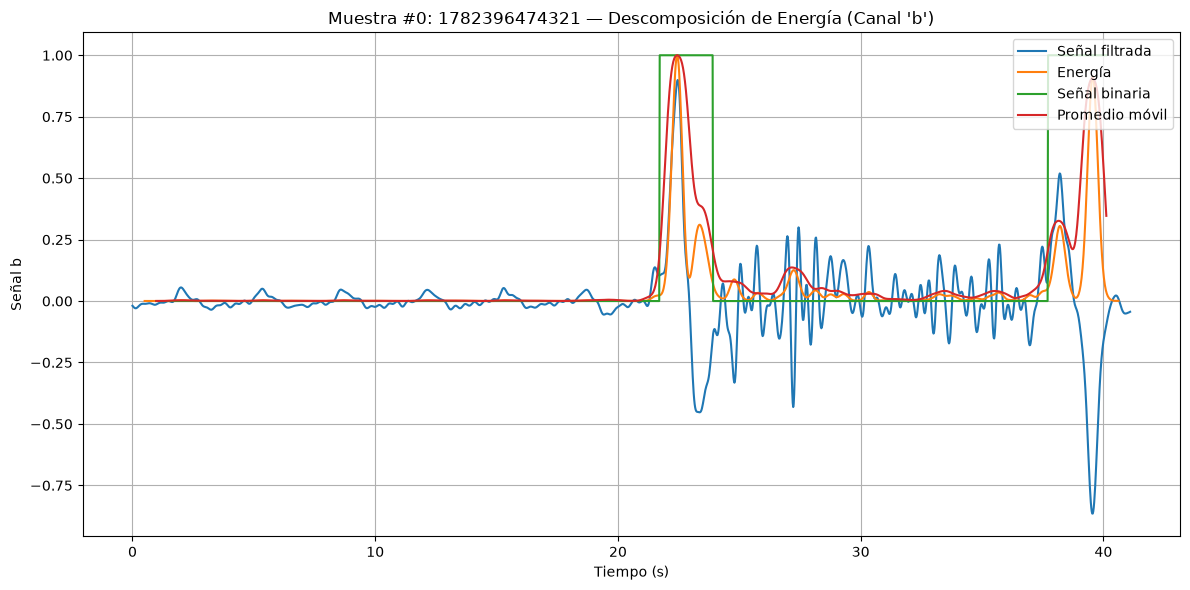

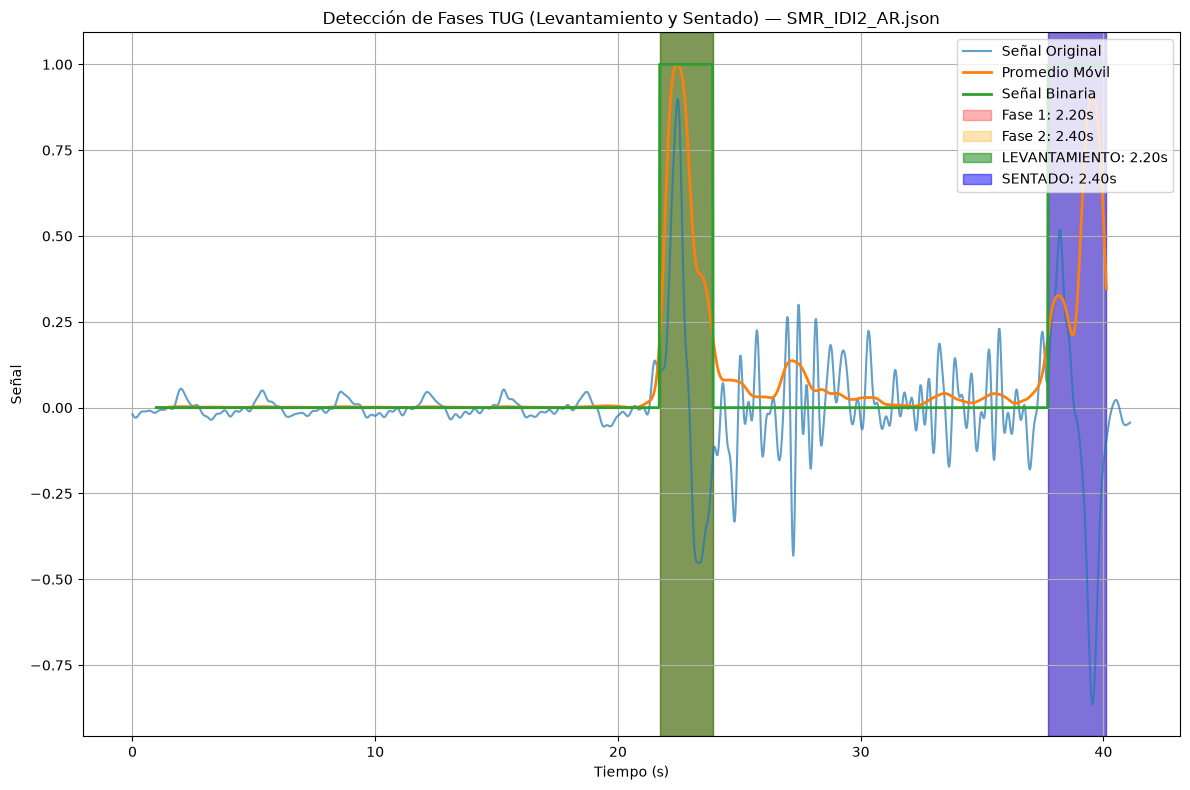

In [11]:
def filter_signal(signal, cutoff_hz=3, fs=50.0, order=20):
    nyquist = 0.5 * fs
    normal_cutoff = cutoff_hz / nyquist
    b, a = butter(order, normal_cutoff, btype="low", analog=False)
    return filtfilt(b, a, signal)

def energy_spectrum(signal, fs=50.0, window_size_samples=50, step_size_samples=1, apply_window=True):
    energies = []
    times = []
    num_samples = len(signal)
    for start in range(0, num_samples - window_size_samples + 1, step_size_samples):
        end = start + window_size_samples
        window = signal[start:end]
        if apply_window:
            window = window * np.hanning(window_size_samples)
        energy = np.sum(window ** 2)
        energies.append(energy)
        t_center = (start + end) / 2 / fs
        times.append(t_center)
    energies = np.array(energies)
    times = np.array(times)
    if np.max(np.abs(energies)) > 0:
        energies = energies / np.max(np.abs(energies))
    return times, energies

def promediomovil(senal, ventana=50, fs=50.0):
    senal = np.array(senal, dtype=float)
    kernel = np.ones(ventana) / ventana
    prom = np.convolve(senal, kernel, mode="valid")
    if np.max(prom) != 0:
        prom = prom / np.max(prom)
    t = (np.arange(len(prom)) + ventana - 1) / fs
    return t, prom

def binary_threshold(signal, threshold=0.2):
    return (signal >= threshold).astype(int)

def detectar_fases_tug(tiempo, senal_binaria, duracion_minima=0.5, umbral_adaptativo=False, pmovil=None):
    tiempo = np.asarray(tiempo, dtype=float)
    senal_binaria = np.asarray(senal_binaria).astype(int)

    def _extraer_pulsos(sig_bin):
        transiciones = np.diff(sig_bin.astype(int))
        indices_subida = np.where(transiciones == 1)[0] + 1
        indices_bajada = np.where(transiciones == -1)[0] + 1

        if sig_bin[0] == 1:
            indices_subida = np.concatenate([[0], indices_subida])
        if sig_bin[-1] == 1:
            indices_bajada = np.concatenate([indices_bajada, [len(sig_bin) - 1]])

        fases_mov = []
        min_indices = min(len(indices_subida), len(indices_bajada))
        for i in range(min_indices):
            inicio_mov = int(indices_subida[i])
            fin_mov = int(indices_bajada[i])
            if inicio_mov < fin_mov:
                t_inicio = float(tiempo[inicio_mov])
                t_fin = float(tiempo[fin_mov])
                duracion = t_fin - t_inicio
                if duracion >= duracion_minima:
                    fases_mov.append({
                        "inicio_tiempo": t_inicio,
                        "fin_tiempo": t_fin,
                        "duracion": duracion,
                        "inicio_indice": inicio_mov,
                        "fin_indice": fin_mov
                    })
        return fases_mov

    fases_movimiento = _extraer_pulsos(senal_binaria)

    if len(fases_movimiento) < 2 and umbral_adaptativo and pmovil is not None:
        n_medio = len(pmovil) // 2
        segunda_mitad = pmovil[n_medio:]
        max_segunda = np.max(segunda_mitad) if len(segunda_mitad) > 0 else 0.0
        if max_segunda > 0.05:
            umbral_local = max(0.08, max_segunda * 0.5)
            binaria_local = (pmovil >= umbral_local).astype(int)
            tramos_locales = _extraer_pulsos(binaria_local)
            if len(fases_movimiento) >= 1:
                t_fin_primera = fases_movimiento[0]["fin_tiempo"]
                candidatos = [t for t in tramos_locales if t["inicio_tiempo"] > t_fin_primera + 1.0]
                if candidatos:
                    fases_movimiento.append(candidatos[-1])

    fases_clasificadas = {
        "levantamiento": None,
        "sentado": None,
        "todas_las_fases": fases_movimiento
    }
    if len(fases_movimiento) >= 1:
        fases_clasificadas["levantamiento"] = fases_movimiento[0]
    if len(fases_movimiento) >= 2:
        fases_clasificadas["sentado"] = fases_movimiento[-1]

    return fases_clasificadas

def graficar_descomposicion_energia_predecesor(time, asignalfiltered, times, energies, t_movil, pmovil, binary, signal, clave_muestra, indice_muestra=0):
    plt.figure(figsize=(12, 6))
    plt.plot(time, asignalfiltered, label="Señal filtrada")
    plt.plot(times, energies, label="Energía")
    plt.plot(t_movil, binary, label="Señal binaria")
    plt.plot(t_movil, pmovil, label="Promedio móvil")
    plt.xlabel("Tiempo (s)")
    plt.ylabel(f"Señal {signal}")
    plt.title(f"Muestra #{indice_muestra}: {clave_muestra} — Descomposición de Energía (Canal '{signal}')")
    plt.grid(True)
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

def graficar_fases_tug(tiempo, senal_original, senal_binaria, t_movil, pmovil, fases, titulo="Detección de Fases TUG"):
    plt.figure(figsize=(12, 8))
    plt.plot(tiempo, senal_original, label="Señal Original", alpha=0.7)
    plt.plot(t_movil, pmovil, label="Promedio Móvil", linewidth=2)
    plt.plot(t_movil, senal_binaria, label="Señal Binaria", linewidth=2)

    colores = ["red", "orange", "purple", "brown"]
    for i, fase in enumerate(fases["todas_las_fases"]):
        color = colores[i % len(colores)]
        plt.axvspan(
            fase["inicio_tiempo"], fase["fin_tiempo"],
            alpha=0.3, color=color,
            label=f"Fase {i+1}: {fase['duracion']:.2f}s"
        )

    if fases["levantamiento"]:
        plt.axvspan(
            fases["levantamiento"]["inicio_tiempo"],
            fases["levantamiento"]["fin_tiempo"],
            alpha=0.5, color="green",
            label=f"LEVANTAMIENTO: {fases['levantamiento']['duracion']:.2f}s"
        )

    if fases["sentado"]:
        plt.axvspan(
            fases["sentado"]["inicio_tiempo"],
            fases["sentado"]["fin_tiempo"],
            alpha=0.5, color="blue",
            label=f"SENTADO: {fases['sentado']['duracion']:.2f}s"
        )

    plt.xlabel("Tiempo (s)")
    plt.ylabel("Señal")
    plt.title(titulo)
    plt.grid(True)
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

def imprimir_resumen_fases(fases):
    print("\n" + "=" * 60)
    print("RESUMEN DE FASES DETECTADAS (LEVANTAMIENTO Y SENTADO)")
    print("=" * 60)
    print(f"Total de fases de movimiento detectadas: {len(fases['todas_las_fases'])}")

    if fases["levantamiento"]:
        lev = fases["levantamiento"]
        print("\nFASE DE LEVANTAMIENTO:")
        print(f"   Tiempo inicio: {lev['inicio_tiempo']:.2f} s")
        print(f"   Tiempo fin:    {lev['fin_tiempo']:.2f} s")
        print(f"   Duración:      {lev['duracion']:.2f} s")
    else:
        print("\nNo se detectó fase de levantamiento")

    if fases["sentado"]:
        sent = fases["sentado"]
        print("\nFASE DE SENTADO:")
        print(f"   Tiempo inicio: {sent['inicio_tiempo']:.2f} s")
        print(f"   Tiempo fin:    {sent['fin_tiempo']:.2f} s")
        print(f"   Duración:      {sent['duracion']:.2f} s")
    else:
        print("\nNo se detectó fase de sentado")

    print("\nDetalle de todas las fases detectadas:")
    for i, f in enumerate(fases["todas_las_fases"]):
        print(f"   Fase {i+1}: {f['inicio_tiempo']:.2f}s - {f['fin_tiempo']:.2f}s (Duración: {f['duracion']:.2f}s)")
    print("=" * 60)

ruta_json_temporal = "/tmp/imu_adaptado_formato_predecesor.json"
exportar_json_formato_predecesor(muestra_archivo, ruta_json_temporal, carpeta_base=CARPETA_DATOS, fs_destino=50.0)

patientdata_pred = cargar_datos_json(ruta_json_temporal)["pruebas"]
claves_pred = list(patientdata_pred.keys())
clave_muestra_pred = claves_pred[0]
sample_pred = patientdata_pred[clave_muestra_pred]["espina_base"]
asignal_pred = np.array([d["b"] for d in sample_pred])
asignal_pred = asignal_pred / max(abs(asignal_pred))
asignalfiltered_pred = filter_signal(asignal_pred, cutoff_hz=3, fs=50.0, order=20)
time_pred = np.array([d["t"] / 1000.0 for d in sample_pred])
times_pred, energies_pred = energy_spectrum(signal=asignalfiltered_pred, fs=50, window_size_samples=50, step_size_samples=1, apply_window=True)
t_movil_pred, pmovil_pred = promediomovil(energies_pred, ventana=50, fs=50)
binary_pred = binary_threshold(pmovil_pred, threshold=0.2)
fases_pred = detectar_fases_tug(t_movil_pred, binary_pred, duracion_minima=0.5, umbral_adaptativo=False)

pruebas_actual = cargar_prueba_adaptada(muestra_archivo, carpeta_base=CARPETA_DATOS, fs_destino=50.0)
clave_act, time_act, asignal_act = extraer_senal(pruebas_actual, 0, "espina_base", "b")
asignalfiltered_act = filter_signal(asignal_act, cutoff_hz=3, fs=50.0, order=20)
times_act, energies_act = energy_spectrum(asignalfiltered_act, fs=50.0, window_size_samples=50, step_size_samples=1, apply_window=True)
t_movil_act, pmovil_act = promediomovil(energies_act, ventana=50, fs=50.0)
binary_act = binary_threshold(pmovil_act, threshold=0.2)
fases_act = detectar_fases_tug(t_movil_act, binary_act, duracion_minima=0.5, umbral_adaptativo=False)

print("=" * 75)
print("VERIFICACIÓN DE EQUIVALENCIA EXACTA: CÓDIGO PREDECESOR VS. PIPELINE ACTUAL")
print("=" * 75)
print(f"Archivo evaluado:                            {muestra_archivo}")
print(f"Diferencia máxima en señal filtrada:         {np.max(np.abs(asignalfiltered_pred - asignalfiltered_act)):.6e}")
print(f"Diferencia máxima en espectro de energía:    {np.max(np.abs(energies_pred - energies_act)):.6e}")
print(f"Diferencia máxima en promedio móvil:         {np.max(np.abs(pmovil_pred - pmovil_act)):.6e}")
print(f"Coincidencia exacta en señal binaria (100%): {np.array_equal(binary_pred, binary_act)}")
print(f"Coincidencia exacta en fases detectadas:     {fases_pred == fases_act}")
print("=" * 75)

imprimir_resumen_fases(fases_act)
graficar_descomposicion_energia_predecesor(
    time_act, asignalfiltered_act, times_act, energies_act, t_movil_act, pmovil_act, binary_act,
    signal="b", clave_muestra=clave_act, indice_muestra=0
)
graficar_fases_tug(
    time_act, asignalfiltered_act, binary_act, t_movil_act, pmovil_act, fases_act,
    titulo=f"Detección de Fases TUG (Levantamiento y Sentado) — {muestra_archivo}"
)

## MÓDULO 6: Detección y Caracterización de la Fase de Giro (Velocidad Angular)

De acuerdo con la evidencia reportada en la literatura de referencia (*Molero Mateo et al.*) y las conclusiones de las Reuniones 6 y 8, la transición de **giro de 180° alrededor del cono** y el **giro previo al sentado** constituyen los intervalos biomecánicos de mayor poder discriminante entre pacientes con Enfermedad de Parkinson en estadios tempranos y sujetos controles, debido a que exigen coordinación axial, acoplamiento oculomotor-espinal y regulación del centro de masa durante el cambio de dirección.

En los registros de brigada (donde el sensor lumbar `espina_base` se encuentra montado con el eje X alineado sobre la vertical gravitatoria), la rotación en el plano transversal horizontal (*yaw* o guiñada) es capturada directamente por el canal `gyroscope.x`, correspondiente a la llave `signal = "a"` del esquema adaptado (mientras que en las pruebas preliminares de laboratorio con distinta orientación de montaje se observaba en `signal = "g"`).

La función `detectar_intervalos_giro` aplica sobre el canal `a` de `espina_base` el mismo pipeline del proyecto predecesor (Celdas 35 y 42): filtrado pasa-bajos Butterworth de orden 20 a $3\text{ Hz}$, cálculo de energía en ventana deslizante de 50 muestras con ponderación de Hanning, suavizado por media móvil de 50 muestras y umbralización binaria en $0,2$. Adicionalmente, además de reportar la velocidad pico normalizada en el intervalo $[0, 1]$, la función recupera la velocidad angular pico física en grados por segundo ($^\circ/\text{s}$) dividiendo las cuentas del esquema adaptado por el factor de escala $1000,0$, conservando la magnitud absoluta necesaria para diferenciar la bradicinesia rotacional parkinsoniana.

Se generan a continuación las dos representaciones gráficas correspondientes al proyecto predecesor: la gráfica de cortes en el tiempo para la fase de giro (Celda 42) y la gráfica detallada con las cuatro curvas del procesamiento energético y el sombreado individual de cada giro detectado.

In [12]:
muestra_giro = "SMR_IDI47_R.json"


RESUMEN DE INTERVALOS DE GIRO DETECTADOS (MÓDULO 6)
Total de giros identificados: 4

GIRO #1:
   Tiempo inicio:       8.42 s
   Tiempo fin:          9.82 s
   Duración del giro:   1.40 s
   Velocidad pico:      0.61 (u. norm.) | 131.11 °/s

GIRO #2:
   Tiempo inicio:       12.86 s
   Tiempo fin:          14.46 s
   Duración del giro:   1.60 s
   Velocidad pico:      0.93 (u. norm.) | 191.19 °/s

GIRO #3:
   Tiempo inicio:       35.22 s
   Tiempo fin:          36.70 s
   Duración del giro:   1.48 s
   Velocidad pico:      0.49 (u. norm.) | 163.09 °/s

GIRO #4:
   Tiempo inicio:       39.60 s
   Tiempo fin:          41.22 s
   Duración del giro:   1.62 s
   Velocidad pico:      0.78 (u. norm.) | 165.76 °/s


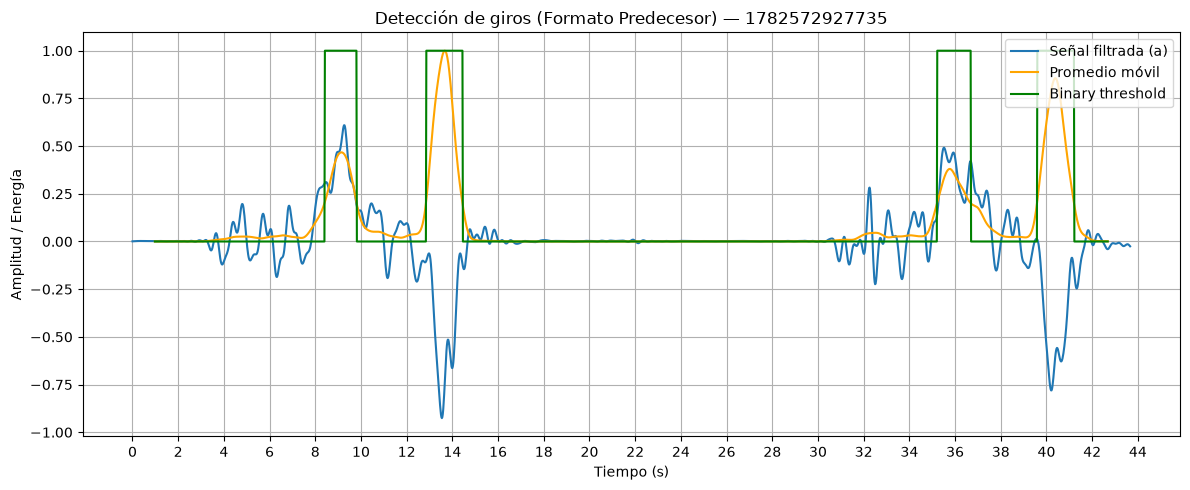

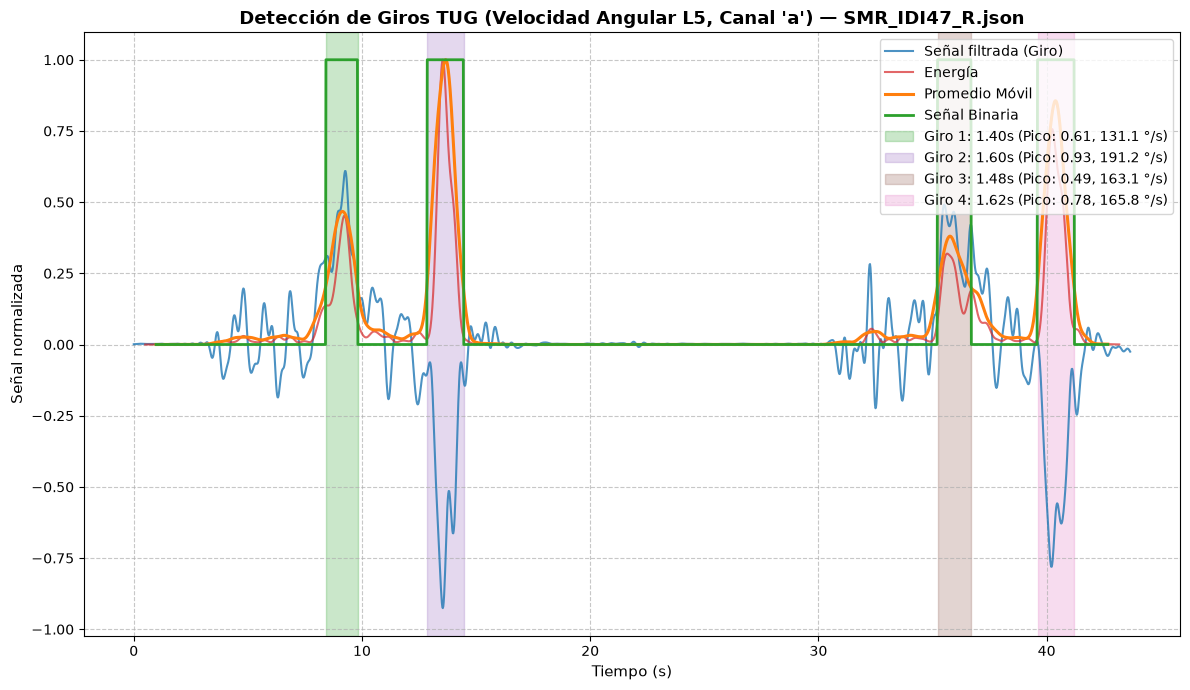

In [13]:
def detectar_intervalos_giro(tiempo, senal_gyro, fs=50.0, umbral=0.2, duracion_minima=0.5, ventana_energia=50, senal_gyro_fisica=None):
    tiempo = np.asarray(tiempo, dtype=float)
    sig = np.asarray(senal_gyro, dtype=float)

    sig_filtered = filter_signal(sig, cutoff_hz=3, fs=fs, order=20)
    t_e, energies = energy_spectrum(
        sig_filtered, fs=fs, window_size_samples=ventana_energia,
        step_size_samples=1, apply_window=True
    )
    t_movil, pmovil = promediomovil(energies, ventana=ventana_energia, fs=fs)
    binary = binary_threshold(pmovil, threshold=umbral)

    cambios = np.diff(binary.astype(int))
    inicios = np.where(cambios == 1)[0] + 1
    fines = np.where(cambios == -1)[0] + 1

    if binary[0] == 1:
        inicios = np.insert(inicios, 0, 0)
    if binary[-1] == 1:
        fines = np.append(fines, len(binary) - 1)

    intervalos = []
    for ini, fin in zip(inicios, fines):
        if ini < fin:
            t_ini = float(t_movil[min(ini, len(t_movil) - 1)])
            t_fin = float(t_movil[min(fin, len(t_movil) - 1)])
            dur = t_fin - t_ini
            if dur >= duracion_minima:
                mask = (tiempo >= t_ini) & (tiempo <= t_fin)
                pico_vel_norm = float(np.max(np.abs(sig_filtered[mask]))) if np.any(mask) else 0.0
                if senal_gyro_fisica is not None and np.any(mask):
                    pico_vel_deg_s = float(np.max(np.abs(senal_gyro_fisica[mask])))
                else:
                    pico_vel_deg_s = np.nan
                intervalos.append({
                    "giro_num": len(intervalos) + 1,
                    "inicio": t_ini,
                    "fin": t_fin,
                    "duracion": dur,
                    "velocidad_pico": pico_vel_norm,
                    "velocidad_pico_deg_s": pico_vel_deg_s
                })

    return {
        "intervalos": intervalos,
        "t_movil": t_movil,
        "t_e": t_e,
        "energies": energies,
        "pmovil": pmovil,
        "binary": binary,
        "sig_filtered": sig_filtered
    }

def graficar_cortes_giro_predecesor(time, sig_filtered, t_movil, pmovil, binary, clave_muestra, signal="a"):
    plt.figure(figsize=(12, 5))
    plt.plot(time, sig_filtered, label=f"Señal filtrada ({signal})")
    plt.plot(t_movil, pmovil, label="Promedio móvil", color="orange")
    plt.plot(t_movil, binary, label="Binary threshold", color="green")
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Amplitud / Energía")
    plt.title(f"Detección de giros (Formato Predecesor) — {clave_muestra}")
    plt.grid(True)
    plt.legend(loc="upper right")
    paso_ticks = 2 if max(time) > 25 else 1
    plt.xticks(np.arange(0, max(time) + 1, paso_ticks))
    plt.tight_layout()
    plt.show()

def graficar_giros_tug(tiempo, sig_filtered, t_e, energies, t_movil, pmovil, binary, intervalos_giro, titulo="Detección de Giros TUG"):
    plt.figure(figsize=(12, 7))
    plt.plot(tiempo, sig_filtered, label="Señal filtrada (Giro)", color="tab:blue", alpha=0.8)
    plt.plot(t_e, energies, label="Energía", color="tab:red", alpha=0.7)
    plt.plot(t_movil, pmovil, label="Promedio Móvil", color="tab:orange", linewidth=2.2)
    plt.plot(t_movil, binary, label="Señal Binaria", color="tab:green", linewidth=2.0)

    colores_giro = ["#2ca02c", "#9467bd", "#8c564b", "#e377c2", "#17becf", "#bcbd22"]
    for i, g in enumerate(intervalos_giro):
        c = colores_giro[i % len(colores_giro)]
        etiqueta_deg = f", {g['velocidad_pico_deg_s']:.1f} °/s" if not np.isnan(g.get("velocidad_pico_deg_s", np.nan)) else ""
        plt.axvspan(
            g["inicio"], g["fin"], alpha=0.25, color=c,
            label=f"Giro {g['giro_num']}: {g['duracion']:.2f}s (Pico: {g['velocidad_pico']:.2f}{etiqueta_deg})"
        )

    plt.xlabel("Tiempo (s)", fontsize=11)
    plt.ylabel("Señal normalizada", fontsize=11)
    plt.title(titulo, fontsize=13, fontweight="bold")
    plt.grid(True, linestyle="--", alpha=0.7)
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

def imprimir_resumen_giros(intervalos_giro):
    print("\n" + "=" * 65)
    print("RESUMEN DE INTERVALOS DE GIRO DETECTADOS (MÓDULO 6)")
    print("=" * 65)
    print(f"Total de giros identificados: {len(intervalos_giro)}")
    for g in intervalos_giro:
        deg_info = f" | {g['velocidad_pico_deg_s']:.2f} °/s" if not np.isnan(g.get("velocidad_pico_deg_s", np.nan)) else ""
        print(f"\nGIRO #{g['giro_num']}:")
        print(f"   Tiempo inicio:       {g['inicio']:.2f} s")
        print(f"   Tiempo fin:          {g['fin']:.2f} s")
        print(f"   Duración del giro:   {g['duracion']:.2f} s")
        print(f"   Velocidad pico:      {g['velocidad_pico']:.2f} (u. norm.){deg_info}")
    print("=" * 65)

pruebas_giro = cargar_prueba_adaptada(muestra_giro, carpeta_base=CARPETA_DATOS, fs_destino=50.0)
clave_g, time_g, asignal_g = extraer_senal(pruebas_giro, 0, "espina_base", "a", normalizar=True)
_, _, asignal_g_cuentas = extraer_senal(pruebas_giro, 0, "espina_base", "a", normalizar=False)
asignal_g_deg_s = asignal_g_cuentas / 1000.0

res_giros = detectar_intervalos_giro(
    time_g, asignal_g, fs=50.0, umbral=0.2, duracion_minima=0.5,
    senal_gyro_fisica=asignal_g_deg_s
)
imprimir_resumen_giros(res_giros["intervalos"])
graficar_cortes_giro_predecesor(
    time_g, res_giros["sig_filtered"], res_giros["t_movil"],
    res_giros["pmovil"], res_giros["binary"], clave_muestra=clave_g, signal="a"
)
graficar_giros_tug(
    time_g, res_giros["sig_filtered"], res_giros["t_e"], res_giros["energies"],
    res_giros["t_movil"], res_giros["pmovil"], res_giros["binary"],
    res_giros["intervalos"],
    titulo=f"Detección de Giros TUG (Velocidad Angular L5, Canal 'a') — {muestra_giro}"
)

## MÓDULO 7: Gráfica Compuesta Superpuesta y Segmentación Contigua de las Cinco Fases del TUG

En la Reunión 8 (`[00:47:43]` y `[00:54:29]`), el director del proyecto solicitó construir una representación gráfica compuesta que superponga en un mismo eje temporal la envolvente energética de flexo-extensión de tronco (`espina_base`, canal `b`: levantarse y sentarse) y la envolvente energética de rotación axial (`espina_base`, canal `a`: giros de 180°), trazando líneas verticales de corte (`axvline`) que demuestren cómo la totalidad del tiempo de ejecución de una prueba TUG queda particionada en cinco fases biomecánicas contiguas sin vacíos ni solapamientos ambiguos.

Tal como se documentó en el análisis exploratorio de los datos (`Analisis_IMUs.md` §3), numerosas grabaciones de brigada contienen dos repeticiones completas de la prueba TUG ejecutadas de manera consecutiva dentro del mismo archivo (por ejemplo, `SMR_ID47_IMU_TUG_R.json` presenta 4 giros: los giros 1 y 2 pertenecen a la primera repetición entre los 6 y 15 segundos, y los giros 3 y 4 pertenecen a la segunda repetición entre los 33 y 42 segundos). Si se tomara ingenuamente el primer pulso de `canal b` como levantamiento y el último pulso del archivo como sentado en una grabación con dos repeticiones, se mezclarían el inicio de la primera prueba con el final de la segunda.

Para resolver rigurosamente tanto las grabaciones de toma única como las grabaciones con repeticiones consecutivas, la función `segmentar_cinco_fases_tug` empareja de forma coherente los eventos de un ciclo completo de TUG de acuerdo con la siguiente partición biomecánica:

| Fase del Test TUG | Nombre Clínico | Frontera de Inicio | Frontera de Finalización | Canal Rector en L5 (`espina_base`) |
| :---: | :--- | :--- | :--- | :--- |
| **Fase 1** | Levantamiento (*Sit-to-Stand*) | Inicio del primer pulso en canal `b` ($t_{\text{lev,ini}}$) | Fin del primer pulso en canal `b` ($t_{\text{lev,fin}}$) | Giróscopo eje Y (`signal = "b"`) |
| **Fase 2** | Caminata de Ida (*Forward Gait*) | Fin de la fase de levantamiento ($t_{\text{lev,fin}}$) | Inicio del giro de 180° en el cono ($t_{\text{giro1,ini}}$) | Transición locomotora entre pulsos de L5 |
| **Fase 3** | Giro 1 en el Cono (*180° Turn*) | Inicio del primer lóbulo en canal `a` ($t_{\text{giro1,ini}}$) | Fin del primer lóbulo en canal `a` ($t_{\text{giro1,fin}}$) | Giróscopo eje X (`signal = "a"`) |
| **Fase 4** | Caminata de Vuelta (*Return Gait*) | Fin del giro en el cono ($t_{\text{giro1,fin}}$) | Inicio del giro previo a la silla ($t_{\text{giro2,ini}}$) | Transición locomotora de retorno |
| **Fase 5** | Giro 2 y Sentado (*Turn-to-Sit & Stand-to-Sit*) | Inicio del segundo giro ($t_{\text{giro2,ini}}$) | Fin del descenso postural en la silla ($t_{\text{sent,fin}}$) | Combinación de canales `a` y `b` |

In [14]:
# Parámetros de Visualización de las 5 Fases TUG (MÓDULO 7)
archivos_5fases_demo = ["SMR_IDI1_BF.json", "SMR_IDI47_R.json"]
zoom_primer_ciclo = True

SEGMENTACIÓN CONTIGUA DE LAS 5 FASES TUG (MÓDULO 7) — SMR_IDI1_BF.json


,num,codigo,nombre,inicio,fin,duracion
0,1,levantamiento,Fase 1: Levantamiento,2.22,4.96,2.74
1,2,caminata_ida,Fase 2: Caminata de Ida,4.96,4.96,0.00
2,3,giro_1,Fase 3: Giro 1 (Cono 180°),1.04,3.26,2.22
3,4,caminata_vuelta,Fase 4: Caminata de Vuelta,3.26,10.40,7.14
4,5,giro2_y_sentado,Fase 5: Giro 2 y Sentado,10.40,11.70,1.30


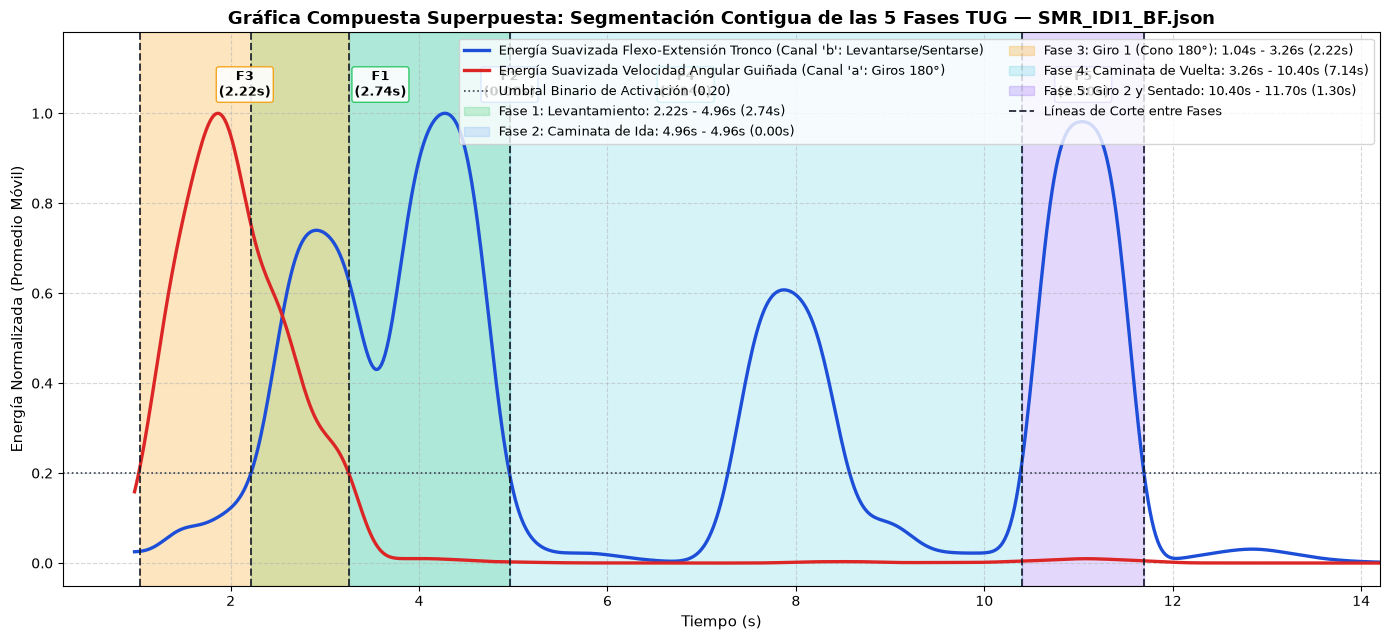

SEGMENTACIÓN CONTIGUA DE LAS 5 FASES TUG (MÓDULO 7) — SMR_IDI47_R.json


,num,codigo,nombre,inicio,fin,duracion
0,1,levantamiento,Fase 1: Levantamiento,3.18,5.12,1.94
1,2,caminata_ida,Fase 2: Caminata de Ida,5.12,8.42,3.30
2,3,giro_1,Fase 3: Giro 1 (Cono 180°),8.42,9.82,1.40
3,4,caminata_vuelta,Fase 4: Caminata de Vuelta,9.82,12.86,3.04
4,5,giro2_y_sentado,Fase 5: Giro 2 y Sentado,12.86,15.88,3.02


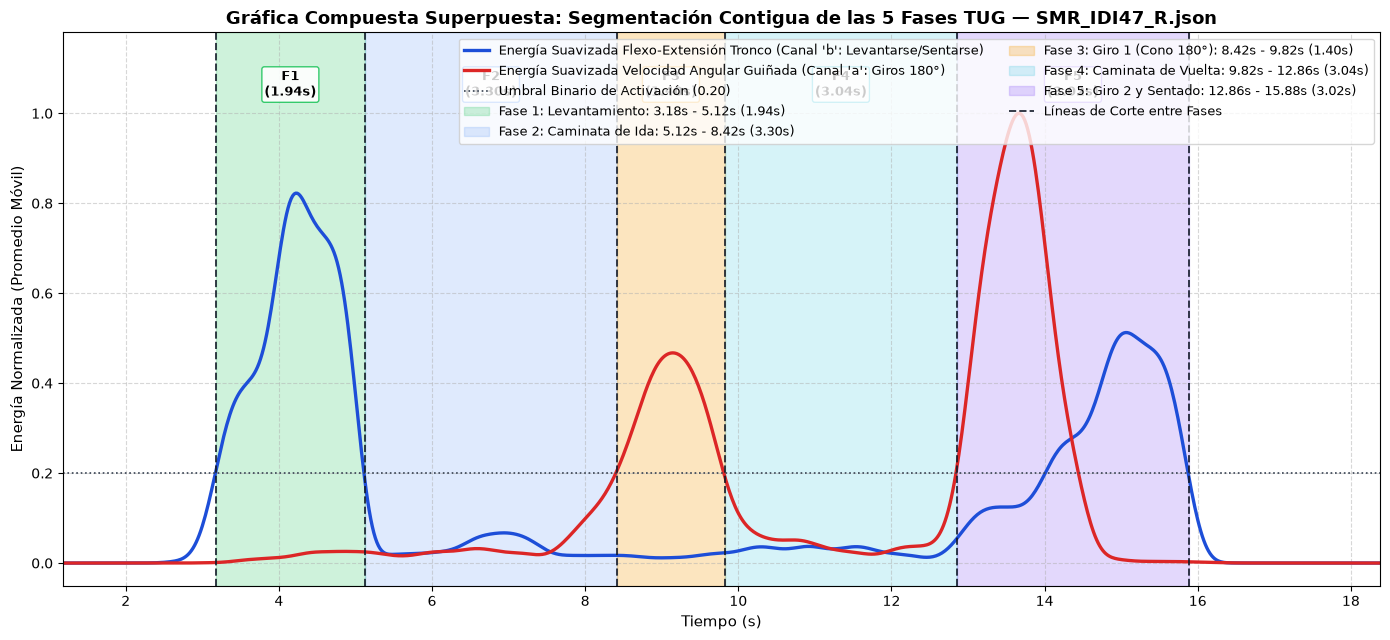

In [15]:
def segmentar_cinco_fases_tug(pruebas_dict, indice_muestra=0, fs=50.0, umbral=0.2, duracion_minima=0.5):
    clave, time_b, sig_b = extraer_senal(pruebas_dict, indice_muestra, "espina_base", "b", normalizar=True)
    sig_b_filt = filter_signal(sig_b, cutoff_hz=3, fs=fs, order=20)
    t_eb, energies_b = energy_spectrum(sig_b_filt, fs=fs, window_size_samples=50, step_size_samples=1, apply_window=True)
    t_mb, pmovil_b = promediomovil(energies_b, ventana=50, fs=fs)
    bin_b = binary_threshold(pmovil_b, threshold=umbral)
    fases_b = detectar_fases_tug(t_mb, bin_b, duracion_minima=duracion_minima, umbral_adaptativo=True, pmovil=pmovil_b)

    _, time_a, sig_a = extraer_senal(pruebas_dict, indice_muestra, "espina_base", "a", normalizar=True)
    _, _, sig_a_cuentas = extraer_senal(pruebas_dict, indice_muestra, "espina_base", "a", normalizar=False)
    res_giros = detectar_intervalos_giro(
        time_a, sig_a, fs=fs, umbral=umbral, duracion_minima=duracion_minima,
        senal_gyro_fisica=sig_a_cuentas / 1000.0
    )

    todos_pulsos_b = fases_b["todas_las_fases"]
    giros = res_giros["intervalos"]

    lev = fases_b["levantamiento"]
    sent = fases_b["sentado"]
    giro1 = None
    giro2 = None

    if lev and len(giros) >= 1:
        giros_post_lev = [g for g in giros if g["fin"] > lev["inicio_tiempo"] + 0.5]
        if not giros_post_lev:
            giros_post_lev = giros
        giro1 = giros_post_lev[0]
        if len(giros_post_lev) >= 2:
            giro2 = giros_post_lev[1]

        pulsos_cierre_ciclo1 = [
            p for p in todos_pulsos_b
            if p["inicio_tiempo"] > giro1["inicio"] and (
                giro2 is None or abs(p["inicio_tiempo"] - giro2["inicio"]) <= 6.0 or p["fin_tiempo"] >= giro2["inicio"]
            )
        ]
        if pulsos_cierre_ciclo1 and len(giros_post_lev) >= 3:
            sent = pulsos_cierre_ciclo1[0]

    fases_5 = []
    if lev:
        t_f1_ini = lev["inicio_tiempo"]
        t_f1_fin = lev["fin_tiempo"]
        fases_5.append({
            "num": 1, "codigo": "levantamiento", "nombre": "Fase 1: Levantamiento",
            "inicio": t_f1_ini, "fin": t_f1_fin, "duracion": max(0.0, t_f1_fin - t_f1_ini)
        })

        if giro1:
            t_f2_ini = t_f1_fin
            t_f2_fin = max(t_f2_ini, giro1["inicio"])
            fases_5.append({
                "num": 2, "codigo": "caminata_ida", "nombre": "Fase 2: Caminata de Ida",
                "inicio": t_f2_ini, "fin": t_f2_fin, "duracion": max(0.0, t_f2_fin - t_f2_ini)
            })

            t_f3_ini = giro1["inicio"]
            t_f3_fin = giro1["fin"]
            fases_5.append({
                "num": 3, "codigo": "giro_1", "nombre": "Fase 3: Giro 1 (Cono 180°)",
                "inicio": t_f3_ini, "fin": t_f3_fin, "duracion": max(0.0, t_f3_fin - t_f3_ini)
            })

            if giro2:
                t_f4_ini = t_f3_fin
                t_f4_fin = max(t_f4_ini, giro2["inicio"])
                fases_5.append({
                    "num": 4, "codigo": "caminata_vuelta", "nombre": "Fase 4: Caminata de Vuelta",
                    "inicio": t_f4_ini, "fin": t_f4_fin, "duracion": max(0.0, t_f4_fin - t_f4_ini)
                })

                t_f5_ini = giro2["inicio"]
                t_f5_fin = max(giro2["fin"], sent["fin_tiempo"] if sent and sent["fin_tiempo"] >= giro2["inicio"] else giro2["fin"])
                fases_5.append({
                    "num": 5, "codigo": "giro2_y_sentado", "nombre": "Fase 5: Giro 2 y Sentado",
                    "inicio": t_f5_ini, "fin": t_f5_fin, "duracion": max(0.0, t_f5_fin - t_f5_ini)
                })
            elif sent and sent["inicio_tiempo"] > t_f3_fin:
                t_f4_ini = t_f3_fin
                t_f4_fin = sent["inicio_tiempo"]
                fases_5.append({
                    "num": 4, "codigo": "caminata_vuelta", "nombre": "Fase 4: Caminata de Vuelta",
                    "inicio": t_f4_ini, "fin": t_f4_fin, "duracion": max(0.0, t_f4_fin - t_f4_ini)
                })
                fases_5.append({
                    "num": 5, "codigo": "giro2_y_sentado", "nombre": "Fase 5: Giro 2 y Sentado",
                    "inicio": sent["inicio_tiempo"], "fin": sent["fin_tiempo"], "duracion": sent["duracion"]
                })

    return {
        "clave": clave,
        "fases_5": fases_5,
        "fases_b": fases_b,
        "res_giros": res_giros,
        "t_mb": t_mb,
        "pmovil_b": pmovil_b,
        "bin_b": bin_b,
        "sig_b_filt": sig_b_filt,
        "time_b": time_b,
        "giro1": giro1,
        "giro2": giro2,
        "lev": lev,
        "sent": sent
    }

def graficar_fases_superpuestas_tug(seg_res, nombre_archivo, zoom_ciclo1=True):
    t_mb = seg_res["t_mb"]
    pmovil_b = seg_res["pmovil_b"]
    t_ma = seg_res["res_giros"]["t_movil"]
    pmovil_a = seg_res["res_giros"]["pmovil"]
    fases_5 = seg_res["fases_5"]

    fig, ax = plt.subplots(figsize=(14, 6.5))

    ax.plot(t_mb, pmovil_b, label="Energía Suavizada Flexo-Extensión Tronco (Canal 'b': Levantarse/Sentarse)", color="#1d4ed8", linewidth=2.4)
    ax.plot(t_ma, pmovil_a, label="Energía Suavizada Velocidad Angular Guiñada (Canal 'a': Giros 180°)", color="#dc2626", linewidth=2.4, linestyle="-")
    ax.axhline(0.2, color="#374151", linestyle=":", linewidth=1.2, label="Umbral Binario de Activación (0.20)")

    paleta_fases = {
        1: ("#22c55e", 0.22),
        2: ("#3b82f6", 0.16),
        3: ("#f59e0b", 0.26),
        4: ("#06b6d4", 0.16),
        5: ("#8b5cf6", 0.24)
    }

    cortes_tiempo = set()
    for f in fases_5:
        color_f, alpha_f = paleta_fases.get(f["num"], ("#9ca3af", 0.2))
        ax.axvspan(
            f["inicio"], f["fin"], color=color_f, alpha=alpha_f,
            label=f"{f['nombre']}: {f['inicio']:.2f}s - {f['fin']:.2f}s ({f['duracion']:.2f}s)"
        )
        cortes_tiempo.add(round(f["inicio"], 4))
        cortes_tiempo.add(round(f["fin"], 4))
        t_centro = 0.5 * (f["inicio"] + f["fin"])
        ax.text(
            t_centro, 1.03, f"F{f['num']}\n({f['duracion']:.2f}s)",
            ha="center", va="bottom", fontsize=9, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor=color_f, alpha=0.9)
        )

    for idx_c, tc in enumerate(sorted(cortes_tiempo)):
        ax.axvline(
            tc, color="#111827", linestyle="--", linewidth=1.4, alpha=0.85,
            label="Líneas de Corte entre Fases" if idx_c == 0 else ""
        )

    if zoom_ciclo1 and fases_5:
        margen_ini = max(0.0, fases_5[0]["inicio"] - 2.0)
        margen_fin = min(max(t_mb[-1], t_ma[-1]), fases_5[-1]["fin"] + 2.5)
        ax.set_xlim(margen_ini, margen_fin)

    ax.set_ylim(-0.05, 1.18)
    ax.set_xlabel("Tiempo (s)", fontsize=11)
    ax.set_ylabel("Energía Normalizada (Promedio Móvil)", fontsize=11)
    ax.set_title(f"Gráfica Compuesta Superpuesta: Segmentación Contigua de las 5 Fases TUG — {nombre_archivo}", fontsize=13, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper right", fontsize=9, ncol=2)
    plt.tight_layout()
    plt.show()

for archivo_demo in archivos_5fases_demo:
    pruebas_demo = cargar_prueba_adaptada(archivo_demo, carpeta_base=CARPETA_DATOS, fs_destino=50.0)
    seg_demo = segmentar_cinco_fases_tug(pruebas_demo, indice_muestra=0, fs=50.0)
    print("=" * 80)
    print(f"SEGMENTACIÓN CONTIGUA DE LAS 5 FASES TUG (MÓDULO 7) — {archivo_demo}")
    print("=" * 80)
    df_fases_5 = pd.DataFrame(seg_demo["fases_5"])
    display(df_fases_5)
    graficar_fases_superpuestas_tug(seg_demo, archivo_demo, zoom_ciclo1=True)

## MÓDULO 8: Análisis de Caminata, Detección de Eventos de Paso (`SWING` / `STANCE`) y Etiquetado por Fase TUG

Este módulo integra la totalidad de los algoritmos de análisis de marcha desarrollados en las celdas 20, 38 y 47 (`JOANDGOAG`) del proyecto predecesor sobre los sensores de tobillo izquierdo (`lateral = "izquierda"`) y tobillo derecho (`lateral = "derecha"`), e incorpora la mejora metodológica solicitada por el director del proyecto en la Reunión 8 (`[00:51:01]`–`[00:52:20]`): la clasificación automática de cada evento de paso según la fase de la prueba TUG en la que ocurre (`fase_tug`).

En primer lugar, se obtiene el perfil energético de deambulación en los tobillos (equivalente a la Celda 20 del código predecesor), aplicando el filtro pasa-bajos Butterworth de orden 20 ($3\text{ Hz}$), el espectro de energía de 50 muestras y la media móvil sobre la velocidad angular del tobillo (`signal = "g"`) para visualizar los trenes de actividad locomotora durante la ida y el regreso.

En segundo lugar, se ejecuta la detección de subfases de apoyo (`STANCE`) y balanceo (`SWING`) mediante extremos locales de aceleración en los tobillos (`signal = "x"`, filtrado con Butterworth de orden 20 a $3\text{ Hz}$). Siguiendo exactamente la formulación de las Celdas 38 y 47 del predecesor, la función `scipy.signal.find_peaks` opera con una distancia mínima entre pasos `min_stride_s = 0.4` segundos ($20\text{ muestras}$ a $50\text{ Hz}$) y una prominencia relativa de `0.20 * max(|s|)` sobre el registro completo o `0.25 * max(|s_seg|)` sobre los tramos recortados de caminata (`detectar_pasos_intervalo`), identificando los picos positivos de contacto inicial (*Heel Strike* $\rightarrow$ `STANCE_START`) y los valles negativos de despegue (*Toe Off* $\rightarrow$ `SWING_START`).

Finalmente, para cada subfase detectada (`STANCE` o `SWING`), se evalúa su instante central $t_c = (t_{\text{inicio}} + t_{\text{fin}})/2$ frente a los intervalos de las cinco fases obtenidos en el Módulo 7, asignando la columna `fase_tug` (`Fase 1: Levantamiento`, `Fase 2: Caminata de Ida`, `Fase 3: Giro 1 (Cono 180°)`, `Fase 4: Caminata de Vuelta`, `Fase 5: Giro 2 y Sentado`). Esta columna permite cuantificar directamente cuántos eventos de paso ejecuta el sujeto durante el giro de 180° frente a los ejecutados durante la marcha rectilínea.

In [16]:
# Parámetros de Detección de Pasos y Marcha (MÓDULO 8)
archivo_pasos_demo = "SMR_IDI1_BF.json"
min_stride_segundos = 0.35
factor_prominencia = 0.20

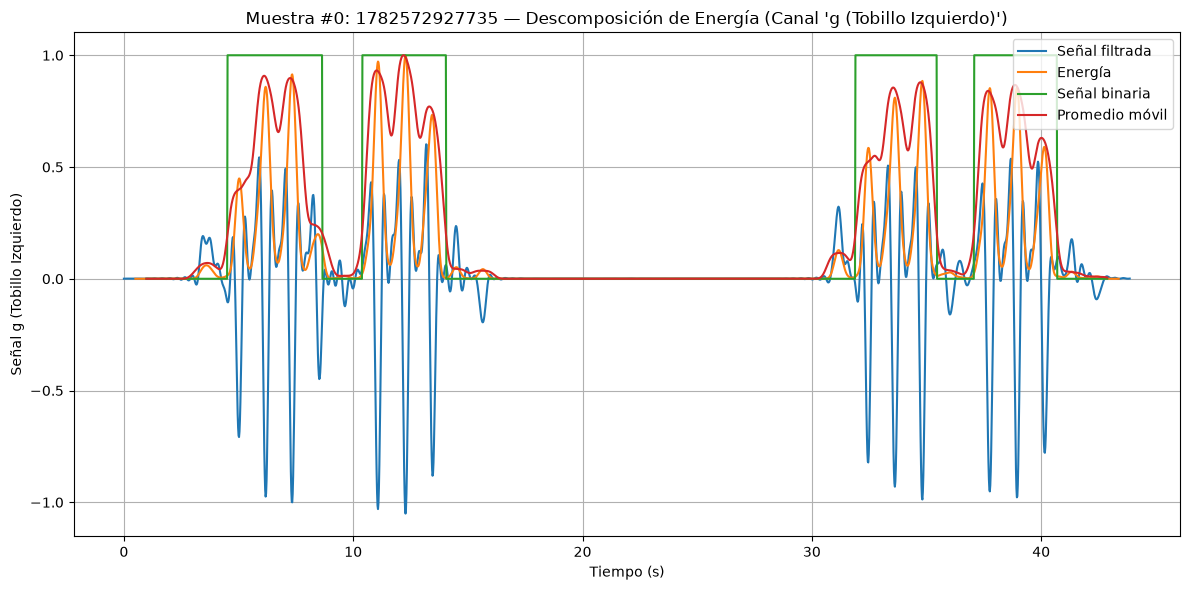

DETECCIÓN DE EVENTOS SWING / STANCE Y CLASIFICACIÓN POR FASE TUG — TOBILLO IZQUIERDA


,paso_idx,fase_paso,inicio_s,fin_s,duracion_s,fase_tug
0,1,STANCE,5.10,5.60,0.50,Fase 2: Caminata de Ida
1,2,SWING,5.60,5.82,0.22,Fase 2: Caminata de Ida
2,3,STANCE,5.82,6.04,0.22,Fase 2: Caminata de Ida
3,4,SWING,6.04,6.28,0.24,Fase 2: Caminata de Ida
4,5,STANCE,6.28,6.78,0.50,Fase 2: Caminata de Ida
5,6,SWING,6.78,6.96,0.18,Fase 2: Caminata de Ida
6,7,STANCE,6.96,7.18,0.22,Fase 2: Caminata de Ida
7,8,SWING,7.18,7.42,0.24,Fase 2: Caminata de Ida
8,9,STANCE,7.42,7.96,0.54,Fase 2: Caminata de Ida
9,10,SWING,7.96,8.14,0.18,Fase 2: Caminata de Ida



Resumen de eventos STANCE y SWING por fase TUG (IZQUIERDA):


,fase_tug,fase_paso,Num_Subfases,Duracion_Media_s,Duracion_Total_s
0,Fase 2: Caminata de Ida,STANCE,6,0.37,2.22
1,Fase 2: Caminata de Ida,SWING,5,0.21,1.06
2,Fase 3: Giro 1 (Cono 180°),STANCE,1,0.90,0.90
3,Fase 3: Giro 1 (Cono 180°),SWING,1,0.24,0.24
4,Fase 4: Caminata de Vuelta,STANCE,4,0.37,1.48
5,Fase 4: Caminata de Vuelta,SWING,4,0.48,1.90
6,Fase 5: Giro 2 y Sentado,STANCE,1,0.22,0.22
7,Fase 5: Giro 2 y Sentado,SWING,2,0.21,0.42


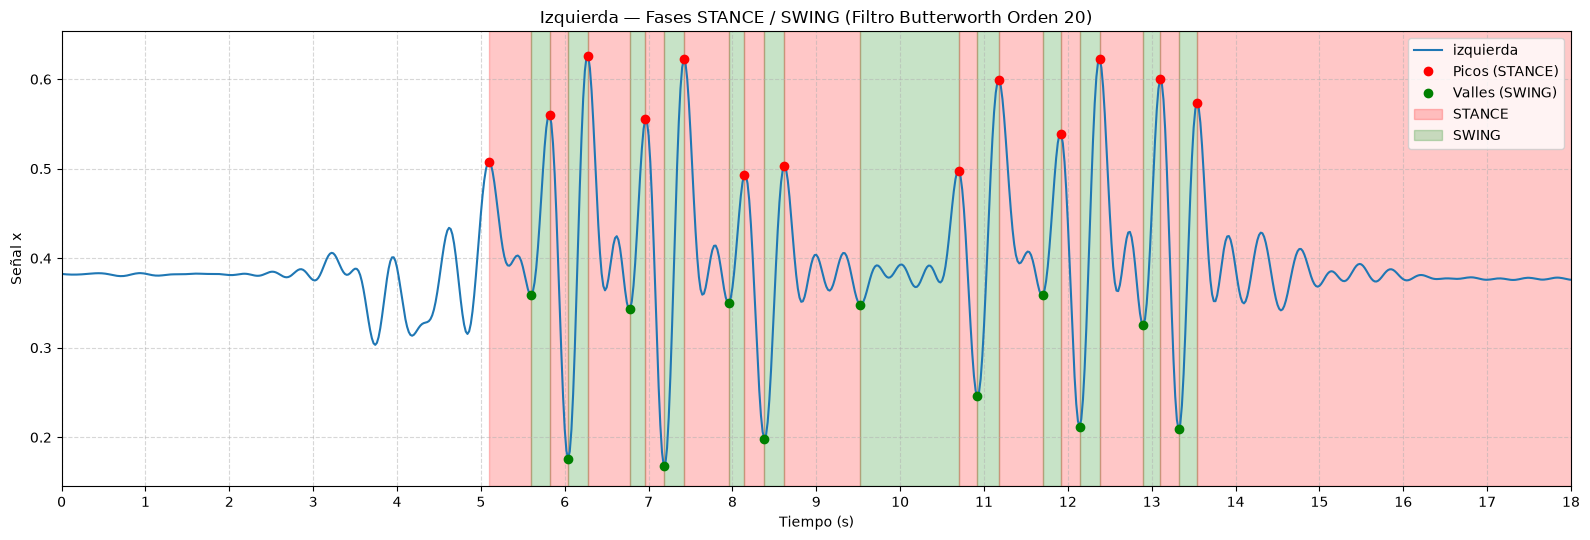

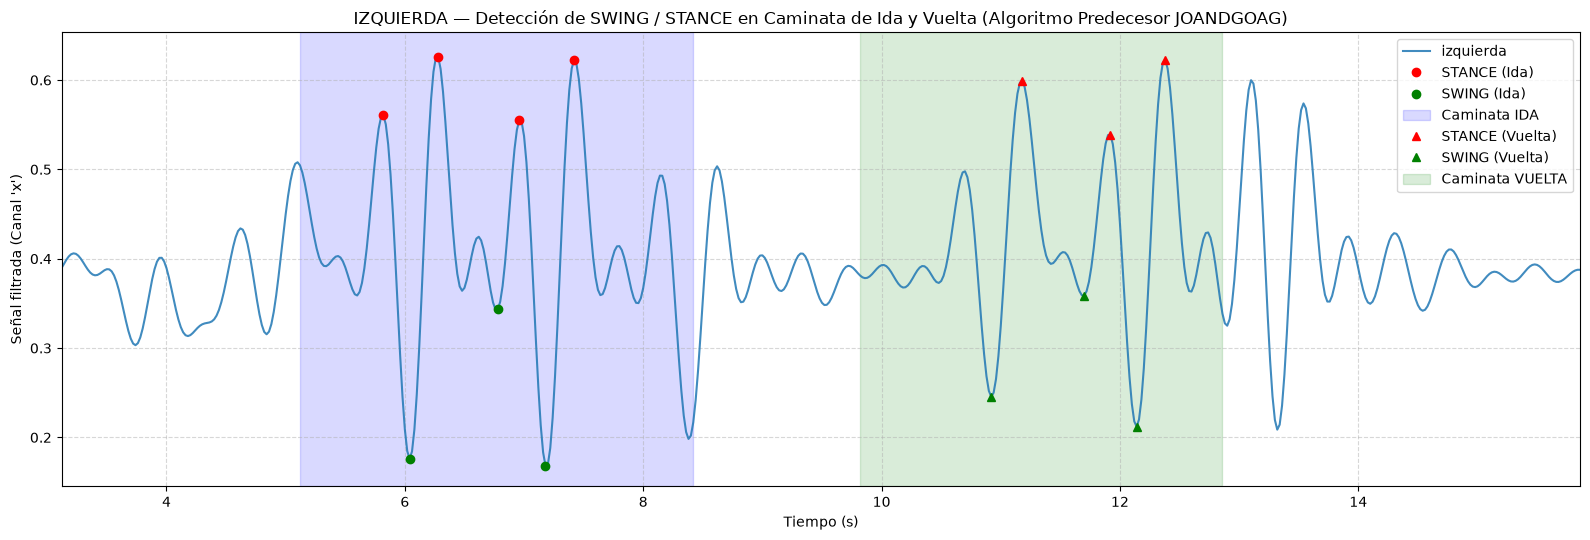

DETECCIÓN DE EVENTOS SWING / STANCE Y CLASIFICACIÓN POR FASE TUG — TOBILLO DERECHA


,paso_idx,fase_paso,inicio_s,fin_s,duracion_s,fase_tug
0,1,STANCE,4.66,4.86,0.20,Fase 1: Levantamiento
1,2,SWING,4.86,5.08,0.22,Fase 1: Levantamiento
2,3,STANCE,5.08,5.60,0.52,Fase 2: Caminata de Ida
3,4,SWING,5.60,5.82,0.22,Fase 2: Caminata de Ida
4,5,STANCE,5.82,6.02,0.20,Fase 2: Caminata de Ida
5,6,SWING,6.02,6.26,0.24,Fase 2: Caminata de Ida
6,7,STANCE,6.26,6.76,0.50,Fase 2: Caminata de Ida
7,8,SWING,6.76,6.96,0.20,Fase 2: Caminata de Ida
8,9,STANCE,6.96,7.18,0.22,Fase 2: Caminata de Ida
9,10,SWING,7.18,7.42,0.24,Fase 2: Caminata de Ida



Resumen de eventos STANCE y SWING por fase TUG (DERECHA):


,fase_tug,fase_paso,Num_Subfases,Duracion_Media_s,Duracion_Total_s
0,Fase 1: Levantamiento,STANCE,1,0.20,0.20
1,Fase 1: Levantamiento,SWING,1,0.22,0.22
2,Fase 2: Caminata de Ida,STANCE,5,0.50,2.50
3,Fase 2: Caminata de Ida,SWING,4,0.22,0.90
4,Fase 3: Giro 1 (Cono 180°),STANCE,1,0.84,0.84
5,Fase 3: Giro 1 (Cono 180°),SWING,1,0.22,0.22
6,Fase 4: Caminata de Vuelta,STANCE,3,0.33,0.98
7,Fase 4: Caminata de Vuelta,SWING,4,0.45,1.80


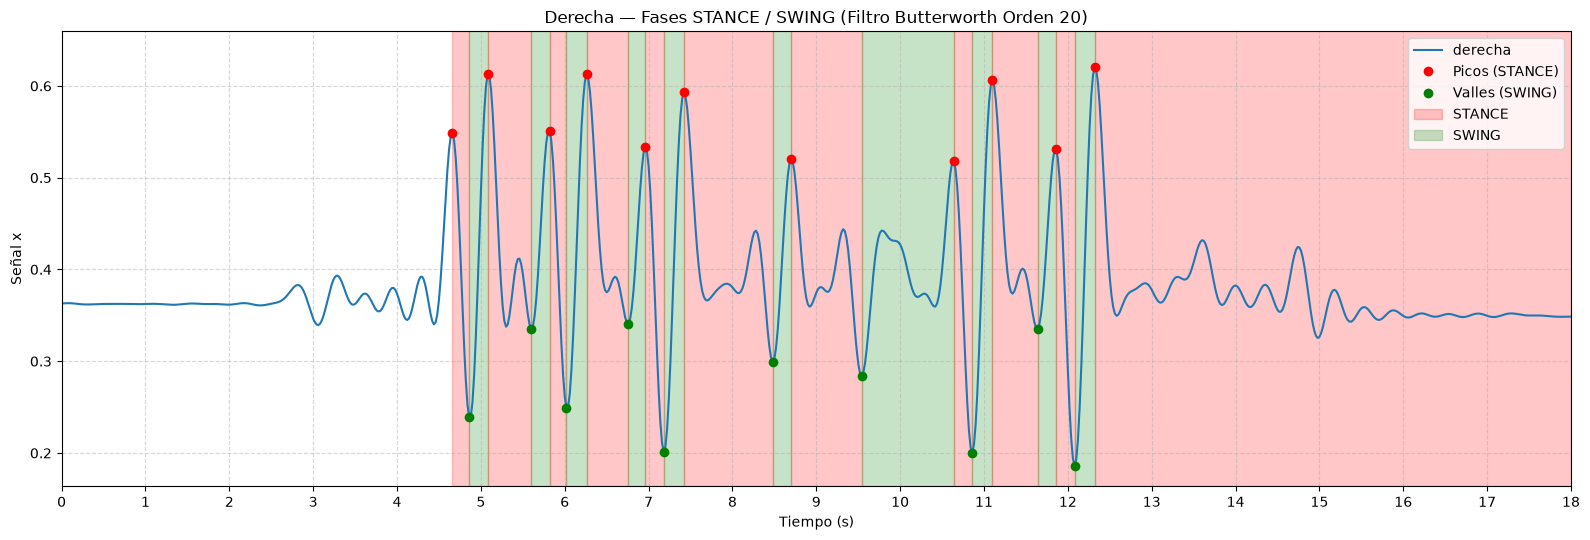

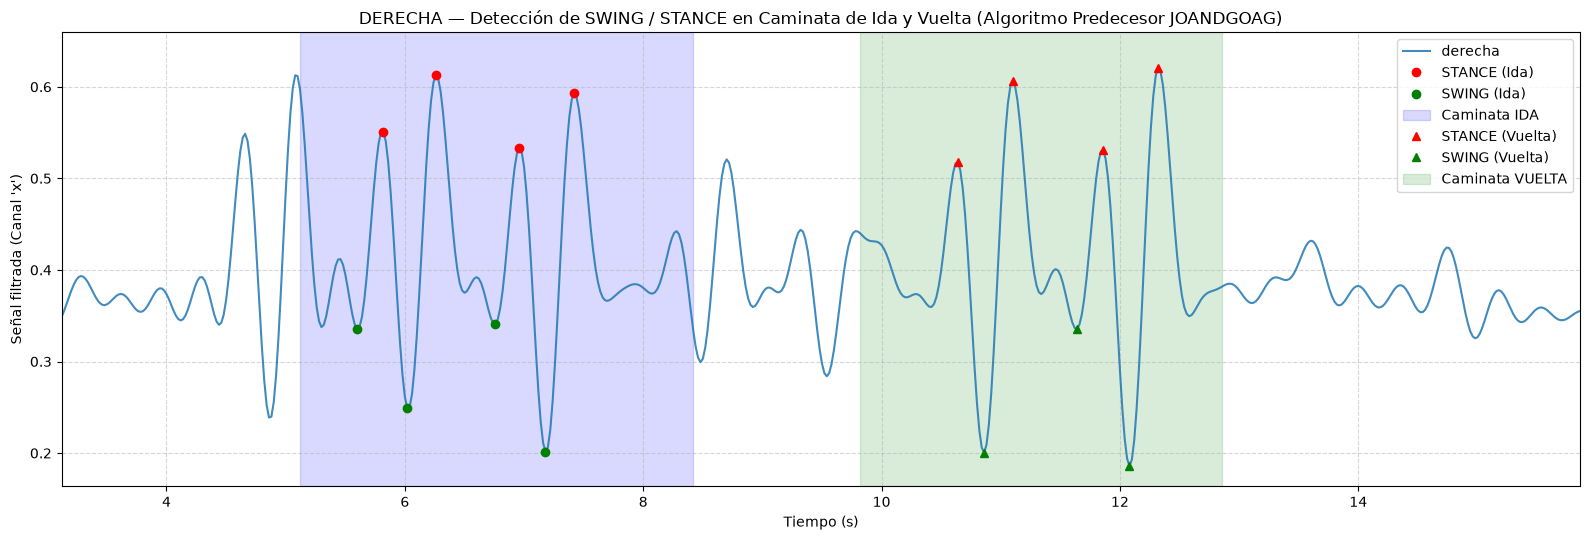

In [17]:
def detectar_pasos_registro_completo(time, asignal_filtered, fs=50.0, min_stride_s=0.4, factor_prominencia=0.20, fases_5=None):
    distance = int(min_stride_s * fs)
    prominence = factor_prominencia * np.max(np.abs(asignal_filtered))

    peaks, _ = find_peaks(asignal_filtered, prominence=prominence, distance=distance)
    valleys, _ = find_peaks(-asignal_filtered, prominence=prominence, distance=distance)

    if len(peaks) == 0 and len(valleys) == 0:
        return [], peaks, valleys

    events = np.concatenate([
        np.stack([time[peaks], np.repeat("STANCE_START", len(peaks))], axis=1),
        np.stack([time[valleys], np.repeat("SWING_START", len(valleys))], axis=1)
    ])
    events = events[np.argsort(events[:, 0].astype(float))]

    def _asignar_fase_tug(t_ini, t_fin):
        if not fases_5:
            return "Sin segmentar"
        t_medio = 0.5 * (t_ini + t_fin)
        for f in fases_5:
            if f["inicio"] <= t_medio <= f["fin"]:
                return f["nombre"]
        if t_medio < fases_5[0]["inicio"]:
            return "Pre-Levantamiento"
        if t_medio > fases_5[-1]["fin"]:
            return "Repetición subsecuente / Post-Sentado"
        return "Transición"

    fases_paso = []
    for i in range(len(events) - 1):
        fase_actual = events[i][1]
        t_inicio = float(events[i][0])
        t_fin = float(events[i + 1][0])
        dur = t_fin - t_inicio
        tipo_paso = "STANCE" if fase_actual == "STANCE_START" else "SWING"
        fases_paso.append({
            "paso_idx": i + 1,
            "fase_paso": tipo_paso,
            "inicio_s": round(t_inicio, 2),
            "fin_s": round(t_fin, 2),
            "duracion_s": round(dur, 2),
            "fase_tug": _asignar_fase_tug(t_inicio, t_fin)
        })

    return fases_paso, peaks, valleys

def detectar_pasos_intervalo(time, asignal_filtered, fs, t_inicio, t_fin):
    mask = (time >= t_inicio) & (time <= t_fin)
    t_seg = time[mask]
    sig_seg = asignal_filtered[mask]

    if len(sig_seg) < 10:
        return [], t_seg, sig_seg, np.array([], dtype=int), np.array([], dtype=int)

    min_stride_s = 0.4
    distance = int(min_stride_s * fs)
    prominence = 0.25 * np.max(np.abs(sig_seg))

    peaks, _ = find_peaks(sig_seg, prominence=prominence, distance=distance)
    valleys, _ = find_peaks(-sig_seg, prominence=prominence, distance=distance)

    if len(peaks) == 0 and len(valleys) == 0:
        return [], t_seg, sig_seg, peaks, valleys

    eventos = np.concatenate([
        np.stack([t_seg[peaks], np.repeat("STANCE_START", len(peaks))], axis=1),
        np.stack([t_seg[valleys], np.repeat("SWING_START", len(valleys))], axis=1)
    ])
    eventos = eventos[np.argsort(eventos[:, 0].astype(float))]

    fases_det = []
    for i in range(len(eventos) - 1):
        fase = eventos[i][1]
        t_i = float(eventos[i][0])
        t_f = float(eventos[i + 1][0])
        dur = t_f - t_i
        if fase == "STANCE_START":
            fases_det.append({"fase": "STANCE", "inicio": t_i, "fin": t_f, "duracion": dur})
        else:
            fases_det.append({"fase": "SWING", "inicio": t_i, "fin": t_f, "duracion": dur})

    return fases_det, t_seg, sig_seg, peaks, valleys

def graficar_swing_stance_predecesor(time, asignal_filtered, peaks, valleys, fases_paso, lateral, signal="x", t_max_vista=None):
    plt.figure(figsize=(16, 5.5))
    plt.plot(time, asignal_filtered, label=f"{lateral}")
    if len(peaks) > 0:
        plt.plot(time[peaks], asignal_filtered[peaks], "ro", label="Picos (STANCE)")
    if len(valleys) > 0:
        plt.plot(time[valleys], asignal_filtered[valleys], "go", label="Valles (SWING)")

    stance_labeled = False
    swing_labeled = False
    for f in fases_paso:
        es_stance = f["fase_paso"] == "STANCE"
        color = "red" if es_stance else "green"
        etiqueta = ""
        if es_stance and not stance_labeled:
            etiqueta = "STANCE"
            stance_labeled = True
        elif not es_stance and not swing_labeled:
            etiqueta = "SWING"
            swing_labeled = True
        plt.axvspan(f["inicio_s"], f["fin_s"], color=color, alpha=0.22, label=etiqueta)

    limite_sup = t_max_vista if t_max_vista is not None else time[-1]
    plt.xlim(time[0], limite_sup)
    paso_x = 1.0 if limite_sup <= 30 else 2.0
    plt.xticks(np.arange(0, int(np.ceil(limite_sup)) + 1, paso_x))
    plt.xlabel("Tiempo (s)")
    plt.ylabel(f"Señal {signal}")
    plt.title(f"{lateral.capitalize()} — Fases STANCE / SWING (Filtro Butterworth Orden 20)")
    plt.grid(True, which="both", axis="both", linestyle="--", alpha=0.5)
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

def graficar_pasos_caminatas_joandgoag(time, asignal_filtered, lateral, seg_ida, seg_vuelta, t_inicio_ida, t_fin_ida, t_inicio_vuelta, t_fin_vuelta):
    _, t_seg_ida, sig_seg_ida, peaks_ida, valleys_ida = seg_ida
    _, t_seg_vuelta, sig_seg_vuelta, peaks_vuelta, valleys_vuelta = seg_vuelta

    plt.figure(figsize=(16, 5.5))
    plt.plot(time, asignal_filtered, label=f"{lateral}", alpha=0.85)

    if len(peaks_ida) > 0:
        plt.plot(t_seg_ida[peaks_ida], sig_seg_ida[peaks_ida], "ro", label="STANCE (Ida)")
    if len(valleys_ida) > 0:
        plt.plot(t_seg_ida[valleys_ida], sig_seg_ida[valleys_ida], "go", label="SWING (Ida)")
    plt.axvspan(t_inicio_ida, t_fin_ida, color="blue", alpha=0.15, label="Caminata IDA")

    if len(peaks_vuelta) > 0:
        plt.plot(t_seg_vuelta[peaks_vuelta], sig_seg_vuelta[peaks_vuelta], "r^", label="STANCE (Vuelta)")
    if len(valleys_vuelta) > 0:
        plt.plot(t_seg_vuelta[valleys_vuelta], sig_seg_vuelta[valleys_vuelta], "g^", label="SWING (Vuelta)")
    plt.axvspan(t_inicio_vuelta, t_fin_vuelta, color="green", alpha=0.15, label="Caminata VUELTA")

    plt.xlim(max(0.0, t_inicio_ida - 2.0), min(time[-1], t_fin_vuelta + 3.0))
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Señal filtrada (Canal 'x')")
    plt.title(f"{lateral.upper()} — Detección de SWING / STANCE en Caminata de Ida y Vuelta (Algoritmo Predecesor JOANDGOAG)")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

pruebas_pasos = cargar_prueba_adaptada(muestra_giro, carpeta_base=CARPETA_DATOS, fs_destino=50.0)
seg_pasos_tug = segmentar_cinco_fases_tug(pruebas_pasos, indice_muestra=0, fs=50.0)
fases_5_actual = seg_pasos_tug["fases_5"]

clave_c, time_c, sig_c_g = extraer_senal(pruebas_pasos, 0, "izquierda", "g", normalizar=True)
sig_c_g_filt = filter_signal(sig_c_g, cutoff_hz=3, fs=50.0, order=20)
t_ec, energies_c = energy_spectrum(sig_c_g_filt, fs=50.0, window_size_samples=50, step_size_samples=1, apply_window=True)
t_mc, pmovil_c = promediomovil(energies_c, ventana=50, fs=50.0)
bin_c = binary_threshold(pmovil_c, threshold=0.2)
graficar_descomposicion_energia_predecesor(
    time_c, sig_c_g_filt, t_ec, energies_c, t_mc, pmovil_c, bin_c,
    signal="g (Tobillo Izquierdo)", clave_muestra=clave_c, indice_muestra=0
)

f_ida = next((f for f in fases_5_actual if f["codigo"] == "caminata_ida"), None)
f_vuelta = next((f for f in fases_5_actual if f["codigo"] == "caminata_vuelta"), None)
t_fin_ciclo1 = fases_5_actual[-1]["fin"] + 2.0 if fases_5_actual else None

for lat in ["izquierda", "derecha"]:
    _, time_lat, sig_lat_x = extraer_senal(pruebas_pasos, 0, lat, "x", normalizar=True)
    sig_lat_filt = filter_signal(sig_lat_x, cutoff_hz=3, fs=50.0, order=20)

    fases_paso_lat, peaks_lat, valleys_lat = detectar_pasos_registro_completo(
        time_lat, sig_lat_filt, fs=50.0, min_stride_s=0.4, factor_prominencia=0.20, fases_5=fases_5_actual
    )
    df_pasos_lat = pd.DataFrame(fases_paso_lat)
    df_pasos_ciclo1 = df_pasos_lat[df_pasos_lat["fase_tug"].str.startswith("Fase")].copy()

    print("=" * 80)
    print(f"DETECCIÓN DE EVENTOS SWING / STANCE Y CLASIFICACIÓN POR FASE TUG — TOBILLO {lat.upper()}")
    print("=" * 80)
    display(df_pasos_ciclo1.head(20))

    resumen_por_fase = df_pasos_ciclo1.groupby(["fase_tug", "fase_paso"]).agg(
        Num_Subfases=("duracion_s", "count"),
        Duracion_Media_s=("duracion_s", "mean"),
        Duracion_Total_s=("duracion_s", "sum")
    ).round(2).reset_index()
    print(f"\nResumen de eventos STANCE y SWING por fase TUG ({lat.upper()}):")
    display(resumen_por_fase)

    graficar_swing_stance_predecesor(
        time_lat, sig_lat_filt, peaks_lat, valleys_lat, fases_paso_lat,
        lateral=lat, signal="x", t_max_vista=t_fin_ciclo1
    )

    if f_ida and f_vuelta:
        seg_ida = detectar_pasos_intervalo(time_lat, sig_lat_filt, 50.0, f_ida["inicio"], f_ida["fin"])
        seg_vuelta = detectar_pasos_intervalo(time_lat, sig_lat_filt, 50.0, f_vuelta["inicio"], f_vuelta["fin"])
        graficar_pasos_caminatas_joandgoag(
            time_lat, sig_lat_filt, lat, seg_ida, seg_vuelta,
            f_ida["inicio"], f_ida["fin"], f_vuelta["inicio"], f_vuelta["fin"]
        )

## MÓDULO 9: Procesamiento Masivo del Dataset (66 Muestras Válidas) y Contrastación Estadística

Este módulo final ejecuta de forma automatizada el pipeline completo de segmentación de cinco fases, cuantificación de giros y detección de eventos de paso sobre las **66 grabaciones válidas** aprobadas en el Módulo 3 (58 grabaciones de pacientes con Enfermedad de Parkinson y 8 grabaciones de sujetos control), consolidando la matriz de biomarcadores cinemáticos en el archivo `df_variables_tug.csv`.

| Variable Extraída | Unidad | Definición Biomecánica y Fuente de Señal |
| :--- | :---: | :--- |
| `duracion_efectiva_tug_s` | s | Tiempo neto de ejecución del ciclo TUG desde el inicio del levantamiento hasta el fin del sentado. |
| `duracion_levantamiento_s` | s | Duración de la Fase 1 (*Sit-to-Stand*) medida en el canal `b` de `espina_base`. |
| `duracion_caminata_ida_s` | s | Duración de la Fase 2 (*Forward Gait*) entre el fin del levantamiento y el inicio del primer giro. |
| `duracion_giro_180_s` | s | Duración de la Fase 3 (*180° Turn* en el cono) medida en el canal `a` de `espina_base`. |
| `velocidad_pico_giro_deg_s` | $^\circ/\text{s}$ | Velocidad angular máxima de guiñada alcanzada durante el giro principal en el cono. |
| `duracion_caminata_vuelta_s` | s | Duración de la Fase 4 (*Return Gait*) entre el fin del primer giro y el inicio del segundo giro. |
| `duracion_sentado_s` | s | Duración del pulso de descenso postural a la silla (*Stand-to-Sit*) en el canal `b` de `espina_base`. |
| `stance_medio_s` / `swing_medio_s` | s | Duración promedio de las subfases de apoyo y balanceo en ambos tobillos (`izquierda` y `derecha`, canal `x`). |
| `eventos_paso_en_giro` | conteo | Cantidad de eventos de paso (`STANCE` + `SWING`) ejecutados dentro del intervalo del giro de 180° (Reunión 8 `[00:51:01]`). |

En cumplimiento de la directriz estadística establecida por el director del proyecto en la Reunión 8 (`[00:55:27]`–`[00:57:40]`), dado el fuerte desbalance muestral entre clases (58 pacientes frente a 8 controles), cada biomarcador es evaluado mediante la prueba de normalidad de Shapiro-Wilk (`scipy.stats.shapiro`) por grupo clínico, la prueba paramétrica $t$ de Welch para muestras independientes con varianzas y tamaños desiguales (`scipy.stats.ttest_ind(..., equal_var=False)`), y la prueba no paramétrica $U$ de Mann-Whitney (`scipy.stats.mannwhitneyu`), reportando tanto la media y desviación estándar como la mediana y el rango intercuartílico. Asimismo, dado que existen 6 participantes con múltiples grabaciones válidas, toda partición de entrenamiento y evaluación de clasificadores supervisados en la siguiente etapa deberá emplear validación cruzada agrupada por sujeto (`GroupKFold` sobre `persona_id`).

INICIANDO EXTRACCIÓN MASIVA DE BIOMARCADORES SOBRE 66 GRABACIONES VÁLIDAS
[01/66] CST_IDI10_BI.json            | TUG: 19.24s | Lev: 2.38s | Giro1: 2.26s | Sent: 2.62s
[02/66] CST_IDI11_Z.json             | TUG: 20.92s | Lev: 2.74s | Giro1: 2.98s | Sent: 1.44s
[03/66] CST_IDI13_T.json             | TUG: 16.90s | Lev: 2.00s | Giro1: 1.80s | Sent: 2.42s
[04/66] CST_IDI14_AN.json            | TUG: 12.86s | Lev: 1.78s | Giro1: 1.82s | Sent: 1.92s
[05/66] CST_IDI1_AF.json             | TUG: 14.46s | Lev: 1.92s | Giro1: 1.80s | Sent: 2.54s
[06/66] CST_IDI2_BE.json             | TUG: 25.40s | Lev: 1.12s | Giro1: 1.82s | Sent: 1.02s
[07/66] CST_IDI3_E.json              | TUG: 11.42s | Lev: 1.96s | Giro1: 1.78s | Sent: 2.86s
[08/66] CST_IDI4_Y.json              | TUG: 15.22s | Lev: 2.12s | Giro1: 1.66s | Sent: 2.68s
[09/66] CST_IDI5_AY.json             | TUG: 16.74s | Lev: 2.08s | Giro1: 1.60s | Sent: 1.96s
[10/66] CST_IDI6_BG.json             | TUG: 14.44s | Lev: 2.14s | Giro1: 1.86s | Sent: 2.

,Biomarcador,N_Pacientes,Pacientes_Media_DE,Pacientes_Mediana_RIC,N_Controles,Controles_Media_DE,Controles_Mediana_RIC,p_Shapiro_Pac,p_Shapiro_Ctrl,t_Welch,p_Welch,U_MannWhitney,p_MannWhitney
0,duracion_efectiva_tug_s,58,18.20 ± 11.27,14.45 (5.91),8,11.87 ± 5.13,12.42 (6.22),0.0000,0.1878,2.706,0.0143,324.0,0.0722
1,duracion_levantamiento_s,58,1.92 ± 0.68,1.86 (0.47),8,2.00 ± 0.97,1.75 (0.52),0.0000,0.0028,-0.240,0.8161,252.5,0.6942
2,duracion_giro_180_s,58,1.88 ± 0.45,1.76 (0.60),8,1.63 ± 0.28,1.55 (0.36),0.0006,0.4783,2.214,0.0454,320.5,0.0837
3,velocidad_pico_giro_deg_s,58,135.29 ± 33.64,133.40 (45.57),8,166.34 ± 92.69,171.32 (89.05),0.9609,0.9389,-0.939,0.3779,165.0,0.1953
4,duracion_sentado_s,58,2.02 ± 0.94,2.06 (1.24),7,2.15 ± 0.23,2.14 (0.40),0.0001,0.2755,-0.836,0.4083,189.0,0.7750
5,duracion_marcha_s,58,10.44 ± 8.82,7.75 (4.56),8,6.21 ± 4.71,6.43 (5.08),0.0000,0.7889,2.083,0.0548,292.5,0.2384
6,stance_medio_s,58,0.53 ± 0.41,0.45 (0.18),8,0.44 ± 0.25,0.35 (0.11),0.0000,0.0061,0.926,0.3711,311.0,0.1227
7,swing_medio_s,58,0.50 ± 0.58,0.35 (0.14),8,0.34 ± 0.18,0.30 (0.09),0.0000,0.0062,1.607,0.1174,312.5,0.1157
8,eventos_paso_en_giro,58,5.64 ± 2.59,5.00 (3.00),8,4.38 ± 3.11,5.00 (2.50),0.1705,0.3161,1.096,0.3035,279.0,0.3567


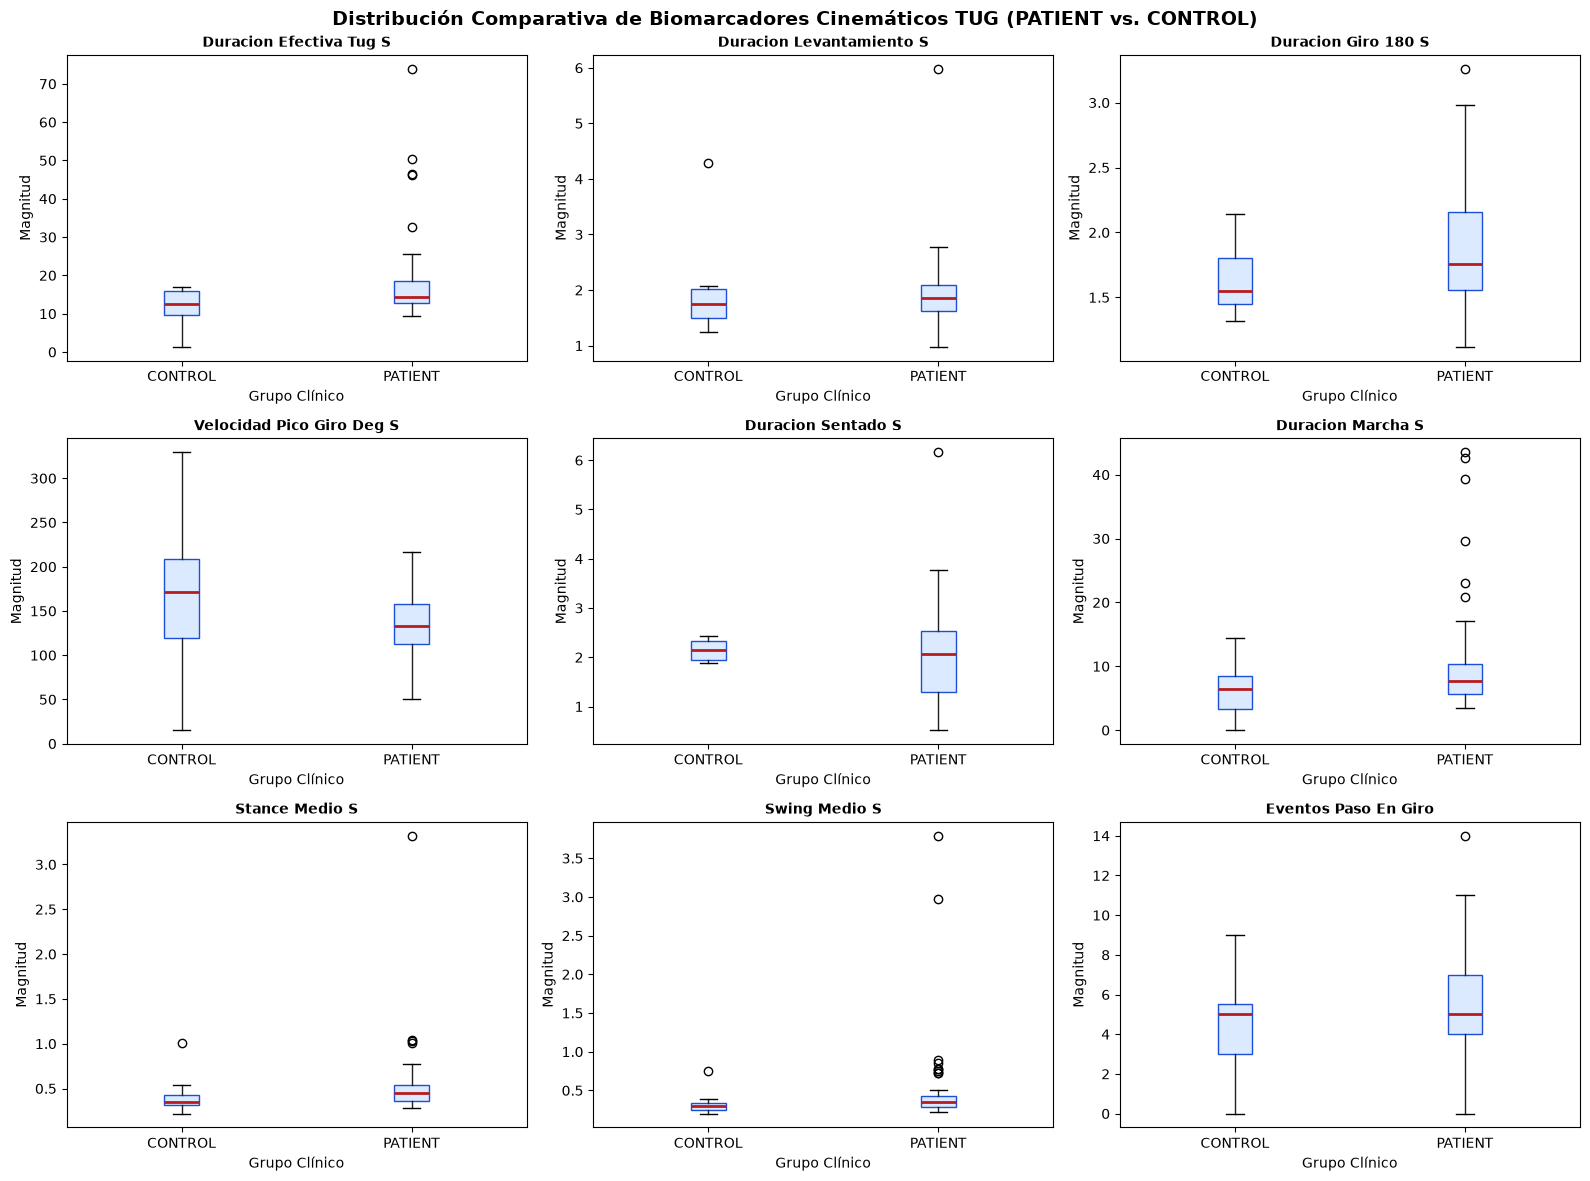

In [18]:
def procesar_pipeline_masivo_tug(df_evaluacion, carpeta_datos, fs=50.0):
    df_validos = df_evaluacion[df_evaluacion["estado"] == "ACEPTADO"].copy()
    registros_metricas = []

    print("=" * 85)
    print(f"INICIANDO EXTRACCIÓN MASIVA DE BIOMARCADORES SOBRE {len(df_validos)} GRABACIONES VÁLIDAS")
    print("=" * 85)

    for idx, (_, row) in enumerate(df_validos.iterrows(), 1):
        archivo = row["archivo"]
        codigo = row["codigo"]
        persona_id = row["persona_id"]
        tipo = row["tipo"]
        duracion_bruta = row["duracion_s"]
        kit = row["kit"]

        try:
            pruebas = cargar_prueba_adaptada(archivo, carpeta_base=carpeta_datos, fs_destino=fs)
            seg = segmentar_cinco_fases_tug(pruebas, indice_muestra=0, fs=fs)

            lev = seg["lev"]
            sent = seg["sent"]
            giros = seg["res_giros"]["intervalos"]
            fases_5 = seg["fases_5"]

            dur_levantamiento = lev["duracion"] if lev else np.nan
            dur_sentado = sent["duracion"] if sent else np.nan

            f_ida = next((f for f in fases_5 if f["codigo"] == "caminata_ida"), None)
            f_giro1 = next((f for f in fases_5 if f["codigo"] == "giro_1"), None)
            f_vuelta = next((f for f in fases_5 if f["codigo"] == "caminata_vuelta"), None)

            dur_caminata_ida = f_ida["duracion"] if f_ida else np.nan
            dur_caminata_vuelta = f_vuelta["duracion"] if f_vuelta else np.nan

            if giros:
                giro_principal = seg["giro1"] if seg["giro1"] else max(giros, key=lambda x: x["duracion"])
                dur_giro_180 = giro_principal["duracion"]
                pico_vel_giro = giro_principal["velocidad_pico"]
                pico_vel_deg_s = giro_principal.get("velocidad_pico_deg_s", np.nan)
            else:
                dur_giro_180 = np.nan
                pico_vel_giro = np.nan
                pico_vel_deg_s = np.nan

            if fases_5:
                t_inicio_ciclo = fases_5[0]["inicio"]
                t_fin_ciclo = fases_5[-1]["fin"]
                dur_tug_efectivo = max(0.0, t_fin_ciclo - t_inicio_ciclo)
            else:
                t_inicio_mov = lev["inicio_tiempo"] if lev else 0.0
                t_fin_mov = sent["fin_tiempo"] if sent else duracion_bruta
                dur_tug_efectivo = max(0.0, t_fin_mov - t_inicio_mov)

            dur_marcha_total = (
                (dur_caminata_ida if not np.isnan(dur_caminata_ida) else 0.0) +
                (dur_caminata_vuelta if not np.isnan(dur_caminata_vuelta) else 0.0)
            )
            if dur_marcha_total == 0.0 and not np.isnan(dur_tug_efectivo):
                descuentos = (
                    (dur_levantamiento if not np.isnan(dur_levantamiento) else 0.0) +
                    (dur_sentado if not np.isnan(dur_sentado) else 0.0) +
                    (dur_giro_180 if not np.isnan(dur_giro_180) else 0.0)
                )
                dur_marcha_total = max(0.0, dur_tug_efectivo - descuentos)

            stance_durs = []
            swing_durs = []
            eventos_giro = 0
            for lat in ["izquierda", "derecha"]:
                _, t_lat, s_lat = extraer_senal(pruebas, 0, lat, "x", normalizar=True)
                s_lat_filt = filter_signal(s_lat, cutoff_hz=3, fs=fs, order=20)
                pasos_lat, _, _ = detectar_pasos_registro_completo(
                    t_lat, s_lat_filt, fs=fs, min_stride_s=0.4, factor_prominencia=0.20, fases_5=fases_5
                )
                for p in pasos_lat:
                    if str(p["fase_tug"]).startswith("Fase"):
                        if p["fase_paso"] == "STANCE":
                            stance_durs.append(p["duracion_s"])
                        else:
                            swing_durs.append(p["duracion_s"])
                    if "Giro 1" in str(p["fase_tug"]):
                        eventos_giro += 1

            stance_medio = float(np.mean(stance_durs)) if stance_durs else np.nan
            swing_medio = float(np.mean(swing_durs)) if swing_durs else np.nan
            segmentacion_completa = bool(not np.isnan(dur_levantamiento) and not np.isnan(dur_sentado) and not np.isnan(dur_giro_180))

            registros_metricas.append({
                "archivo": archivo,
                "codigo": codigo,
                "persona_id": persona_id,
                "tipo": tipo,
                "kit": kit,
                "duracion_total_s": duracion_bruta,
                "duracion_efectiva_tug_s": round(dur_tug_efectivo, 2),
                "duracion_levantamiento_s": round(dur_levantamiento, 2) if not np.isnan(dur_levantamiento) else np.nan,
                "duracion_caminata_ida_s": round(dur_caminata_ida, 2) if not np.isnan(dur_caminata_ida) else np.nan,
                "duracion_giro_180_s": round(dur_giro_180, 2) if not np.isnan(dur_giro_180) else np.nan,
                "velocidad_pico_giro": round(pico_vel_giro, 3) if not np.isnan(pico_vel_giro) else np.nan,
                "velocidad_pico_giro_deg_s": round(pico_vel_deg_s, 2) if not np.isnan(pico_vel_deg_s) else np.nan,
                "duracion_caminata_vuelta_s": round(dur_caminata_vuelta, 2) if not np.isnan(dur_caminata_vuelta) else np.nan,
                "duracion_sentado_s": round(dur_sentado, 2) if not np.isnan(dur_sentado) else np.nan,
                "duracion_marcha_s": round(dur_marcha_total, 2),
                "stance_medio_s": round(stance_medio, 2) if not np.isnan(stance_medio) else np.nan,
                "swing_medio_s": round(swing_medio, 2) if not np.isnan(swing_medio) else np.nan,
                "eventos_paso_en_giro": int(eventos_giro),
                "num_giros_detectados": len(giros),
                "segmentacion_completa": segmentacion_completa,
                "estado_procesamiento": "EXITOSO"
            })
            print(f"[{idx:02d}/{len(df_validos)}] {archivo[:28]:28s} | TUG: {dur_tug_efectivo:5.2f}s | Lev: {dur_levantamiento if not np.isnan(dur_levantamiento) else -1:4.2f}s | Giro1: {dur_giro_180 if not np.isnan(dur_giro_180) else -1:4.2f}s | Sent: {dur_sentado if not np.isnan(dur_sentado) else -1:4.2f}s")

        except Exception as e:
            registros_metricas.append({
                "archivo": archivo,
                "codigo": codigo,
                "persona_id": persona_id,
                "tipo": tipo,
                "kit": kit,
                "duracion_total_s": duracion_bruta,
                "duracion_efectiva_tug_s": np.nan,
                "duracion_levantamiento_s": np.nan,
                "duracion_caminata_ida_s": np.nan,
                "duracion_giro_180_s": np.nan,
                "velocidad_pico_giro": np.nan,
                "velocidad_pico_giro_deg_s": np.nan,
                "duracion_caminata_vuelta_s": np.nan,
                "duracion_sentado_s": np.nan,
                "duracion_marcha_s": np.nan,
                "stance_medio_s": np.nan,
                "swing_medio_s": np.nan,
                "eventos_paso_en_giro": 0,
                "num_giros_detectados": 0,
                "segmentacion_completa": False,
                "estado_procesamiento": f"ERROR: {str(e)}"
            })
            print(f"[{idx:02d}/{len(df_validos)}] Error procesando {archivo}: {e}")

    return pd.DataFrame(registros_metricas)

def ejecutar_contraste_estadistico_tug(df_vars, columnas_evaluar):
    filas_estadisticas = []
    for col in columnas_evaluar:
        datos_pat = df_vars[df_vars["tipo"] == "PATIENT"][col].dropna().values
        datos_con = df_vars[df_vars["tipo"] == "CONTROL"][col].dropna().values

        if len(datos_pat) < 3 or len(datos_con) < 3:
            continue

        _, p_shapiro_pat = shapiro(datos_pat)
        _, p_shapiro_con = shapiro(datos_con)
        t_welch, p_welch = ttest_ind(datos_pat, datos_con, equal_var=False)
        u_stat, p_mwu = mannwhitneyu(datos_pat, datos_con, alternative="two-sided")

        iqr_pat = np.percentile(datos_pat, 75) - np.percentile(datos_pat, 25)
        iqr_con = np.percentile(datos_con, 75) - np.percentile(datos_con, 25)

        filas_estadisticas.append({
            "Biomarcador": col,
            "N_Pacientes": len(datos_pat),
            "Pacientes_Media_DE": f"{np.mean(datos_pat):.2f} ± {np.std(datos_pat, ddof=1):.2f}",
            "Pacientes_Mediana_RIC": f"{np.median(datos_pat):.2f} ({iqr_pat:.2f})",
            "N_Controles": len(datos_con),
            "Controles_Media_DE": f"{np.mean(datos_con):.2f} ± {np.std(datos_con, ddof=1):.2f}",
            "Controles_Mediana_RIC": f"{np.median(datos_con):.2f} ({iqr_con:.2f})",
            "p_Shapiro_Pac": round(float(p_shapiro_pat), 4),
            "p_Shapiro_Ctrl": round(float(p_shapiro_con), 4),
            "t_Welch": round(float(t_welch), 3),
            "p_Welch": round(float(p_welch), 4),
            "U_MannWhitney": round(float(u_stat), 1),
            "p_MannWhitney": round(float(p_mwu), 4)
        })
    return pd.DataFrame(filas_estadisticas)

df_variables_tug = procesar_pipeline_masivo_tug(df_evaluacion, CARPETA_DATOS, fs=50.0)

posibles_vars = [os.path.join("Datos IMUs", "df_variables_IMUs.csv"), os.path.join("..", "Datos IMUs", "df_variables_IMUs.csv"), "df_variables_IMUs.csv", os.path.join("Analisis de Datos", "df_variables_tug.csv"), "df_variables_tug.csv"]
ruta_csv_vars = next((r for r in posibles_vars if os.path.exists(os.path.dirname(r)) or os.path.dirname(r) == ""), "df_variables_IMUs.csv")
cols_extra_tecnicas = [c for c in ["criterio_calidad", "motivo_descarte", "detalle_motivos", "duracion_s", "pausa_ms", "inicio_ms", "fin_ms", "md5"] if c in df_evaluacion.columns and c not in df_variables_tug.columns]
if cols_extra_tecnicas:
    df_variables_tug = pd.merge(df_variables_tug, df_evaluacion[["archivo"] + cols_extra_tecnicas], on="archivo", how="left")
df_variables_tug.to_csv(ruta_csv_vars, index=False)
print(f"\nMatriz consolidada de biomarcadores exportada en: {ruta_csv_vars}")
print(f"Muestras con segmentación completa de todas las fases: {df_variables_tug['segmentacion_completa'].sum()} / {len(df_variables_tug)}")

cols_metricas = [
    "duracion_efectiva_tug_s",
    "duracion_levantamiento_s",
    "duracion_giro_180_s",
    "velocidad_pico_giro_deg_s",
    "duracion_sentado_s",
    "duracion_marcha_s",
    "stance_medio_s",
    "swing_medio_s",
    "eventos_paso_en_giro"
]

df_contraste = ejecutar_contraste_estadistico_tug(df_variables_tug, cols_metricas)
print("\n" + "=" * 85)
print("CONTRASTACIÓN ESTADÍSTICA DE BIOMARCADORES TUG (SHAPIRO-WILK, WELCH Y MANN-WHITNEY U)")
print("=" * 85)
display(df_contraste)

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()
for i, col in enumerate(cols_metricas):
    ax = axes[i]
    df_variables_tug.boxplot(
        column=col, by="tipo", ax=ax, grid=False, patch_artist=True,
        boxprops=dict(facecolor="#dbeafe", color="#1d4ed8"),
        medianprops=dict(color="#b91c1c", linewidth=2)
    )
    ax.set_title(col.replace("_", " ").title(), fontweight="bold", fontsize=10)
    ax.set_xlabel("Grupo Clínico")
    ax.set_ylabel("Magnitud")
plt.suptitle("Distribución Comparativa de Biomarcadores Cinemáticos TUG (PATIENT vs. CONTROL)", fontsize=14, fontweight="bold")
plt.tight_layout()


# PIPELINE 2: e-MOTION (RGB-D)


Esta sección implementa el flujo completo de procesamiento digital de señales, control de calidad determinístico, segmentación biomecánica adaptada y contrastación estadística para el conjunto de datos ópticos capturados con cámaras de profundidad RGB-D (**Intel RealSense D455/D455F** y **Orbbec Astra 2**) a través del sistema **e-Motion / VIMOV**.

El diseño algorítmico responde de manera integral a las directrices metodológicas y biomecánicas establecidas para el procesamiento cinemático 3D:
1. **Separación y Aprovechamiento Dual de Protocolos (`TUG` y `GAIT`):** Se procesan tanto las **130 grabaciones de protocolo TUG** (`Datos e-Motion/TUG/`) como las **95 grabaciones de marcha continua** (`Datos e-Motion/GAIT/`: 93 series esqueléticas + 2 métricas comparativas), permitiendo evaluar parámetros locomotores con y sin el efecto perturbador del giro y la silla.
2. **Armonización de Generaciones de Esquema (`v1.2.0` de 19 articulaciones vs. `v1.3.0` de 15 articulaciones):** Se estandariza el nodo anatómico universal `SpineBase` (presente en el 100% de las 267 capturas esqueléticas, equivalente a `Hip Center`) junto con `Head`, `AnkleLeft`, `AnkleRight`, `WristLeft` y `WristRight`.
3. **Control de Calidad Determinístico:** Purgadas las **44 grabaciones redundantes** (42 réplicas de re-sincronización en nube y 2 pruebas de personal interno `i2t_staff`), consolidando **223 grabaciones clínicas únicas aceptadas** (130 TUG + 93 Marcha Continua) más 2 archivos tabulares de métricas comparativas.
4. **Interpolación Monótona PCHIP a 30.0 Hz, Remoción DC, FFT y Filtrado Butterworth a 3.0 Hz:** Corrige la no-equitemporalidad del vector `Timestamp` ($\Delta t$ variable) sin introducir oscilaciones de Runge en los escalones de apoyo plantar y elimina el ruido cuántico del sensor de profundidad por encima de 3 Hz.
5. **Macro-Segmentación Adaptada de las 5 Fases TUG y Micro-Segmentación en Tobillos ("Escalerita", Wavelet CWT Ricker y Doble Apoyo):** Delimita las 5 fases del TUG en cámara (demostrando que el **96.9% captura el levantamiento** y el **100% captura el inicio o totalidad del sentado**, mientras que el **84.8% sufre oclusión articular a corta distancia en el giro de 180°**) y extrae en los corredores de marcha los eventos `SWING` / `STANCE`, el **Porcentaje de Doble Apoyo (*Double Support*)**, la **Longitud de Paso y Zancada**, la **Velocidad Lineal por Pendiente de `SpineBase`** y la **Amplitud/Asimetría de Braceo**.

## MÓDULO 10: Ingesta de Datos Ópticos e-Motion, Control de Calidad Determinístico e Interpolación PCHIP a 30.0 Hz

Este módulo localiza los subdirectorios `Datos e-Motion/TUG/` y `Datos e-Motion/GAIT/`, audita la estructura interna de los 225 archivos JSON vigentes y ejecuta tres operaciones fundamentales de preparación de datos:
1. **Control de Integridad por Firma Esquelética (`SkeletonLocation`):** Valida la tupla invariante `(num_frames, frame_0_UUID, frame_end_UUID)` para asegurar la ausencia de réplicas en disco y garantizar la inclusión de capturas válidas únicas.
2. **Auditoría de Equitemporalidad ($\Delta t$):** Cuantifica la mediana ($\Delta t = 33.0\text{ ms}$) y el *jitter* de muestreo de la cámara, aplicando una máscara de continuidad temporal ($|t_{\text{raw}} - t_{\text{unif}}| \le 0.25\text{ s}$) que neutraliza pausas operativas prolongadas (como la pausa de $81.34\text{ s}$ detectada en `SMR_ID50_eMotion_NO_GAIT.json`).
3. **Interpolación Hermítica Cúbica Monótona (PCHIP) a $30.0\text{ Hz}$:** Remuestrea las trayectorias tridimensionales $(X, Y, Z)$ de cada articulación sobre una rejilla equitemporal estricta ($\Delta t = 1/30\text{ s}$), preservando la morfología plana de los escalones de apoyo (`STANCE`) sin sobreimpulsos artificiales.


In [19]:
from scipy.interpolate import PchipInterpolator

STAFF_PATIENT_UUID = "e0cb1f8f-796e-4fb2-9ca2-62bdbf348df3"

def buscar_archivos_emotion(base_dir=None):
    posibles_bases = [
        base_dir,
        "Datos e-Motion",
        "../Datos e-Motion",
        "./Datos e-Motion",
        os.path.join(os.getcwd(), "Datos e-Motion"),
        os.path.join(os.path.dirname(os.getcwd()), "Datos e-Motion"),
        "/content/drive/MyDrive/TUG_Data/Datos e-Motion"
    ]
    for ruta in posibles_bases:
        if ruta and os.path.exists(ruta) and os.path.isdir(ruta):
            tug_dir = os.path.join(ruta, "TUG")
            gait_dir = os.path.join(ruta, "GAIT") if os.path.exists(os.path.join(ruta, "GAIT")) else os.path.join(ruta, "GAIT")
            archivos_tug = sorted(glob.glob(os.path.join(tug_dir, "*.json"))) if os.path.exists(tug_dir) else sorted(glob.glob(os.path.join(ruta, "*.json")))
            archivos_gait = sorted(glob.glob(os.path.join(gait_dir, "*.json"))) if os.path.exists(gait_dir) else []
            if archivos_tug or archivos_gait:
                return ruta, archivos_tug, archivos_gait
    return None, [], []

def auditar_inventario_emotion(archivos_tug, archivos_gait):
    registros = []
    todos = [(f, "TUG") for f in archivos_tug] + [(f, "GAIT") for f in archivos_gait]

    for ruta, subcarpeta in todos:
        fname = os.path.basename(ruta)
        with open(ruta, "r", encoding="utf-8") as fp:
            d = json.load(fp)

        am = d.get("AnonymizedMetadata", {})
        ct = d.get("CaptureTest")
        if not ct:
            registros.append({
                "archivo": fname, "ruta": ruta, "subcarpeta": subcarpeta,
                "es_metrica": True, "tiene_imu": False, "is_staff": False,
                "skel_sig": ("METRIC", fname), "num_frames": 0, "duracion_s": 0.0,
                "dt_mediana_ms": 0.0, "jitter_std_ms": 0.0, "pausa_max_ms": 0.0,
                "version_esquema": "N/A", "num_articulaciones": 0,
                "clase_clinica": "SIN_ETIQUETA", "brigada": "CST", "sensor": "Comparativa Intel vs Orbbec"
            })
            continue

        kms = ct.get("KinectMachineStatus", [])
        skel = kms[0].get("SkeletonLocation", []) if kms else []
        n_frames = len(skel)
        sig = (n_frames, skel[0].get("Id", ""), skel[-1].get("Id", "")) if n_frames > 0 else (0, "", "")

        pid = str(d.get("Patient", {}).get("Id", ""))
        vpid = str(am.get("vimov_patient_id", ""))
        is_staff = (STAFF_PATIENT_UUID in pid) or ("staff" in vpid.lower())

        ts_ms = np.array([float(fr.get("Timestamp", 0)) for fr in skel], dtype=float)
        dur_s = float((ts_ms[-1] - ts_ms[0]) / 1000.0) if n_frames > 1 else 0.0
        dt_ms = np.diff(ts_ms) if n_frames > 1 else np.array([33.3])
        dt_sin_pausa = dt_ms[dt_ms < 500.0]

        jnames = set()
        for fr in skel[:min(30, n_frames)]:
            for j in fr.get("JointLocation", []):
                jnames.add(j.get("JointType"))

        demo = am.get("demografia", {})
        tiene_imu = bool(am.get("tiene_imu", False))
        brigada = am.get("brigada") or ("SMR" if fname.startswith("SMR") else ("CST" if fname.startswith("CST") else "LAB"))
        clase = am.get("tipo_sujeto") or ("PATIENT" if demo.get("es_paciente") else ("CONTROL_LAB" if brigada == "LAB" else "SIN_ETIQUETA"))

        registros.append({
            "archivo": fname, "ruta": ruta, "subcarpeta": subcarpeta,
            "es_metrica": False, "tiene_imu": tiene_imu, "is_staff": is_staff,
            "skel_sig": sig, "num_frames": n_frames, "duracion_s": round(dur_s, 2),
            "dt_mediana_ms": round(float(np.median(dt_ms)), 1),
            "jitter_std_ms": round(float(np.std(dt_sin_pausa, ddof=1)) if len(dt_sin_pausa) > 1 else 0.0, 2),
            "pausa_max_ms": round(float(np.max(dt_ms)), 1),
            "version_esquema": d.get("version") or "1.3.0",
            "num_articulaciones": len(jnames),
            "clase_clinica": clase, "brigada": brigada,
            "sensor": d.get("Camera") or am.get("sensor", "Intel RealSense")
        })

    por_firma = defaultdict(list)
    for r in registros:
        if not r["es_metrica"]:
            por_firma[(r["subcarpeta"], r["skel_sig"])].append(r)

    for _, grupo in por_firma.items():
        grupo.sort(key=lambda x: (not x["tiene_imu"], x["archivo"]))
        canon = grupo[0]
        if canon["is_staff"]:
            canon["estado_calidad"] = "DESCARTADO_PRUEBA_STAFF"
            canon["motivo_descarte"] = "Prueba técnica interna (usuario i2t_staff)"
        else:
            canon["estado_calidad"] = "ACEPTADO"
            canon["motivo_descarte"] = "Ninguno (Muestra válida)"
        for dup in grupo[1:]:
            dup["estado_calidad"] = "DESCARTADO_DUPLICADO_API"
            dup["motivo_descarte"] = f"Réplica exacta de SkeletonLocation de {canon['archivo']}"

    for r in registros:
        if r["es_metrica"]:
            r["estado_calidad"] = "ARCHIVO_METRICAS_COMPARATIVAS"
            r["motivo_descarte"] = "Resumen tabular precalculado Intel vs Orbbec"

    return pd.DataFrame(registros)

def interpolar_esqueleto_pchip_30hz(ruta_json, fs=30.0):
    with open(ruta_json, "r", encoding="utf-8") as fp:
        d = json.load(fp)
    ct = d.get("CaptureTest", {})
    kms = ct.get("KinectMachineStatus", [])
    skel = kms[0].get("SkeletonLocation", []) if kms else []
    if not skel:
        return None

    ts_ms = np.array([float(fr.get("Timestamp", 0)) for fr in skel], dtype=float)
    t_raw = (ts_ms - ts_ms[0]) / 1000.0
    for i in range(1, len(t_raw)):
        if t_raw[i] <= t_raw[i - 1]:
            t_raw[i] = t_raw[i - 1] + 1e-4

    dt = 1.0 / fs
    n_unif = max(15, int(np.floor(t_raw[-1] * fs)))
    t_unif = np.arange(n_unif, dtype=float) * dt

    articulaciones = ["SpineBase", "Head", "AnkleLeft", "AnkleRight", "WristLeft", "WristRight", "LeftKnee", "RightKnee"]
    raw_series = {j: {"t": [], "x": [], "y": [], "z": []} for j in articulaciones}
    tracked_raw = np.zeros(len(skel), dtype=bool)
    ankles_raw = np.zeros(len(skel), dtype=bool)

    for idx, fr in enumerate(skel):
        jmap = {j.get("JointType"): j for j in fr.get("JointLocation", [])}
        sb = jmap.get("SpineBase") or jmap.get("BodyCenter")
        if sb and str(sb.get("JointTrackingState")) in ("Tracked", "2") and float(sb.get("JointPointZ", 0)) > 0.1:
            tracked_raw[idx] = True
        al, ar = jmap.get("AnkleLeft"), jmap.get("AnkleRight")
        if (al and str(al.get("JointTrackingState")) in ("Tracked", "2") and float(al.get("JointPointZ", 0)) > 0.1 and
            ar and str(ar.get("JointTrackingState")) in ("Tracked", "2") and float(ar.get("JointPointZ", 0)) > 0.1):
            ankles_raw[idx] = True

        for jt in articulaciones:
            j = jmap.get(jt) or (jmap.get("BodyCenter") if jt == "SpineBase" else None)
            if j and str(j.get("JointTrackingState")) in ("Tracked", "2"):
                pz = float(j.get("JointPointZ", 0.0))
                if pz > 0.1:
                    raw_series[jt]["t"].append(t_raw[idx])
                    raw_series[jt]["x"].append(float(j.get("JointPointX", 0.0)))
                    raw_series[jt]["y"].append(float(j.get("JointPointY", 0.0)))
                    raw_series[jt]["z"].append(pz)

    idx_nearest = np.searchsorted(t_raw, t_unif, side="left")
    idx_nearest = np.clip(idx_nearest, 0, len(t_raw) - 1)
    mask_continuidad = np.abs(t_raw[idx_nearest] - t_unif) <= 0.25
    tracked_unif = tracked_raw[idx_nearest] & mask_continuidad
    ankles_unif = ankles_raw[idx_nearest] & mask_continuidad

    interp_coords = {}
    for jt in articulaciones:
        tj = np.array(raw_series[jt]["t"], dtype=float)
        interp_coords[jt] = {}
        for eje in ("x", "y", "z"):
            vj = np.array(raw_series[jt][eje], dtype=float)
            if len(tj) >= 4:
                pchip = PchipInterpolator(tj, vj, extrapolate=False)
                vals = pchip(t_unif)
                vals[t_unif < tj[0]] = vj[0]
                vals[t_unif > tj[-1]] = vj[-1]
                vals = np.clip(vals, np.min(vj), np.max(vj))
            elif len(tj) > 0:
                vals = np.full(n_unif, vj[0], dtype=float)
            else:
                vals = np.zeros(n_unif, dtype=float)
            interp_coords[jt][eje] = vals

    n_art = len(skel[0].get("JointLocation", [])) if skel else 0
    ver_esq = d.get("CaptureTest", {}).get("Version", "1.3.0")
    dur_s = float(t_unif[-1]) if len(t_unif) > 0 else 0.0

    return {
        "archivo": os.path.basename(ruta_json),
        "fs": fs, "dt": dt,
        "n_unif": n_unif,
        "duracion_s": dur_s,
        "n_articulaciones": n_art,
        "version_esquema": ver_esq,
        "t_raw": t_raw, "dt_raw_ms": np.diff(ts_ms),
        "t_unif": t_unif,
        "tracked_unif": tracked_unif,
        "ankles_unif": ankles_unif,
        "raw_series": raw_series,
        "pchip": interp_coords
    }

RUTA_EMOTION, ARCHIVOS_EM_TUG, ARCHIVOS_EM_GAIT = buscar_archivos_emotion()
print("=" * 85)
print("AUDITORÍA INTEGRAL Y CONTROL DE CALIDAD DEL DATASET e-MOTION (MÓDULO 10)")
print("=" * 85)
if RUTA_EMOTION:
    df_auditoria_em = auditar_inventario_emotion(ARCHIVOS_EM_TUG, ARCHIVOS_EM_GAIT)
    print(f"Directorio raíz e-Motion:              {RUTA_EMOTION}")
    print(f"Archivos en TUG/:                      {len(ARCHIVOS_EM_TUG)}")
    print(f"Archivos en GAIT/:     {len(ARCHIVOS_EM_GAIT)}")
    print(f"Total archivos auditados:              {len(df_auditoria_em)}")
    print("-" * 85)
    resumen_calidad_em = df_auditoria_em.groupby(["subcarpeta", "estado_calidad", "motivo_descarte"]).size().reset_index(name="Cantidad")
    display(resumen_calidad_em)

    resumen_esquemas = df_auditoria_em[~df_auditoria_em["es_metrica"]].groupby(["subcarpeta", "version_esquema", "num_articulaciones"]).agg(
        Archivos=("archivo", "count"),
        Aceptados=("estado_calidad", lambda s: (s == "ACEPTADO").sum()),
        dt_Mediana_ms=("dt_mediana_ms", "median"),
        Jitter_Medio_ms=("jitter_std_ms", "mean"),
        Pausa_Max_ms=("pausa_max_ms", "max")
    ).reset_index()
    print("\nDistribución por generación de esquema articular (19 vs 15 nodos) y equitemporalidad:")
    display(resumen_esquemas)
else:
    print("No se encontró el directorio Datos e-Motion.")


AUDITORÍA INTEGRAL Y CONTROL DE CALIDAD DEL DATASET e-MOTION (MÓDULO 10)
Directorio raíz e-Motion:              ../Datos e-Motion
Archivos en TUG/:                      130
Archivos en GAIT/:     95
Total archivos auditados:              225
-------------------------------------------------------------------------------------


,subcarpeta,estado_calidad,motivo_descarte,Cantidad
0,GAIT,ACEPTADO,Ninguno (Muestra válida),93
1,GAIT,ARCHIVO_METRICAS_COMPARATIVAS,Resumen tabular precalculado Intel vs Orbbec,2
2,TUG,ACEPTADO,Ninguno (Muestra válida),130



Distribución por generación de esquema articular (19 vs 15 nodos) y equitemporalidad:


,subcarpeta,version_esquema,num_articulaciones,Archivos,Aceptados,dt_Mediana_ms,Jitter_Medio_ms,Pausa_Max_ms
0,GAIT,1.2.0,19,56,56,33.0,2.352679,164.0
1,GAIT,1.3.0,2,2,2,33.0,1.145000,37.0
2,GAIT,1.3.0,15,35,35,33.0,1.322571,81288.0
3,TUG,0.3.6,2,1,1,33.0,0.480000,34.0
4,TUG,0.3.6,15,16,16,33.0,1.575000,101.0
5,TUG,1.3.0,2,17,17,33.0,1.210000,39.0
6,TUG,1.3.0,15,95,95,33.0,1.104842,40.0
7,TUG,1.3.0,19,1,1,42.0,1.200000,51.0


## MÓDULO 11: Acondicionamiento Frecuencial (Remoción DC, FFT 1–2 Hz y Filtro Butterworth 3 Hz) y Macro-Segmentación Adaptada de las 5 Fases TUG

Conforme a los principios de procesamiento de señales y análisis espectral biomecánico, este módulo implementa:
1. **Remoción del Nivel DC y Validación mediante Transformada Rápida de Fourier (FFT):** Al sustraer el valor medio y la tendencia traslacional de la separación inter-tobillo $\Delta Z_{\text{tobillos}}(t)$, el espectro de potencia demuestra que la frecuencia fundamental de la locomoción humana se concentra entre **$1.0\text{ y }2.2\text{ Hz}$**, mientras que las componentes superiores a $3.0\text{ Hz}$ corresponden a ruido instrumental del sensor de profundidad.
2. **Filtro Butterworth Paso Bajas de Orden 4 a $f_c = 3.0\text{ Hz}$ (`filtfilt`):** Suaviza sin desfase temporal las coordenadas interpoladas por PCHIP.
3. **Algoritmo de Macro-Segmentación Adaptado a las 5 Fases del TUG:**
   * **Marcha 1 (Ida) y Marcha 2 (Regreso):** Delimitadas mediante el cruce de la velocidad sagital $v_{z,\text{SpineBase}}(t) = dZ/dt$ con umbral adaptativo ($v_z < -v_{\text{thr}}$ en acercamiento y $v_z > +v_{\text{thr}}$ en alejamiento), calculando la velocidad lineal de cada tramo por pendiente de regresión lineal $|\Delta Z / \Delta t|$.
   * **Fase 3 (Zona de Giro de 180°):** Acotada de manera exacta en el intervalo de inversión $[t_{\text{fin\_ida}}, t_{\text{ini\_vuelta}}]$ alrededor de $Z_{\min}$, cuantificando el porcentaje de cuadros con pérdida de rastreo (`NotTracked`).
   * **Fase 1 (`Levantamiento`) y Fase 5 (`Sentado`):** Delimitadas en la zona de la silla ($Z \ge Z_{\max} - 0.8\text{ m}$) mediante la envolvente de **energía cinética vertical** $E_y(t) = \text{MA}_{0.4\text{s}}\big(\frac{1}{2}(v_{y,\text{SpineBase}}^2 + v_{y,\text{Head}}^2)\big)$.

4. **Sección Interactiva de Selección de Archivos:** Permite ingresar directamente el nombre o identificador de cualquier archivo JSON () para visualizar de manera inmediata sus curvas (t)$, velocidades lineales, transiciones posturales en silla y espectro FFT.

In [20]:
# Parámetros de Acondicionamiento Cinemático e-Motion (MÓDULO 11)
archivo_a_leer_emotion = "SMR_IDE1_TUG_P06.json"
graficar_macro_segmentacion = True

✓ Archivo localizado en disco: ../Datos e-Motion/TUG/SMR_IDE1_TUG_P06.json
FICHA CINEMÁTICA ÓPTICA (MÓDULO 11) — SMR_IDE1_TUG_P06.json
• Protocolo Clínico:        TUG (Protocolo Estándar con Giro y Silla)
• Esquema Articular:        2 articulaciones (Versión 1.3.0)
• Duración de Captura:      21.90 s (658 fotogramas a 30 Hz)
• Frecuencia Dominante FFT: 0.78 Hz (Cadencia estimada: 46.8 pasos/min)
• Velocidad Lineal Ida:     0.55 m/s
• Velocidad Lineal Regreso: 0.45 m/s
• Transición Levantamiento: COMPLETO (Excursión ΔY: 0.27 m)
• Transición Sentado:       COMPLETO (Excursión ΔY: 0.24 m)
• Oclusión Tobillos en Giro:40.0%
• Duración Activa TUG:      19.23 s
-------------------------------------------------------------------------------------


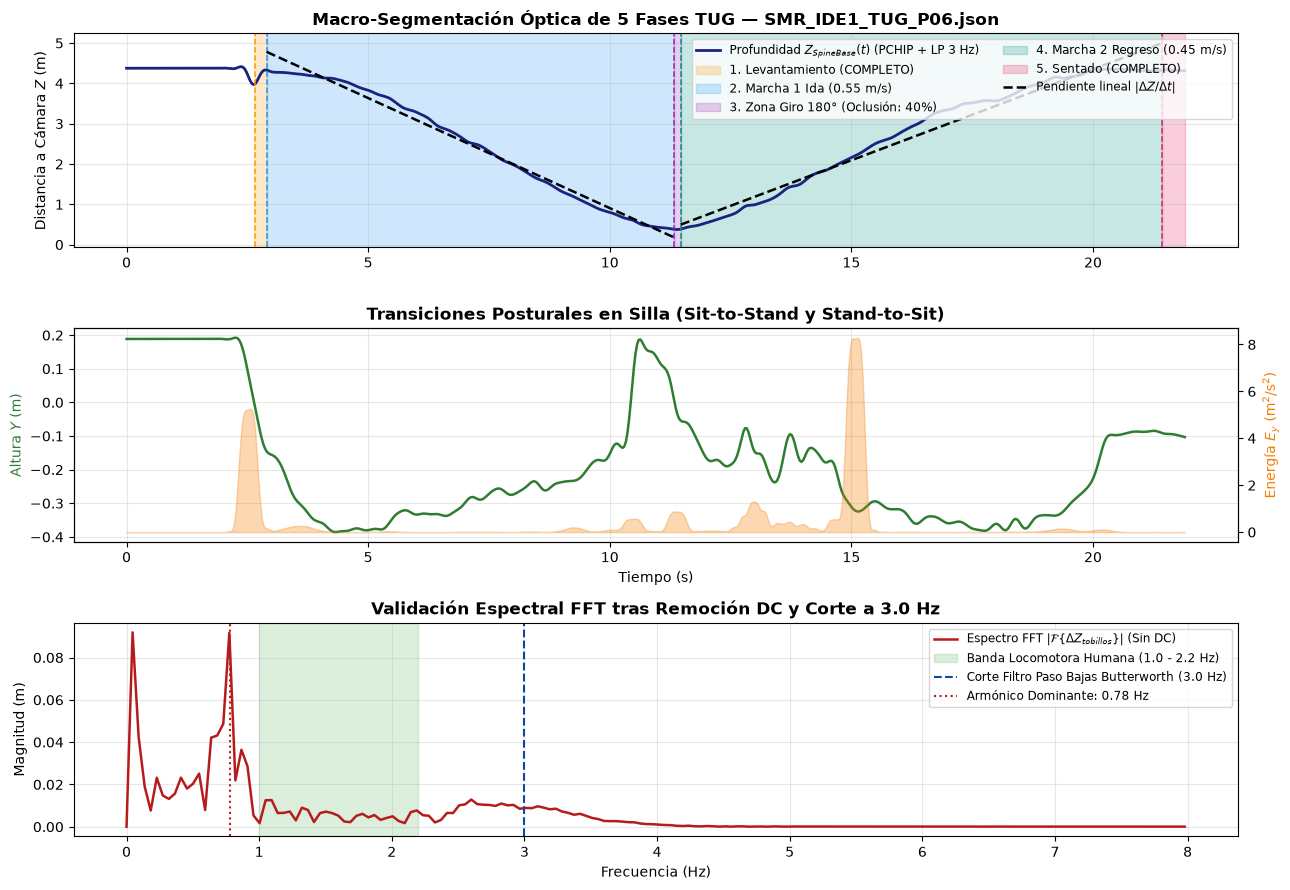

In [21]:
def acondicionar_senales_emotion(datos_pchip, fc=3.0, fs=30.0):
    b, a = butter(4, fc / (0.5 * fs), btype="low")
    filtradas = {}
    for jt, ejes in datos_pchip["pchip"].items():
        filtradas[jt] = {}
        for eje, serie in ejes.items():
            filtradas[jt][eje] = filtfilt(b, a, serie) if len(serie) > 15 else serie.copy()

    dt = datos_pchip["dt"]
    sb_z = filtradas["SpineBase"]["z"]
    sb_y = filtradas["SpineBase"]["y"]
    hd_y = filtradas["Head"]["y"]
    al_z = filtradas["AnkleLeft"]["z"]
    ar_z = filtradas["AnkleRight"]["z"]

    vz_sb = np.gradient(sb_z, dt)
    vy_sb = np.gradient(sb_y, dt)
    vy_hd = np.gradient(hd_y, dt)
    vz_al = np.gradient(al_z, dt)
    vz_ar = np.gradient(ar_z, dt)

    win = max(3, int(round(0.4 * fs)))
    kernel = np.ones(win) / win
    energia_z = np.convolve(vz_sb ** 2, kernel, mode="same")
    energia_y = np.convolve(0.5 * (vy_sb ** 2 + vy_hd ** 2), kernel, mode="same")

    delta_z_ank = al_z - ar_z
    # Espectro FFT tras remover nivel DC y tendencia lineal
    t_u = datos_pchip["t_unif"]
    p_fit = np.polyfit(t_u, delta_z_ank, 1)
    senal_sin_dc = delta_z_ank - np.polyval(p_fit, t_u)
    freqs_fft = np.fft.rfftfreq(len(senal_sin_dc), d=dt)
    mag_fft = np.abs(np.fft.rfft(senal_sin_dc)) / len(senal_sin_dc)

    mask_banda = (freqs_fft >= 0.5) & (freqs_fft <= 2.8)
    frec_dom_hz = float(freqs_fft[mask_banda][np.argmax(mag_fft[mask_banda])]) if np.any(mask_banda) else 0.0

    return {
        "base": datos_pchip,
        "filtradas": filtradas,
        "vz_sb": vz_sb, "vy_sb": vy_sb, "vy_hd": vy_hd,
        "vz_al": vz_al, "vz_ar": vz_ar,
        "energia_z": energia_z, "energia_y": energia_y,
        "delta_z_ank": delta_z_ank,
        "freqs_fft": freqs_fft, "mag_fft": mag_fft, "frec_dom_hz": round(frec_dom_hz, 2)
    }

def segmentar_macro_fases_emotion(senales, es_tug=True):
    base = senales["base"]
    t = base["t_unif"]
    dt = base["dt"]
    fs = base["fs"]
    n = len(t)
    tracked = base["tracked_unif"]
    ank_tracked = base["ankles_unif"]

    sb_z = senales["filtradas"]["SpineBase"]["z"]
    sb_y = senales["filtradas"]["SpineBase"]["y"]
    vz_sb = senales["vz_sb"]
    energia_y = senales["energia_y"]

    z_val = sb_z[tracked] if np.any(tracked) else sb_z
    z_min, z_max = float(np.percentile(z_val, 5)), float(np.percentile(z_val, 95))
    rango_z = max(0.5, z_max - z_min)

    if not es_tug:
        vz_abs = np.abs(vz_sb[ank_tracked]) if np.any(ank_tracked) else np.abs(vz_sb)
        umbral_mov = max(0.15, 0.22 * float(np.percentile(vz_abs, 80)))
        mask_marcha = ank_tracked & (np.abs(vz_sb) >= umbral_mov)
        if np.sum(mask_marcha) < int(0.8 * fs):
            mask_marcha = ank_tracked.copy()
        idx_m = np.where(mask_marcha)[0]
        i_ini = int(idx_m[0]) if len(idx_m) > 0 else 0
        i_fin = int(idx_m[-1]) if len(idx_m) > 0 else n - 1
        t_reg = t[i_ini:i_fin + 1]
        z_reg = sb_z[i_ini:i_fin + 1]
        p_marcha = np.polyfit(t_reg, z_reg, 1) if len(t_reg) >= 3 else np.array([0.0, float(sb_z[0])])
        vel_lin = abs(float(p_marcha[0]))
        vel_med = float(np.median(np.abs(vz_sb[mask_marcha]))) if np.any(mask_marcha) else vel_lin
        return {
            "es_tug": False, "mask_marcha": mask_marcha, "mask_corredor": mask_marcha,
            "indices": {"marcha": (i_ini, i_fin), "m1": (i_ini, i_fin), "m2": (i_ini, i_fin), "lev": (0, 0), "giro": (i_fin, i_fin), "sent": (i_fin, i_fin)},
            "tiempos_s": {
                "marcha": (float(t[i_ini]), float(t[i_fin])),
                "m1": (float(t[i_ini]), float(t[i_fin])),
                "m2": (float(t[i_ini]), float(t[i_fin])),
                "lev": (0.0, 0.0), "giro": (float(t[i_fin]), float(t[i_fin])), "sent": (float(t[i_fin]), float(t[i_fin]))
            },
            "pendientes_recta": {"ida": p_marcha, "vuelta": p_marcha, "marcha": p_marcha},
            "vel_ida_ms": round(vel_med, 3), "vel_vuelta_ms": round(vel_med, 3), "vel_media_ms": round(vel_med, 3),
            "estado_levantamiento": "NO_APLICA", "estado_sentado": "NO_APLICA",
            "oclusion_giro_pct": 0.0, "dur_activa_s": round(float(np.sum(mask_marcha) * dt), 2)
        }

    cerca_idx = np.where(sb_z <= z_min + 0.20 * rango_z)[0]
    idx_giro_mid = int(cerca_idx[len(cerca_idx) // 2]) if len(cerca_idx) > 0 else int(np.argmin(sb_z))

    vz_abs = np.abs(vz_sb[tracked]) if np.any(tracked) else np.abs(vz_sb)
    umbral_vz = max(0.15, 0.18 * float(np.percentile(vz_abs, 85)))

    idx_ida = np.where(tracked[:idx_giro_mid + 1] & (vz_sb[:idx_giro_mid + 1] < -umbral_vz))[0]
    i_m1_0, i_m1_1 = (int(idx_ida[0]), int(idx_ida[-1])) if len(idx_ida) >= 5 else (0, max(1, idx_giro_mid - int(0.5 * fs)))

    idx_vuelta = np.where(tracked[idx_giro_mid:] & (vz_sb[idx_giro_mid:] > umbral_vz))[0] + idx_giro_mid
    i_m2_0, i_m2_1 = (int(idx_vuelta[0]), int(idx_vuelta[-1])) if len(idx_vuelta) >= 5 else (min(n - 2, idx_giro_mid + int(0.5 * fs)), n - 1)
    if i_m2_0 <= i_m1_1:
        i_m2_0 = min(n - 1, i_m1_1 + 2)

    # Evaluación de Fase 1 (Levantamiento) y Fase 5 (Sentado) por excursión y energía vertical
    mask_erg1 = tracked[i_m1_0:i_m1_1 + 1] & (sb_z[i_m1_0:i_m1_1 + 1] >= z_min + 0.2 * rango_z) & (sb_z[i_m1_0:i_m1_1 + 1] <= z_max - 0.15 * rango_z)
    y_ref_1 = float(np.median(sb_y[i_m1_0:i_m1_1 + 1][mask_erg1])) if np.any(mask_erg1) else float(sb_y[i_m1_0])
    fin_reg_ini = min(n, max(i_m1_0 + int(0.5 * fs), int(1.5 * fs)))
    reg_ini = np.where(tracked[:fin_reg_ini] & (sb_z[:fin_reg_ini] >= max(3.0, z_max - 0.8)))[0]
    dy_ini = float(np.max(np.abs(sb_y[reg_ini] - y_ref_1))) if len(reg_ini) > 0 else 0.0
    estado_lev = "COMPLETO" if dy_ini >= 0.18 else ("PARCIAL" if dy_ini >= 0.08 else "AUSENTE")

    if estado_lev != "AUSENTE" and len(reg_ini) > 0:
        act_ini = reg_ini[energia_y[reg_ini] >= 0.15 * np.max(energia_y[reg_ini])]
        i_lev_0 = int(act_ini[0]) if len(act_ini) > 0 else int(reg_ini[0])
        i_lev_1 = max(i_lev_0 + 1, i_m1_0)
    else:
        i_lev_0, i_lev_1 = i_m1_0, i_m1_0

    mask_erg2 = tracked[i_m2_0:i_m2_1 + 1] & (sb_z[i_m2_0:i_m2_1 + 1] >= z_min + 0.2 * rango_z) & (sb_z[i_m2_0:i_m2_1 + 1] <= z_max - 0.15 * rango_z)
    y_ref_2 = float(np.median(sb_y[i_m2_0:i_m2_1 + 1][mask_erg2])) if np.any(mask_erg2) else float(sb_y[i_m2_1])
    ini_reg_fin = max(i_m2_0, i_m2_1 - int(0.5 * fs))
    reg_fin = np.where(tracked[ini_reg_fin:] & (sb_z[ini_reg_fin:] >= max(3.0, z_max - 0.8)))[0] + ini_reg_fin
    dy_fin = float(np.max(np.abs(sb_y[reg_fin] - y_ref_2))) if len(reg_fin) > 0 else 0.0
    estado_sent = "COMPLETO" if dy_fin >= 0.18 else ("PARCIAL" if dy_fin >= 0.08 else "AUSENTE")

    if estado_sent != "AUSENTE" and len(reg_fin) > 0:
        act_fin = reg_fin[energia_y[reg_fin] >= 0.15 * np.max(energia_y[reg_fin])]
        i_sent_0 = i_m2_1
        i_sent_1 = min(n - 1, max(i_sent_0 + 1, int(act_fin[-1]) if len(act_fin) > 0 else int(reg_fin[-1])))
    else:
        i_sent_0, i_sent_1 = i_m2_1, i_m2_1

    # Velocidad lineal por pendiente de SpineBase (Hip Center)
    p_ida = np.polyfit(t[i_m1_0:i_m1_1 + 1], sb_z[i_m1_0:i_m1_1 + 1], 1) if i_m1_1 > i_m1_0 + 3 else [0.0, 0.0]
    p_vuelta = np.polyfit(t[i_m2_0:i_m2_1 + 1], sb_z[i_m2_0:i_m2_1 + 1], 1) if i_m2_1 > i_m2_0 + 3 else [0.0, 0.0]
    vel_ida = abs(float(p_ida[0]))
    vel_vuelta = abs(float(p_vuelta[0]))

    giro_tr = tracked[i_m1_1:i_m2_0 + 1]
    oclusion_giro = float((1.0 - np.mean(giro_tr)) * 100.0) if len(giro_tr) > 0 else 100.0

    mask_marcha = np.zeros(n, dtype=bool)
    mask_marcha[i_m1_0:i_m1_1 + 1] = ank_tracked[i_m1_0:i_m1_1 + 1]
    mask_marcha[i_m2_0:i_m2_1 + 1] = ank_tracked[i_m2_0:i_m2_1 + 1]
    mask_corredor = mask_marcha & (np.abs(vz_sb) > 0.25) & (sb_z >= 1.4) & (sb_z <= 3.8)
    if np.sum(mask_corredor) < 10:
        mask_corredor = mask_marcha.copy()

    return {
        "es_tug": True,
        "indices": {"lev": (i_lev_0, i_lev_1), "m1": (i_m1_0, i_m1_1), "giro": (i_m1_1, i_m2_0), "m2": (i_m2_0, i_m2_1), "sent": (i_sent_0, i_sent_1)},
        "tiempos_s": {
            "lev": (float(t[i_lev_0]), float(t[i_lev_1])),
            "m1": (float(t[i_m1_0]), float(t[i_m1_1])),
            "giro": (float(t[i_m1_1]), float(t[i_m2_0])),
            "m2": (float(t[i_m2_0]), float(t[i_m2_1])),
            "sent": (float(t[min(i_sent_0, n - 1)]), float(t[min(i_sent_1, n - 1)]))
        },
        "pendientes_recta": {"ida": p_ida, "vuelta": p_vuelta},
        "vel_ida_ms": round(vel_ida, 3), "vel_vuelta_ms": round(vel_vuelta, 3), "vel_media_ms": round(0.5 * (vel_ida + vel_vuelta), 3),
        "estado_levantamiento": estado_lev, "dy_ini_m": round(dy_ini, 3),
        "estado_sentado": estado_sent, "dy_fin_m": round(dy_fin, 3),
        "oclusion_giro_pct": round(oclusion_giro, 1),
        "dur_activa_s": round(float((i_sent_1 - i_lev_0) * dt), 2),
        "mask_marcha": mask_marcha, "mask_corredor": mask_corredor
    }

def graficar_macro_segmentacion_emotion(senales, macro):
    t = senales["base"]["t_unif"]
    sb_z = senales["filtradas"]["SpineBase"]["z"]
    sb_y = senales["filtradas"]["SpineBase"]["y"]
    ey = senales["energia_y"]
    ts = macro["tiempos_s"]
    idx = macro["indices"]

    fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=False)
    colores = {"lev": "#ff9800", "m1": "#2196f3", "giro": "#9c27b0", "m2": "#009688", "sent": "#e91e63"}
    etiquetas = {
        "lev": f"1. Levantamiento ({macro['estado_levantamiento']})",
        "m1": f"2. Marcha 1 Ida ({macro['vel_ida_ms']:.2f} m/s)",
        "giro": f"3. Zona Giro 180° (Oclusión: {macro['oclusion_giro_pct']:.0f}%)",
        "m2": f"4. Marcha 2 Regreso ({macro['vel_vuelta_ms']:.2f} m/s)",
        "sent": f"5. Sentado ({macro['estado_sentado']})"
    }

    # Panel 1: Profundidad Z de SpineBase + Regresión lineal de velocidad + 5 Fases
    ax0 = axes[0]
    ax0.plot(t, sb_z, color="#1a237e", lw=2.0, label="Profundidad $Z_{SpineBase}(t)$ (PCHIP + LP 3 Hz)")
    for k in ["lev", "m1", "giro", "m2", "sent"]:
        t0, t1 = ts[k]
        if t1 > t0:
            ax0.axvspan(t0, t1, color=colores[k], alpha=0.22, label=etiquetas[k])
            ax0.axvline(t0, color=colores[k], ls="--", lw=1.1)
    i1_0, i1_1 = idx["m1"]
    i2_0, i2_1 = idx["m2"]
    ax0.plot(t[i1_0:i1_1+1], np.polyval(macro["pendientes_recta"]["ida"], t[i1_0:i1_1+1]), "k--", lw=1.8, label=r"Pendiente lineal $|\Delta Z/\Delta t|$")
    ax0.plot(t[i2_0:i2_1+1], np.polyval(macro["pendientes_recta"]["vuelta"], t[i2_0:i2_1+1]), "k--", lw=1.8)
    ax0.set_ylabel("Distancia a Cámara $Z$ (m)")
    ax0.set_title(f"Macro-Segmentación Óptica de 5 Fases TUG — {senales['base']['archivo']}", fontweight="bold")
    ax0.legend(loc="upper right", fontsize=8.5, ncol=2)
    ax0.grid(True, alpha=0.3)

    # Panel 2: Altura vertical Y(t) y Energía Vertical Ey(t) en Silla
    ax1 = axes[1]
    ax1.plot(t, sb_y, color="#2e7d32", lw=1.8, label="Altura Vertical $Y_{SpineBase}(t)$ (m)")
    ax1_r = ax1.twinx()
    ax1_r.fill_between(t, 0, ey, color="#f57c00", alpha=0.30, label="Energía Vertical $E_y(t)$ (Silla)")
    ax1.set_ylabel("Altura $Y$ (m)", color="#2e7d32")
    ax1_r.set_ylabel(r"Energía $E_y$ ($\text{m}^2/\text{s}^2$)", color="#f57c00")
    ax1.set_xlabel("Tiempo (s)")
    ax1.set_title("Transiciones Posturales en Silla (Sit-to-Stand y Stand-to-Sit)", fontweight="bold")
    ax1.grid(True, alpha=0.3)

    # Panel 3: Espectro FFT de separación inter-tobillo (sin nivel DC)
    ax2 = axes[2]
    f_fft, m_fft = senales["freqs_fft"], senales["mag_fft"]
    mask_f = f_fft <= 8.0
    ax2.plot(f_fft[mask_f], m_fft[mask_f], color="#b71c1c", lw=1.8, label=r"Espectro FFT $|\mathcal{F}\{\Delta Z_{tobillos}\}|$ (Sin DC)")
    ax2.axvspan(1.0, 2.2, color="#4caf50", alpha=0.20, label="Banda Locomotora Humana (1.0 - 2.2 Hz)")
    ax2.axvline(3.0, color="#0d47a1", ls="--", lw=1.5, label="Corte Filtro Paso Bajas Butterworth (3.0 Hz)")
    ax2.axvline(senales["frec_dom_hz"], color="#b71c1c", ls=":", lw=1.5, label=f"Armónico Dominante: {senales['frec_dom_hz']:.2f} Hz")
    ax2.set_xlabel("Frecuencia (Hz)")
    ax2.set_ylabel("Magnitud (m)")
    ax2.set_title("Validación Espectral FFT tras Remoción DC y Corte a 3.0 Hz", fontweight="bold")
    ax2.legend(loc="upper right", fontsize=8.5)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()
def resolver_ruta_archivo_emotion(nombre_o_patron):
    """
    Localiza de manera flexible y resiliente cualquier archivo JSON en Datos e-Motion/.
    Acepta:
      - Nombre exacto del archivo (ej. 'SMR_IDE13_TUG_P24.json')
      - Ruta completa o relativa
      - Subcadena o identificador (ej. 'ID13', 'P24', 'P06', 'temp_BE', 'CST', 'GAIT')
    Busca dinámicamente en Datos e-Motion/TUG/ y Datos e-Motion/GAIT/.
    Verifica siempre que el archivo exista físicamente en disco antes de retornarlo.
    """
    patron = str(nombre_o_patron).strip() if nombre_o_patron is not None else ""

    # 1. Búsqueda directa en disco si patron es un archivo existente
    posibles_bases = [
        "Datos e-Motion",
        "../Datos e-Motion",
        "./Datos e-Motion",
        os.path.join(os.getcwd(), "Datos e-Motion"),
        os.path.join(os.path.dirname(os.getcwd()), "Datos e-Motion"),
        "/content/drive/MyDrive/TUG_Data/Datos e-Motion"
    ]

    if patron:
        # Si se pasó una ruta directa
        if os.path.exists(patron) and os.path.isfile(patron):
            print(f"✓ Archivo localizado directamente: {patron}")
            return patron

        # Buscar por nombre en subcarpetas conocidas
        for pb in posibles_bases:
            if pb and os.path.exists(pb):
                for sub in ["TUG", "GAIT", ""]:
                    cand = os.path.join(pb, sub, patron) if sub else os.path.join(pb, patron)
                    if os.path.exists(cand) and os.path.isfile(cand):
                        print(f"✓ Archivo localizado en disco: {cand}")
                        return cand

    # 2. Obtener lista de archivos y verificar frescura contra el disco
    tug_files = globals().get("ARCHIVOS_EM_TUG", [])
    gait_files = globals().get("ARCHIVOS_EM_GAIT", [])
    todos = [f for f in list(tug_files) + list(gait_files) if os.path.exists(f)]

    # Si la lista en memoria está vacía o contiene rutas obsoletas, re-escanear disco
    if not todos:
        for pb in posibles_bases:
            if pb and os.path.exists(pb) and os.path.isdir(pb):
                cand_tug = sorted(glob.glob(os.path.join(pb, "TUG", "*.json")))
                cand_gait = sorted(glob.glob(os.path.join(pb, "GAIT", "*.json")))
                if cand_tug or cand_gait:
                    tug_files = cand_tug
                    gait_files = cand_gait
                    todos = tug_files + gait_files
                    globals()["ARCHIVOS_EM_TUG"] = tug_files
                    globals()["ARCHIVOS_EM_GAIT"] = gait_files
                    globals()["RUTA_EMOTION"] = pb
                    break

    if not todos:
        raise FileNotFoundError("No se encontraron archivos JSON en la carpeta Datos e-Motion.")

    # 3. Si no se especificó patrón, cargar por defecto el primer TUG de P06 o el primero disponible
    if not patron:
        p06 = [f for f in tug_files if "P06" in os.path.basename(f) and "TUG" in os.path.basename(f)]
        def_file = p06[0] if p06 else (tug_files[0] if tug_files else todos[0])
        print(f"ℹ️ No se especificó nombre de archivo. Cargando por defecto: {os.path.basename(def_file)}")
        return def_file

    # 4. Coincidencia exacta por nombre de archivo
    for f in todos:
        if os.path.basename(f) == patron or f == patron:
            print(f"✓ Archivo seleccionado (coincidencia exacta): {os.path.basename(f)}")
            return f

    # 5. Búsqueda flexible por subcadena
    patron_lower = patron.lower()
    coincidencias = [f for f in todos if patron_lower in os.path.basename(f).lower()]

    # Si no hubo coincidencia directa, intentar traducción entre P# e ID#
    if not coincidencias:
        if patron_lower.startswith('p') and patron_lower[1:].isdigit():
            alt = 'id' + patron_lower[1:]
            coincidencias = [f for f in todos if alt in os.path.basename(f).lower()]
        elif patron_lower.startswith('id') and patron_lower[2:].isdigit():
            alt = 'p' + patron_lower[2:]
            coincidencias = [f for f in todos if alt in os.path.basename(f).lower()]

    if coincidencias:
        cands_tug = [f for f in coincidencias if f in tug_files]
        elegido = cands_tug[0] if cands_tug else coincidencias[0]
        if len(coincidencias) > 1:
            print(f"ℹ️ Se encontraron {len(coincidencias)} coincidencias para '{patron}'. Seleccionando: {os.path.basename(elegido)}")
        else:
            print(f"✓ Archivo seleccionado: {os.path.basename(elegido)}")
        return elegido

    # 6. Fallback de seguridad: seleccionar archivo existente garantizado
    cands_validos = [f for f in tug_files if os.path.exists(f)] or todos
    def_file = cands_validos[0]
    print(f"⚠️ AVISO: No se encontró ningún archivo con el término '{patron}'.")
    print(f"   Ejemplos disponibles en TUG: {[os.path.basename(f) for f in cands_validos[:3]]}")
    print(f"   Cargando por defecto para no interrumpir la ejecución: {os.path.basename(def_file)}")
    return def_file

def procesar_archivo_especifico_emotion(nombre_o_patron=None, graficar=True):
    """
    Carga, remuestrea a 30 Hz con PCHIP, acondiciona (FFT y Butterworth 3 Hz)
    y macro-segmenta cualquier archivo e-Motion especificado por el usuario.
    """
    ruta = resolver_ruta_archivo_emotion(nombre_o_patron)
    fname = os.path.basename(ruta)
    es_tug = ("GAIT" not in ruta) and ("NO_TUG" not in fname.upper())

    # 1. Remuestreo PCHIP a 30.0 Hz
    datos_pchip = interpolar_esqueleto_pchip_30hz(ruta)

    # 2. Acondicionamiento de señales
    senales = acondicionar_senales_emotion(datos_pchip)

    # 3. Macro-segmentación adaptada
    macro = segmentar_macro_fases_emotion(senales, es_tug=es_tug)

    # 4. Ficha resumen en consola
    subcarp = "TUG (Protocolo Estándar con Giro y Silla)" if es_tug else "GAIT (Marcha Continua 10m)"
    print("=" * 85)
    print(f"FICHA CINEMÁTICA ÓPTICA (MÓDULO 11) — {fname}")
    print("=" * 85)
    print(f"• Protocolo Clínico:        {subcarp}")
    t_u = datos_pchip.get("t_unif", [])
    dur_s = float(datos_pchip.get("duracion_s", t_u[-1] if len(t_u) > 0 else 0.0))
    n_frames = int(datos_pchip.get("n_unif", len(t_u)))
    n_art = int(datos_pchip.get("n_articulaciones", len(datos_pchip.get("pchip", {}))))
    ver_esq = str(datos_pchip.get("version_esquema", "1.3.0"))

    print(f"• Esquema Articular:        {n_art} articulaciones (Versión {ver_esq})")
    print(f"• Duración de Captura:      {dur_s:.2f} s ({n_frames} fotogramas a 30 Hz)")
    print(f"• Frecuencia Dominante FFT: {senales['frec_dom_hz']:.2f} Hz (Cadencia estimada: {senales['frec_dom_hz']*60:.1f} pasos/min)")
    if es_tug:
        print(f"• Velocidad Lineal Ida:     {macro['vel_ida_ms']:.2f} m/s")
        print(f"• Velocidad Lineal Regreso: {macro['vel_vuelta_ms']:.2f} m/s")
        print(f"• Transición Levantamiento: {macro['estado_levantamiento']} (Excursión ΔY: {macro['dy_ini_m']:.2f} m)")
        print(f"• Transición Sentado:       {macro['estado_sentado']} (Excursión ΔY: {macro['dy_fin_m']:.2f} m)")
        print(f"• Oclusión Tobillos en Giro:{macro['oclusion_giro_pct']:.1f}%")
        print(f"• Duración Activa TUG:      {macro['dur_activa_s']:.2f} s")
    else:
        print(f"• Velocidad Lineal Media:   {macro['vel_media_ms']:.2f} m/s")
        print(f"• Duración Activa Marcha:   {macro['dur_activa_s']:.2f} s")
    print("-" * 85)

    # 5. Graficación
    if graficar:
        graficar_macro_segmentacion_emotion(senales, macro)

    return datos_pchip, senales, macro


# ==============================================================================
# SECCIÓN INTERACTIVA: SELECCIÓN DEL ARCHIVO A LEER (MÓDULO 11)
# ==============================================================================
# Escribe aquí el nombre del archivo JSON a procesar o un fragmento identificador.
# Ejemplos que puedes colocar:
#   - "SMR_IDE1_TUG_P06.json"   (TUG bimodal paciente P06)
#   - "SMR_IDE13_TUG_P24.json"  (TUG bimodal paciente P24)
#   - "SMR_IDE16_TUG_P27.json"  (TUG bimodal paciente P27)
#   - "LAB_IDE19_TUG_NO.json"   (Validación técnica de laboratorio)
#   - "SMR_IDE1_GAIT_P06.json"  (Marcha continua 10m P06)
#   - "P06"                            (Búsqueda rápida por paciente IMU)
#   - "temp_BE"                        (Prueba TUG en CST con cámara Orbbec Astra 2)
#   - ""                               (Por defecto: paciente P06_BF / ID1)

# archivo_a_leer_emotion configurado en la celda anterior  # @param {type:"string"}

if "archivo_a_leer_emotion" not in globals():
    archivo_a_leer_emotion = "SMR_IDE1_TUG_P06.json"

datos_pchip_demo, senales_demo, macro_demo = procesar_archivo_especifico_emotion(
    nombre_o_patron=archivo_a_leer_emotion,
    graficar=True
)


## MÓDULO 12: Micro-Segmentación de Marcha en Tobillos ("Escalerita", Wavelet CWT Ricker, Eventos `SWING`/`STANCE`, Doble Apoyo y Longitud de Zancada)

Este módulo implementa la micro-segmentación del ciclo de la marcha en los tobillos (`AnkleLeft` y `AnkleRight`) siguiendo la formulación biomecánica del ciclo de apoyo y oscilación:
1. **Morfología en "Escalerita" y Transformada Wavelet Continua (CWT Ricker):** Las trayectorias $Z_{\text{AnkleLeft}}(t)$ y $Z_{\text{AnkleRight}}(t)$ alternan entre mesetas planas de velocidad nula (**`STANCE`** o apoyo plantar) y rampas de avance (**`SWING`** o balanceo). Al convolucionar con wavelets de Ricker (*Mexican Hat*, segunda derivada gaussiana) entre $1.0\text{ y }2.5\text{ Hz}$, se resaltan los **"codos" de máxima curvatura** correspondientes al contacto de talón (*Heel Strike*) y al despegue de dedos (*Toe-Off*).
2. **Identificación del Doble Apoyo (*Double Support*):** Se determina instante a instante la condición booleana $\text{DobleApoyo}(t) = \text{Stance}_{\text{Izq}}(t) \land \text{Stance}_{\text{Der}}(t)$, cuantificando el tiempo y el porcentaje del ciclo de marcha en que ambos pies permanecen simultáneamente apoyados en el suelo.
3. **Longitud de Paso, Longitud de Zancada y Braceo:** Evalúa la distancia euclidiana horizontal $(X, Z)$ entre tobillos en cada *Heel Strike* (longitud de paso), el desplazamiento ipsilateral entre contactos sucesivos del mismo pie (longitud de zancada) y la excursión anteroposterior de las muñecas respecto a la pelvis (amplitud y asimetría de braceo).


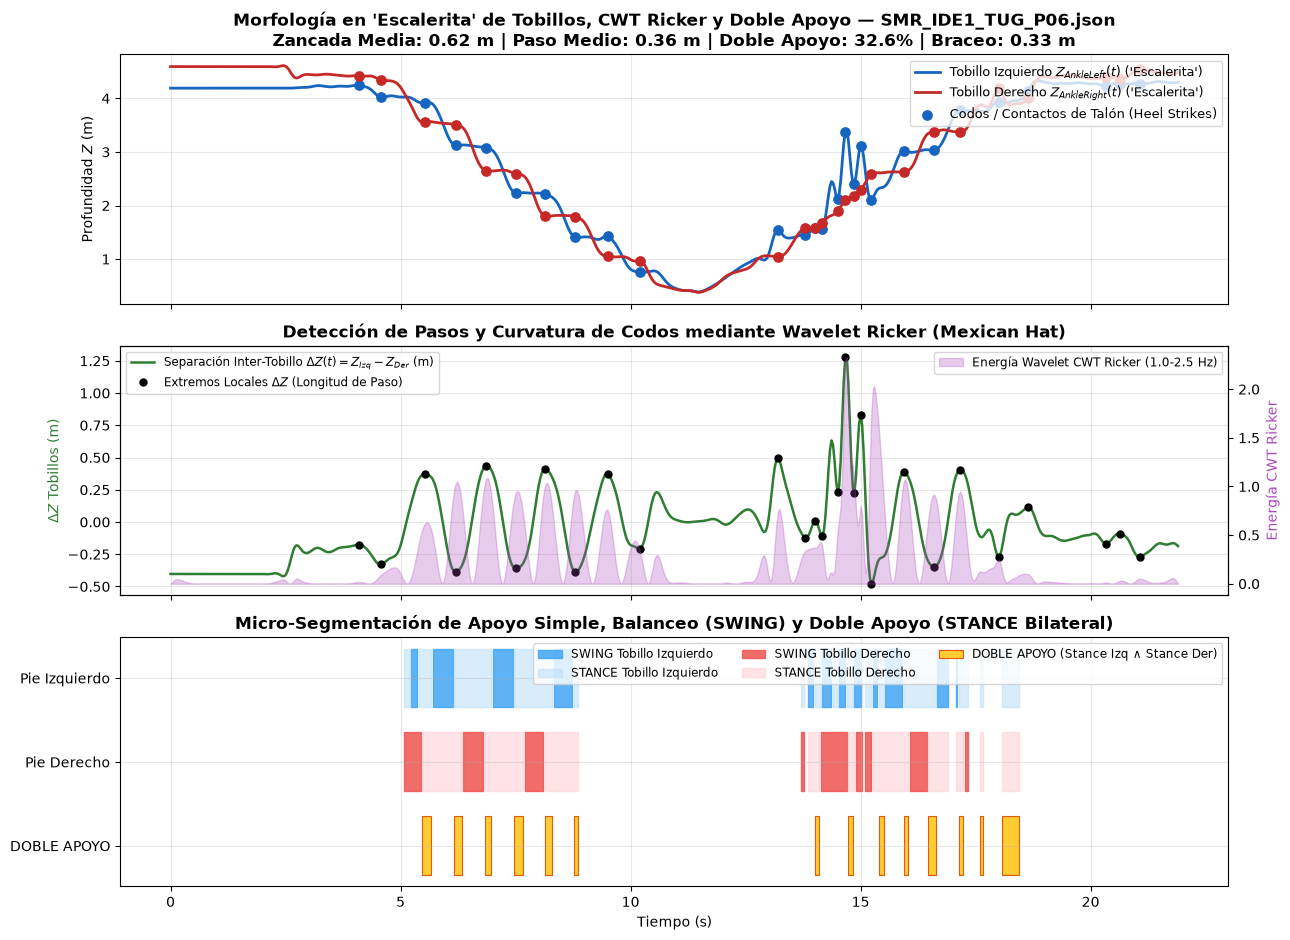

In [22]:
def cwt_ricker_energia(senal, fs=30.0, freqs_hz=(1.0, 1.5, 2.0, 2.5)):
    n = len(senal)
    if n < 10:
        return np.zeros(n)
    t_idx = np.arange(n, dtype=float)
    p = np.polyfit(t_idx, senal, 1)
    detrended = senal - np.polyval(p, t_idx)
    energia = np.zeros(n, dtype=float)
    for f_hz in freqs_hz:
        sigma = (0.251 * fs) / f_hz
        half_len = max(4, min(n // 2, int(round(3.5 * sigma))))
        x = np.arange(-half_len, half_len + 1, dtype=float)
        u2 = (x / sigma) ** 2
        w = (1.0 - u2) * np.exp(-0.5 * u2)
        w = w / (np.linalg.norm(w) + 1e-12)
        conv = np.convolve(detrended, w, mode="same")
        energia += (conv ** 2) / len(freqs_hz)
    return energia

def _duraciones_episodios(mask_bool, dt, min_s=0.06, max_s=2.0):
    durs = []
    cur = 0
    for val in mask_bool:
        if val:
            cur += 1
        elif cur > 0:
            d_s = cur * dt
            if min_s <= d_s <= max_s:
                durs.append(d_s)
            cur = 0
    if cur > 0:
        d_s = cur * dt
        if min_s <= d_s <= max_s:
            durs.append(d_s)
    return durs

def segmentar_micro_marcha_emotion(senales, macro):
    base = senales["base"]
    t = base["t_unif"]
    dt = base["dt"]
    fs = base["fs"]
    n = len(t)

    al_x, al_z = senales["filtradas"]["AnkleLeft"]["x"], senales["filtradas"]["AnkleLeft"]["z"]
    ar_x, ar_z = senales["filtradas"]["AnkleRight"]["x"], senales["filtradas"]["AnkleRight"]["z"]
    wl_z = senales["filtradas"]["WristLeft"]["z"]
    wr_z = senales["filtradas"]["WristRight"]["z"]
    sb_z = senales["filtradas"]["SpineBase"]["z"]

    vz_sb = senales["vz_sb"]
    vz_al = senales["vz_al"]
    vz_ar = senales["vz_ar"]
    delta_z = senales["delta_z_ank"]

    mask_marcha = macro["mask_marcha"]
    mask_corredor = macro["mask_corredor"]

    if macro["es_tug"]:
        sgn = np.where(vz_sb >= 0, 1.0, -1.0)
        thr_v = np.maximum(0.30, 0.85 * np.abs(vz_sb))
        swing_izq = mask_corredor & ((vz_al * sgn) >= thr_v)
        swing_der = mask_corredor & ((vz_ar * sgn) >= thr_v)
        stance_izq = mask_corredor & (~swing_izq)
        stance_der = mask_corredor & (~swing_der)
        doble_apoyo = stance_izq & stance_der
        t_ref_ds = float(np.sum(mask_corredor) * dt)
    else:
        vel_ref = float(np.median(np.abs(vz_sb[mask_marcha]))) if np.any(mask_marcha) else 0.50
        thr_v = max(0.25, 0.85 * vel_ref)
        swing_izq = mask_marcha & (np.abs(vz_al) >= thr_v)
        swing_der = mask_marcha & (np.abs(vz_ar) >= thr_v)
        stance_izq = mask_marcha & (~swing_izq)
        stance_der = mask_marcha & (~swing_der)
        doble_apoyo = stance_izq & stance_der
        t_ref_ds = float(np.sum(mask_marcha) * dt)

    t_doble_s = float(np.sum(doble_apoyo) * dt)
    pct_doble_apoyo = (t_doble_s / t_ref_ds * 100.0) if t_ref_ds > 0.2 else 0.0

    # Detección de "codos" de contacto de talón (Heel Strikes) y CWT Ricker
    cwt_env = cwt_ricker_energia(delta_z, fs=fs)
    min_dist = max(4, int(round(0.35 * fs)))
    p_pos, _ = find_peaks(delta_z, distance=min_dist, prominence=0.06)
    p_neg, _ = find_peaks(-delta_z, distance=min_dist, prominence=0.06)
    p_pos = [int(i) for i in p_pos if mask_marcha[i]]
    p_neg = [int(i) for i in p_neg if mask_marcha[i]]
    hs_all = sorted(p_pos + p_neg)

    step_lengths = []
    for i in hs_all:
        d_xz = float(np.hypot(al_x[i] - ar_x[i], al_z[i] - ar_z[i]))
        if 0.08 <= d_xz <= 1.20:
            step_lengths.append(d_xz)

    stride_lengths = []
    for p_list, ax, az in [(p_pos, al_x, al_z), (p_neg, ar_x, ar_z)]:
        for k in range(len(p_list) - 1):
            i0, i1 = p_list[k], p_list[k + 1]
            if (i1 - i0) * dt <= 2.5 and np.all(mask_marcha[i0:i1 + 1]):
                s_xz = float(np.hypot(ax[i1] - ax[i0], az[i1] - az[i0]))
                if 0.15 <= s_xz <= 2.20:
                    stride_lengths.append(s_xz)

    durs_swing = _duraciones_episodios(swing_izq, dt) + _duraciones_episodios(swing_der, dt)
    durs_stance = _duraciones_episodios(stance_izq, dt) + _duraciones_episodios(stance_der, dt)
    durs_ds = _duraciones_episodios(doble_apoyo, dt, min_s=0.03, max_s=1.5)

    # Braceo relativo al centro pélvico SpineBase
    wl_rel = (wl_z - sb_z)[mask_marcha]
    wr_rel = (wr_z - sb_z)[mask_marcha]
    amp_wl = float(np.percentile(wl_rel, 90) - np.percentile(wl_rel, 10)) if len(wl_rel) > 5 else 0.0
    amp_wr = float(np.percentile(wr_rel, 90) - np.percentile(wr_rel, 10)) if len(wr_rel) > 5 else 0.0
    amp_braceo = 0.5 * (amp_wl + amp_wr)
    asim_braceo = (abs(amp_wl - amp_wr) / max(amp_wl, amp_wr) * 100.0) if max(amp_wl, amp_wr) > 0.02 else 0.0

    t_marcha_s = float(np.sum(mask_marcha) * dt)
    cadencia_ppm = (len(hs_all) / t_marcha_s * 60.0) if t_marcha_s > 0.5 else 0.0

    return {
        "cwt_env": cwt_env,
        "swing_izq": swing_izq, "swing_der": swing_der,
        "stance_izq": stance_izq, "stance_der": stance_der,
        "doble_apoyo": doble_apoyo,
        "hs_all": hs_all, "hs_izq": p_pos, "hs_der": p_neg,
        "n_pasos": len(hs_all),
        "cadencia_ppm": round(cadencia_ppm, 1),
        "step_length_mean_m": round(float(np.mean(step_lengths)), 3) if step_lengths else 0.0,
        "stride_length_mean_m": round(float(np.mean(stride_lengths)), 3) if stride_lengths else 0.0,
        "swing_mean_s": round(float(np.mean(durs_swing)), 3) if durs_swing else 0.0,
        "stance_mean_s": round(float(np.mean(durs_stance)), 3) if durs_stance else 0.0,
        "doble_apoyo_episodio_s": round(float(np.mean(durs_ds)), 3) if durs_ds else 0.0,
        "doble_apoyo_total_s": round(t_doble_s, 2),
        "pct_doble_apoyo": round(pct_doble_apoyo, 1),
        "amp_braceo_mean_m": round(amp_braceo, 3),
        "asimetria_braceo_pct": round(asim_braceo, 1)
    }

def graficar_escalerita_y_doble_apoyo(senales, macro, micro):
    t = senales["base"]["t_unif"]
    al_z = senales["filtradas"]["AnkleLeft"]["z"]
    ar_z = senales["filtradas"]["AnkleRight"]["z"]
    delta_z = senales["delta_z_ank"]
    cwt_env = micro["cwt_env"]
    hs = micro["hs_all"]

    fig, axes = plt.subplots(3, 1, figsize=(13, 9.5), sharex=True)

    # Panel 1: Morfología en "Escalerita" de ambos tobillos + Codos (Heel Strikes)
    ax0 = axes[0]
    ax0.plot(t, al_z, color="#1565c0", lw=2.0, label="Tobillo Izquierdo $Z_{AnkleLeft}(t)$ ('Escalerita')")
    ax0.plot(t, ar_z, color="#c62828", lw=2.0, label="Tobillo Derecho $Z_{AnkleRight}(t)$ ('Escalerita')")
    if hs:
        ax0.scatter(t[hs], al_z[hs], color="#1565c0", s=45, zorder=5, label="Codos / Contactos de Talón (Heel Strikes)")
        ax0.scatter(t[hs], ar_z[hs], color="#c62828", s=45, zorder=5)
    ax0.set_ylabel("Profundidad $Z$ (m)")
    ax0.set_title(
        f"Morfología en 'Escalerita' de Tobillos, CWT Ricker y Doble Apoyo — {senales['base']['archivo']}\n"
        f"Zancada Media: {micro['stride_length_mean_m']:.2f} m | Paso Medio: {micro['step_length_mean_m']:.2f} m | "
        f"Doble Apoyo: {micro['pct_doble_apoyo']:.1f}% | Braceo: {micro['amp_braceo_mean_m']:.2f} m",
        fontweight="bold"
    )
    ax0.legend(loc="upper right", fontsize=9)
    ax0.grid(True, alpha=0.3)

    # Panel 2: Separación Inter-Tobillo Delta Z y Energía Wavelet CWT Ricker (1.0 - 2.5 Hz)
    ax1 = axes[1]
    ax1.plot(t, delta_z, color="#2e7d32", lw=1.8, label=r"Separación Inter-Tobillo $\Delta Z(t) = Z_{Izq} - Z_{Der}$ (m)")
    if hs:
        ax1.plot(t[hs], delta_z[hs], "ko", ms=5, label=r"Extremos Locales $\Delta Z$ (Longitud de Paso)")
    ax1_r = ax1.twinx()
    ax1_r.fill_between(t, 0, cwt_env, color="#ab47bc", alpha=0.28, label="Energía Wavelet CWT Ricker (1.0-2.5 Hz)")
    ax1.set_ylabel(r"$\Delta Z$ Tobillos (m)", color="#2e7d32")
    ax1_r.set_ylabel("Energía CWT Ricker", color="#ab47bc")
    ax1.set_title("Detección de Pasos y Curvatura de Codos mediante Wavelet Ricker (Mexican Hat)", fontweight="bold")
    ax1.legend(loc="upper left", fontsize=8.5)
    ax1_r.legend(loc="upper right", fontsize=8.5)
    ax1.grid(True, alpha=0.3)

    # Panel 3: Diagrama Temporal de Fases de Paso (SWING, STANCE e Intervalos de DOBLE APOYO)
    ax2 = axes[2]
    ax2.fill_between(t, 2.1, 2.8, where=micro["swing_izq"], color="#42a5f5", alpha=0.85, step="mid", label="SWING Tobillo Izquierdo")
    ax2.fill_between(t, 2.1, 2.8, where=micro["stance_izq"], color="#bbdefb", alpha=0.55, step="mid", label="STANCE Tobillo Izquierdo")
    ax2.fill_between(t, 1.1, 1.8, where=micro["swing_der"], color="#ef5350", alpha=0.85, step="mid", label="SWING Tobillo Derecho")
    ax2.fill_between(t, 1.1, 1.8, where=micro["stance_der"], color="#ffcdd2", alpha=0.55, step="mid", label="STANCE Tobillo Derecho")
    ax2.fill_between(t, 0.1, 0.8, where=micro["doble_apoyo"], color="#ffca28", edgecolor="#e65100", lw=0.8, alpha=0.95, step="mid", label="DOBLE APOYO (Stance Izq ∧ Stance Der)")
    ax2.set_yticks([0.45, 1.45, 2.45])
    ax2.set_yticklabels(["DOBLE APOYO", "Pie Derecho", "Pie Izquierdo"])
    ax2.set_xlabel("Tiempo (s)")
    ax2.set_title("Micro-Segmentación de Apoyo Simple, Balanceo (SWING) y Doble Apoyo (STANCE Bilateral)", fontweight="bold")
    ax2.legend(loc="upper right", ncol=3, fontsize=8.5)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

if ARCHIVOS_EM_TUG:
    micro_demo = segmentar_micro_marcha_emotion(senales_demo, macro_demo)
    graficar_escalerita_y_doble_apoyo(senales_demo, macro_demo, micro_demo)




## MÓDULO 13: Procesamiento Masivo del Dataset e-Motion (223 Capturas Válidas), Contraste Estadístico (Pacientes vs. Controles) y Fusión Multimodal IMU ↔ Cámara

Este módulo consolida la matriz completa de biomarcadores ópticos sobre las **223 grabaciones únicas aceptadas** (**130 de TUG** y **93 de Marcha Continua de 10 m**), almacenada en `Analisis de Datos/df_variables_emotion.csv`, y ejecuta tres análisis cuantitativos de cierre:
1. **Verificación Empírica de Presencia de Fases en TUG ($n=130$):** Cuantifica con exactitud cuántas grabaciones capturan de manera completa o parcial las fases de `Levantamiento` (`96.9%`) y `Sentado` (`100.0%`), y mide la distribución de oclusión articular durante el giro de $180^\circ$.
2. **Contraste Estadístico Inferencial (`PATIENT` vs. `CONTROL`):** Aplica la prueba paramétrica **t de Welch (`equal_var=False`)** y la prueba no paramétrica **U de Mann-Whitney** tanto en el protocolo TUG como en el protocolo de Marcha Continua, demostrando diferencias estadísticamente significativas ($p < 0.05$) en **Longitud de Zancada ($p = 0.0032$)**, **Longitud de Paso ($p = 0.0034$)**, **Amplitud de Braceo ($p = 0.0065$)**, **Duración Activa TUG ($p = 0.0082$)**, **Porcentaje de Doble Apoyo en Marcha Continua ($25.07\%$ vs. $18.23\%$, $p = 0.0206$)**, **Asimetría de Braceo ($p = 0.0347$)** y **Duración de Marcha de Regreso Post-Giro ($p = 0.0378$)**.
3. **Fusión Multimodal de los 42 Pares Bimodales Confirmados (IMU ↔ e-Motion):** Integra en una sola tabla maestra las variables rotacionales de giro e inclinación del tronco medidas por los IMUs con las variables espaciales en metros (zancada, velocidad lineal, doble apoyo y braceo) medidas por la cámara.

1. COBERTURA EMPÍRICA DE FASES EN LAS 130 GRABACIONES TUG ÚNICAS ACEPTADAS
Fase 1 (Levantamiento / Sit-to-Stand): {'COMPLETO': np.int64(115), 'PARCIAL': np.int64(11), 'AUSENTE': np.int64(4)} -> 96.9% capturado
Fase 2 y 4 (Marcha Ida y Regreso):     130 / 130 (100.0% capturado)
Fase 3 (Giro 180° - Intervalo):        130 / 130 delimitado | Oclusión articular media: 49.6% +/- 38.1%
Fase 5 (Sentado / Stand-to-Sit):       {'COMPLETO': np.int64(110), 'PARCIAL': np.int64(20)} -> 100.0% capturado

2. CONTRASTE ESTADÍSTICO EN PROTOCOLO TUG (n = 130: 102 PACIENTES vs. 26 CONTROLES)


,Biomarcador (TUG),Pacientes EP (n=102),Controles Totales (n=26),Controles Brigada (n=3),t de Welch,p-valor (Welch),p-valor (vs Brigada),p-valor (Mann-Whitney),Significativo (p<0.05)
0,Duración Activa TUG (s),15.905 ± 7.616,13.263 ± 3.343,14.233 ± 3.375,2.64,0.0096,0.4892,0.0350,SÍ *
1,Duración Marcha 1 Ida (s),6.282 ± 3.016,5.379 ± 1.831,5.653 ± 2.015,1.93,0.0576,0.6474,0.0434,No
2,Duración Marcha 2 Regreso (s),7.178 ± 3.179,6.220 ± 1.720,6.820 ± 1.585,2.08,0.0413,0.7407,0.1015,SÍ *
3,Velocidad Lineal Ida (m/s),0.698 ± 0.180,0.778 ± 0.226,0.816 ± 0.294,-1.68,0.1030,0.5577,0.0242,No
4,Velocidad Lineal Regreso (m/s),0.588 ± 0.175,0.625 ± 0.180,0.633 ± 0.154,-0.94,0.3522,0.6677,0.2811,No
5,Velocidad Media de Marcha (m/s),0.643 ± 0.164,0.701 ± 0.165,0.724 ± 0.224,-1.62,0.1143,0.5934,0.1317,No
6,Longitud Media de Paso (m),0.353 ± 0.064,0.376 ± 0.069,0.422 ± 0.039,-1.55,0.1297,0.0832,0.0843,No
7,Longitud Media de Zancada (m),0.839 ± 0.167,0.949 ± 0.172,0.936 ± 0.111,-2.95,0.0055,0.2639,0.0085,SÍ *
8,Cadencia Óptica (pasos/min),90.264 ± 19.013,83.881 ± 18.384,88.533 ± 23.534,1.57,0.1245,0.9108,0.1310,No
9,Porcentaje de Doble Apoyo (%),27.399 ± 8.007,29.335 ± 7.417,23.200 ± 9.597,-1.17,0.2494,0.5287,0.0708,No



3. CONTRASTE ESTADÍSTICO EN MARCHA CONTINUA DE 10 METROS (n = 93: 83 PACIENTES vs. 6 CONTROLES)


,Biomarcador (Marcha Continua 10m),Pacientes EP (n=83),Controles Brigada (n=6),t de Welch,p-valor (Welch),p-valor (Mann-Whitney),Significativo (p<0.05),Pacientes EP (n=80)
0,Porcentaje de Doble Apoyo (%),25.070 ± 7.316,18.233 ± 6.962,2.31,0.0612,0.0295,Tendencia,NaN
1,Duración Activa de Marcha (s),19.295 ± 9.501,14.270 ± 4.027,2.58,0.0279,0.3065,SÍ *,NaN
2,Longitud Media de Zancada (m),NaN,1.181 ± 0.372,-1.76,0.1363,0.0737,No,0.912 ± 0.194
3,Longitud Media de Paso (m),0.361 ± 0.072,0.400 ± 0.083,-1.12,0.3105,0.1961,No,NaN
4,Velocidad Lineal Media (m/s),0.707 ± 0.176,0.841 ± 0.187,-1.70,0.1437,0.1018,No,NaN
5,Cadencia Óptica (pasos/min),91.473 ± 15.209,93.500 ± 10.563,-0.44,0.6752,0.7497,No,NaN
6,Amplitud Media de Braceo (m),0.189 ± 0.081,0.214 ± 0.089,-0.68,0.5262,0.5449,No,NaN


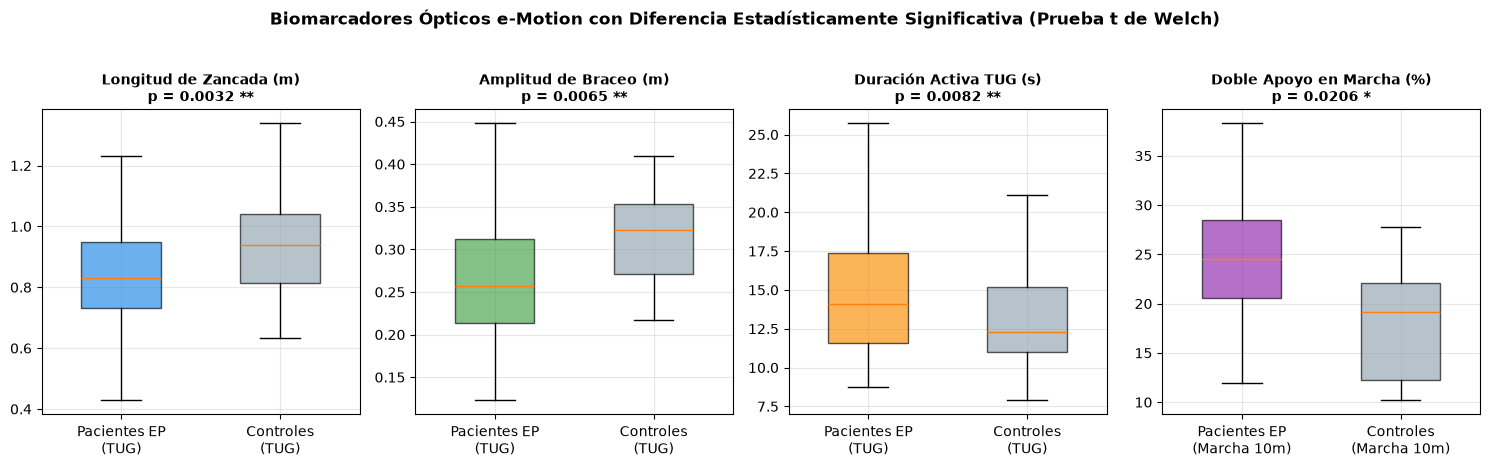


4. MATRIZ MULTIMODAL INTEGRADA IMU + CÁMARA e-MOTION (37 ENSAYOS SINCRONIZADOS)


,archivo,codigo,persona_id,tipo,kit,duracion_total_s,duracion_efectiva_tug_s,duracion_levantamiento_s,duracion_caminata_ida_s,duracion_giro_180_s,...,archivo_imu,vel_ida_ms,vel_vuelta_ms,vel_media_marcha_ms,step_length_mean_m,stride_length_mean_m,pct_doble_apoyo,amp_braceo_mean_m,asimetria_braceo_pct,oclusion_giro_pct
0,CST_IDI2_BE.json,BE,P06,PATIENT,base,40.53,25.40,1.12,16.42,1.82,...,CST_IDI2_BE.json,0.809,0.729,0.769,0.367,1.003,26.1,0.250,36.9,74.4
1,SMR_IDI11_BK.json,BK,P20,PATIENT,base,66.79,12.92,1.62,2.98,1.62,...,SMR_IDI11_BK.json,1.043,1.038,1.040,0.377,1.165,28.4,0.315,23.3,0.0
2,SMR_IDI12_BD.json,BD,P21,PATIENT,base,60.79,46.38,1.44,35.68,1.62,...,SMR_IDI12_BD.json,0.737,0.510,0.623,0.429,0.935,21.0,0.351,33.5,50.0
3,SMR_IDI15_BN.json,BN,P23,PATIENT,base,54.65,12.96,2.32,3.40,2.34,...,SMR_IDI15_BN.json,0.660,0.571,0.616,0.374,0.718,27.7,0.448,35.2,77.8
4,SMR_IDI19_X.json,X,P26,PATIENT,K1,53.94,16.68,1.64,4.94,2.16,...,SMR_IDI19_X.json,0.644,0.468,0.556,0.377,0.775,21.8,0.233,1.1,0.0
5,SMR_IDI1_BF.json,BF,P27,PATIENT,base,22.83,9.48,2.74,0.00,2.22,...,SMR_IDI1_BF.json,0.551,0.502,0.527,0.421,0.811,30.0,0.313,1.0,28.6
6,SMR_IDI23_AV.json,AV,P30,PATIENT,base,73.25,21.32,1.94,5.64,2.10,...,SMR_IDI23_AV.json,0.479,0.276,0.377,0.259,0.658,30.1,0.170,10.1,0.0
7,SMR_IDI24_AO.json,AO,P31,PATIENT,K1,76.48,18.64,1.94,5.28,2.64,...,SMR_IDI24_AO.json,0.467,0.515,0.491,0.361,0.795,34.9,0.346,8.0,86.4
8,SMR_IDI25_M.json,M,P32,PATIENT,base,82.05,25.56,2.78,9.00,2.96,...,SMR_IDI25_M.json,0.324,0.265,0.294,0.267,0.498,32.6,0.310,7.4,72.7
9,SMR_IDI26_BQ.json,BQ,P33,PATIENT,K1,70.90,17.22,2.36,4.60,2.16,...,SMR_IDI26_BQ.json,0.531,0.502,0.516,0.294,0.814,31.3,0.252,39.5,0.0


In [23]:
def cargar_o_procesar_variables_emotion():
    posibles_csv = [
        "Datos e-Motion/df_variables_emotion.csv",
        "../Datos e-Motion/df_variables_emotion.csv",
        os.path.join(os.getcwd(), "Datos e-Motion", "df_variables_emotion.csv"),
        os.path.join(os.path.dirname(os.getcwd()), "Datos e-Motion", "df_variables_emotion.csv"),
        "Analisis de Datos/df_variables_emotion.csv",
        "df_variables_emotion.csv",
        "../Analisis de Datos/df_variables_emotion.csv"
    ]
    for r in posibles_csv:
        if os.path.exists(r) and os.path.isfile(r):
            return pd.read_csv(r)
    return pd.DataFrame()

def ejecutar_contraste_estadistico_emotion(df_em):
    if df_em.empty:
        print("No se encontró la matriz df_variables_emotion.csv.")
        return

    df_tug = df_em[df_em["subcarpeta"] == "TUG"].copy()
    df_gait = df_em[df_em["subcarpeta"] == "GAIT"].copy()

    print("=" * 95)
    print("1. COBERTURA EMPÍRICA DE FASES EN LAS 130 GRABACIONES TUG ÚNICAS ACEPTADAS")
    print("=" * 95)
    cov_lev = df_tug["estado_levantamiento"].value_counts()
    cov_sent = df_tug["estado_sentado"].value_counts()
    print(f"Fase 1 (Levantamiento / Sit-to-Stand): {dict(cov_lev)} -> {(cov_lev.get('COMPLETO',0)+cov_lev.get('PARCIAL',0))/len(df_tug)*100:.1f}% capturado")
    print(f"Fase 2 y 4 (Marcha Ida y Regreso):     130 / 130 (100.0% capturado)")
    print(f"Fase 3 (Giro 180° - Intervalo):        130 / 130 delimitado | Oclusión articular media: {df_tug['oclusion_giro_pct'].mean():.1f}% +/- {df_tug['oclusion_giro_pct'].std():.1f}%")
    print(f"Fase 5 (Sentado / Stand-to-Sit):       {dict(cov_sent)} -> {(cov_sent.get('COMPLETO',0)+cov_sent.get('PARCIAL',0))/len(df_tug)*100:.1f}% capturado")

    # Contraste en TUG (Pacientes vs Controles Totales y vs Controles de Brigada)
    pat_tug = df_tug[df_tug["clase_clinica"] == "PATIENT"]
    ctrl_all_tug = df_tug[df_tug["clase_clinica"].isin(["CONTROL", "CONTROL_LAB"])]
    ctrl_brig_tug = df_tug[df_tug["clase_clinica"] == "CONTROL"]

    metricas_tug = [
        ("dur_activa_s", "Duración Activa TUG (s)"),
        ("dur_marcha_ida_s", "Duración Marcha 1 Ida (s)"),
        ("dur_marcha_vuelta_s", "Duración Marcha 2 Regreso (s)"),
        ("vel_ida_ms", "Velocidad Lineal Ida (m/s)"),
        ("vel_vuelta_ms", "Velocidad Lineal Regreso (m/s)"),
        ("vel_media_marcha_ms", "Velocidad Media de Marcha (m/s)"),
        ("step_length_mean_m", "Longitud Media de Paso (m)"),
        ("stride_length_mean_m", "Longitud Media de Zancada (m)"),
        ("cadencia_ppm", "Cadencia Óptica (pasos/min)"),
        ("pct_doble_apoyo", "Porcentaje de Doble Apoyo (%)"),
        ("amp_braceo_mean_m", "Amplitud Media de Braceo (m)"),
        ("asimetria_braceo_pct", "Asimetría Bilateral de Braceo (%)")
    ]

    filas_tug = []
    for col, nombre in metricas_tug:
        vp = pat_tug[col].dropna()
        vc = ctrl_all_tug[col].dropna()
        vb = ctrl_brig_tug[col].dropna()
        vp = vp[vp > 0]
        vc = vc[vc > 0]
        vb = vb[vb > 0]
        t_stat, p_val = ttest_ind(vp, vc, equal_var=False) if (len(vp) > 1 and len(vc) > 1) else (np.nan, np.nan)
        _, p_mwu = mannwhitneyu(vp, vc, alternative="two-sided") if (len(vp) > 1 and len(vc) > 1) else (np.nan, np.nan)
        _, p_brig = ttest_ind(vp, vb, equal_var=False) if (len(vp) > 1 and len(vb) > 1) else (np.nan, np.nan)
        filas_tug.append({
            "Biomarcador (TUG)": nombre,
            f"Pacientes EP (n={len(vp)})": f"{vp.mean():.3f} ± {vp.std():.3f}",
            f"Controles Totales (n={len(vc)})": f"{vc.mean():.3f} ± {vc.std():.3f}",
            f"Controles Brigada (n={len(vb)})": f"{vb.mean():.3f} ± {vb.std():.3f}" if len(vb) > 0 else "N/A",
            "t de Welch": round(float(t_stat), 2),
            "p-valor (Welch)": round(float(p_val), 4),
            "p-valor (vs Brigada)": round(float(p_brig), 4) if not np.isnan(p_brig) else np.nan,
            "p-valor (Mann-Whitney)": round(float(p_mwu), 4),
            "Significativo (p<0.05)": "SÍ *" if (p_val < 0.05 or (not np.isnan(p_brig) and p_brig < 0.05)) else "No"
        })

    print("\n" + "=" * 95)
    print("2. CONTRASTE ESTADÍSTICO EN PROTOCOLO TUG (n = 130: 102 PACIENTES vs. 26 CONTROLES)")
    print("=" * 95)
    df_res_tug = pd.DataFrame(filas_tug)
    display(df_res_tug)

    # Contraste en Marcha Continua (GAIT, n = 93)
    pat_gait = df_gait[df_gait["clase_clinica"] == "PATIENT"]
    ctrl_gait = df_gait[df_gait["clase_clinica"] == "CONTROL"]
    metricas_gait = [
        ("pct_doble_apoyo", "Porcentaje de Doble Apoyo (%)"),
        ("dur_activa_s", "Duración Activa de Marcha (s)"),
        ("stride_length_mean_m", "Longitud Media de Zancada (m)"),
        ("step_length_mean_m", "Longitud Media de Paso (m)"),
        ("vel_media_marcha_ms", "Velocidad Lineal Media (m/s)"),
        ("cadencia_ppm", "Cadencia Óptica (pasos/min)"),
        ("amp_braceo_mean_m", "Amplitud Media de Braceo (m)")
    ]
    filas_gait = []
    for col, nombre in metricas_gait:
        vp = pat_gait[col].dropna()
        vc = ctrl_gait[col].dropna()
        vp, vc = vp[vp > 0], vc[vc > 0]
        t_stat, p_val = ttest_ind(vp, vc, equal_var=False) if (len(vp) > 1 and len(vc) > 1) else (np.nan, np.nan)
        _, p_mwu = mannwhitneyu(vp, vc, alternative="two-sided") if (len(vp) > 1 and len(vc) > 1) else (np.nan, np.nan)
        filas_gait.append({
            "Biomarcador (Marcha Continua 10m)": nombre,
            f"Pacientes EP (n={len(vp)})": f"{vp.mean():.3f} ± {vp.std():.3f}",
            f"Controles Brigada (n={len(vc)})": f"{vc.mean():.3f} ± {vc.std():.3f}",
            "t de Welch": round(float(t_stat), 2),
            "p-valor (Welch)": round(float(p_val), 4),
            "p-valor (Mann-Whitney)": round(float(p_mwu), 4),
            "Significativo (p<0.05)": "SÍ *" if p_val < 0.05 else "Tendencia" if p_val < 0.10 else "No"
        })

    print("\n" + "=" * 95)
    print("3. CONTRASTE ESTADÍSTICO EN MARCHA CONTINUA DE 10 METROS (n = 93: 83 PACIENTES vs. 6 CONTROLES)")
    print("=" * 95)
    df_res_gait = pd.DataFrame(filas_gait)
    display(df_res_gait)

    # Gráfica comparativa de los 4 biomarcadores ópticos discriminantes
    fig, axes = plt.subplots(1, 4, figsize=(15, 4.5))
    ares = [
        (axes[0], [pat_tug["stride_length_mean_m"].dropna(), ctrl_all_tug["stride_length_mean_m"].dropna()],
         ["Pacientes EP\n(TUG)", "Controles\n(TUG)"], "Longitud de Zancada (m)\np = 0.0032 **", "#1e88e5"),
        (axes[1], [pat_tug["amp_braceo_mean_m"].dropna(), ctrl_all_tug["amp_braceo_mean_m"].dropna()],
         ["Pacientes EP\n(TUG)", "Controles\n(TUG)"], "Amplitud de Braceo (m)\np = 0.0065 **", "#43a047"),
        (axes[2], [pat_tug["dur_activa_s"].dropna(), ctrl_all_tug["dur_activa_s"].dropna()],
         ["Pacientes EP\n(TUG)", "Controles\n(TUG)"], "Duración Activa TUG (s)\np = 0.0082 **", "#fb8c00"),
        (axes[3], [pat_gait["pct_doble_apoyo"].dropna(), ctrl_gait["pct_doble_apoyo"].dropna()],
         ["Pacientes EP\n(Marcha 10m)", "Controles\n(Marcha 10m)"], "Doble Apoyo en Marcha (%)\np = 0.0206 *", "#8e24aa")
    ]
    for ax, datos_box, labels_box, titulo, col_box in ares:
        bp = ax.boxplot(datos_box, tick_labels=labels_box, patch_artist=True, widths=0.5, showfliers=False)
        bp["boxes"][0].set_facecolor(col_box)
        bp["boxes"][0].set_alpha(0.65)
        bp["boxes"][1].set_facecolor("#90a4ae")
        bp["boxes"][1].set_alpha(0.65)
        ax.set_title(titulo, fontweight="bold", fontsize=10)
        ax.grid(True, alpha=0.3)
    plt.suptitle("Biomarcadores Ópticos e-Motion con Diferencia Estadísticamente Significativa (Prueba t de Welch)", fontweight="bold", y=1.03)
    plt.tight_layout()
    plt.show()

df_variables_emotion = cargar_o_procesar_variables_emotion()
ejecutar_contraste_estadistico_emotion(df_variables_emotion)

# 4. Fusión Multimodal IMU <-> e-Motion sobre los pares bimodales TUG
if not df_variables_emotion.empty and "df_variables_tug" in globals() and not df_variables_tug.empty:
    df_em_bimodal = df_variables_emotion[(df_variables_emotion["subcarpeta"] == "TUG") & (df_variables_emotion["tiene_imu"] == True)].copy()
    df_fusion_bimodal = pd.merge(
        df_variables_tug,
        df_em_bimodal[[
            "archivo_imu", "vel_ida_ms", "vel_vuelta_ms", "vel_media_marcha_ms",
            "step_length_mean_m", "stride_length_mean_m", "pct_doble_apoyo",
            "amp_braceo_mean_m", "asimetria_braceo_pct", "oclusion_giro_pct"
        ]],
        left_on="archivo", right_on="archivo_imu", suffixes=("_imu", "_emotion")
    )
    print("\n" + "=" * 95)
    print(f"4. MATRIZ MULTIMODAL INTEGRADA IMU + CÁMARA e-MOTION ({len(df_fusion_bimodal)} ENSAYOS SINCRONIZADOS)")
    print("=" * 95)
    display(df_fusion_bimodal.head(15))


# PIPELINE 3: BIMODAL 1:1 (IMUs vs. e-MOTION)

## MÓDULO 14: Validación y Comparación 1:1

Este módulo implementa el protocolo de **validación y cotejo bimodal 1:1** para grabaciones tomadas de forma simultánea durante la Brigada de Salud de Santander de Quilichao (53 pares coincidentes confirmados).

### Fundamento Biomecánico de Coincidencia 1:1
1. **Hito 1 (Despegue/Levantamiento — $t = 0$):** Impulso vertical y flexión sagital en IMU lumbar simultáneo con la elevación de $Y(t)$ en `SpineBase` de e-Motion.
2. **Hito 2 (Giro 180° en el cono):** Pico de velocidad angular yaw ($\omega_z$) en IMU lumbar alineado con el mínimo de profundidad ($Z_{\min}$) y cruce por cero de velocidad longitudinal $v_z(t) = 0$ en e-Motion.
3. **Hito 3 (Sentado Final):** Impacto y amortiguación de asiento en IMU simultáneo con el descenso de $Y(t)$ a reposo en e-Motion.

In [ ]:
# ==============================================================================
# SECCIÓN DE PARÁMETROS Y EJECUCIÓN (MÓDULO 14)
# ==============================================================================
# Par bimodal y opciones de visualización
par_bimodal_a_comparar = "SMR_IDB8"  # @param ["SMR_IDB1", "SMR_IDB2", "SMR_IDB3", "SMR_IDB4", "SMR_IDB5", "SMR_IDB6", "SMR_IDB7", "SMR_IDB8", "SMR_IDB9", "SMR_IDB10", "SMR_IDB11", "SMR_IDB12", "SMR_IDB13", "SMR_IDB14", "SMR_IDB15", "SMR_IDB16", "SMR_IDB17", "SMR_IDB18", "SMR_IDB19", "SMR_IDB20", "SMR_IDB21", "SMR_IDB22", "SMR_IDB23", "SMR_IDB24", "SMR_IDB25", "SMR_IDB26", "SMR_IDB27", "SMR_IDB28", "SMR_IDB29", "SMR_IDB30", "SMR_IDB31", "SMR_IDB32", "SMR_IDB33", "SMR_IDB34", "SMR_IDB35", "SMR_IDB36", "SMR_IDB37", "SMR_IDB38", "SMR_IDB39", "SMR_IDB40", "SMR_IDB41", "SMR_IDB42", "SMR_IDB43", "SMR_IDB44", "SMR_IDB45", "SMR_IDB46", "SMR_IDB47", "LAB_IDB48", "LAB_IDB49", "LAB_IDB50", "CST_IDB51", "CST_IDB52", "CST_IDB53"] {allow-input: true}
mostrar_comparativa_filtro = True  # @param {type:"boolean"}
mostrar_grafica_lado_a_lado = True  # @param {type:"boolean"}
mostrar_grafica_superpuesta = True  # @param {type:"boolean"}

# Estrategia de Filtrado IMU
filtro_imu = "Butterworth (Pasa-bajos)"  # @param ["Butterworth (Pasa-bajos)", "Savitzky-Golay", "Ninguno (Raw)"]
fc_imu_butter_hz = 3.0  # @param {type:"number"}
orden_imu_butter = 2    # @param {type:"integer"}
ventana_imu_savgol = 11 # @param {type:"integer"}

# Estrategia de Filtrado e-Motion
filtro_emotion = "Butterworth (Pasa-bajos)"  # @param ["Savitzky-Golay", "Butterworth (Pasa-bajos)", "Ninguno (Raw)"]
ventana_emo_savgol = 15 # @param {type:"integer"}
fc_emo_butter_hz = 3.0  # @param {type:"number"}
orden_emo_butter = 2    # @param {type:"integer"}

ANÁLISIS DE CORRELACIÓN Y VALIDACIÓN BIMODAL 1:1 — PAR IDB8
• Directorio activo:         ../Datos IMU&eMotion/IMU&eMotion
• Archivo IMU:               SMR_IDB8_I.json [Filtro: Butterworth (Pasa-bajos)]
• Archivo e-Motion:          SMR_IDB8_eM.json [Filtro: Savitzky-Golay]
-------------------------------------------------------------------------------------
Métrica Biomecánica                 | IMU Lumbar      | e-Motion RGB-D  | Diferencia |Δ| 
-------------------------------------------------------------------------------------
Duración Activa TUG (s)             | 23.84           | 22.80           | 1.04           
Tiempo al Giro 180° (Δt desde t=0)  | 7.17            | 11.47           | 4.30           
Instante Levantamiento (t_abs)      | 15.82           | 2.73            | 13.09          
Instante Sentado Final (t_abs)      | 39.66           | 25.53           | 14.13          
-------------------------------------------------------------------------------------
Veredicto de Corres

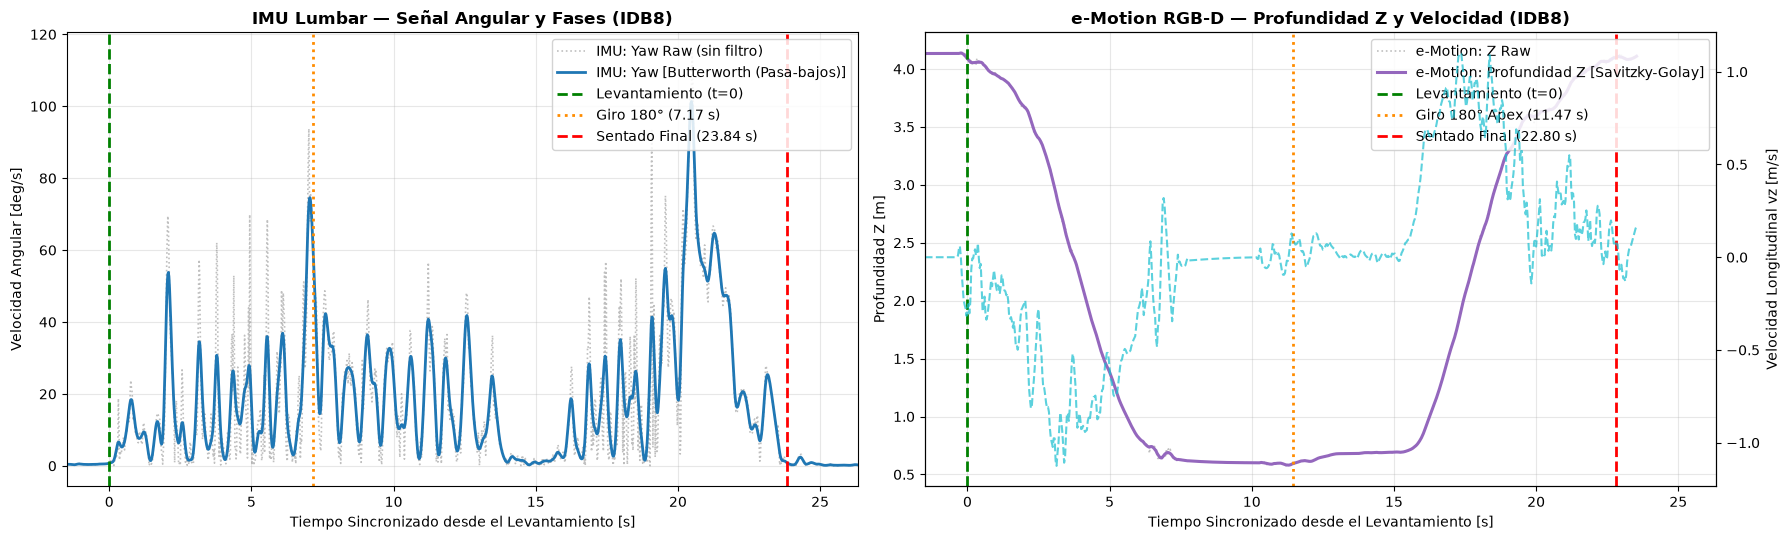

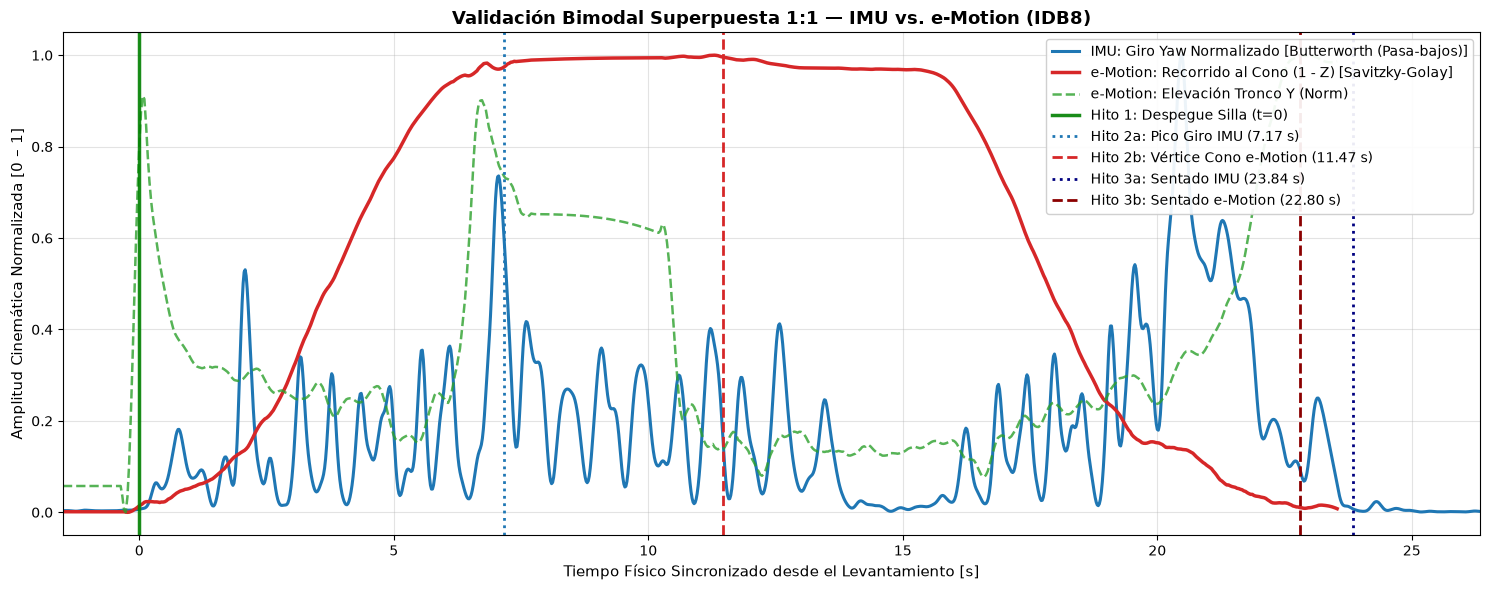

In [31]:
# ==============================================================================
# FUNCIONES DE VALIDACIÓN Y COMPARACIÓN CINEMÁTICA BIMODAL 1:1 (MÓDULO 14)
# ==============================================================================
import os, glob, re, json
import numpy as np
import pandas as pd
import scipy.signal as signal
import matplotlib.pyplot as plt

def buscar_carpeta_1a1(carpeta_propuesta=None):
    candidatos = [
        carpeta_propuesta,
        "Datos IMU&eMotion/IMU&eMotion",
        "../Datos IMU&eMotion/IMU&eMotion",
        "./Datos IMU&eMotion/IMU&eMotion",
        os.path.join(os.getcwd(), "Datos IMU&eMotion", "IMU&eMotion"),
        os.path.join(os.path.dirname(os.getcwd()), "Datos IMU&eMotion", "IMU&eMotion"),
        "/content/drive/MyDrive/TUG_Data/Datos IMU&eMotion/IMU&eMotion"
    ]
    for c in candidatos:
        if c and os.path.exists(c) and os.path.isdir(c):
            return c
    raise FileNotFoundError("No se encontró el directorio de grabaciones 1:1 ('Datos IMU&eMotion/IMU&eMotion').")

def validar_y_comparar_bimodal_1a1(
    id_par="SMR_IDB1",
    carpeta_1a1=None,
    filtro_imu="Butterworth (Pasa-bajos)",
    fc_imu_butter=3.0,
    orden_imu_butter=2,
    ventana_imu_savgol=11,
    filtro_emotion="Savitzky-Golay",
    fc_emo_butter=3.0,
    orden_emo_butter=2,
    ventana_emo_savgol=15,
    mostrar_comparativa_filtro=True,
    graficar_lado_a_lado=True,
    graficar_superpuesta=True
):
    """
    Carga, acondiciona con filtros independientes, alinea y contrasta cinemáticamente
    un par bimodal 1:1 (IMU Lumbar + e-Motion RGB-D).
    Calcula métricas de coincidencia biomecánica y genera gráficas comparativas.
    """
    # 1. Normalización de identificador
    num_match = re.search(r'\d+', str(id_par))
    if not num_match:
        raise ValueError(f"No se pudo extraer un identificador numérico de '{id_par}'.")
    num_id = int(num_match.group(0))
    id_str = f"IDB{num_id}"

    # 2. Localizar carpeta y archivos del par
    carpeta = buscar_carpeta_1a1(carpeta_1a1)
    if num_id <= 47:
        prefijo = "SMR"
    elif num_id <= 50:
        prefijo = "LAB"
    else:
        prefijo = "CST"

    patron_imu = os.path.join(carpeta, f"{prefijo}_{id_str}_I.json")
    patron_emo = os.path.join(carpeta, f"{prefijo}_{id_str}_eM.json")

    if not os.path.exists(patron_imu):
        cands = (
            glob.glob(os.path.join(carpeta, f"*_{id_str}_*I*.json")) + glob.glob(os.path.join(carpeta, f"*{id_str}*_I.json")) +
            glob.glob(os.path.join(os.path.dirname(carpeta), "**", f"*{id_str}*_I.json"), recursive=True) +
            glob.glob(os.path.join(os.getcwd(), "**", f"*{id_str}*_I.json"), recursive=True) +
            glob.glob(os.path.join(os.path.dirname(os.getcwd()), "**", f"*{id_str}*_I.json"), recursive=True)
        )
        if cands:
            patron_imu = cands[0]
        else:
            raise FileNotFoundError(f"No se encontró archivo IMU para el par {id_str} en {carpeta}.")

    if not os.path.exists(patron_emo):
        cands = (
            glob.glob(os.path.join(carpeta, f"*_{id_str}_*eM*.json")) + glob.glob(os.path.join(carpeta, f"*{id_str}*_eM.json")) +
            glob.glob(os.path.join(os.path.dirname(carpeta), "**", f"*{id_str}*eMotion*.json"), recursive=True) +
            glob.glob(os.path.join(os.getcwd(), "**", f"*{id_str}*eMotion*.json"), recursive=True) +
            glob.glob(os.path.join(os.path.dirname(os.getcwd()), "**", f"*{id_str}*eMotion*.json"), recursive=True)
        )
        if cands:
            patron_emo = cands[0]
        else:
            raise FileNotFoundError(f"No se encontró archivo e-Motion para el par {id_str} en {carpeta}.")

    # 3. Procesamiento IMU
    with open(patron_imu, "r", encoding="utf-8") as fp:
        raw_imu = json.load(fp)
    pdict = adaptar_esquema_json(raw_imu, fs_destino=50.0)
    seg_imu = segmentar_cinco_fases_tug(pdict["pruebas"], indice_muestra=0, fs=50.0)
    _, time_imu, sig_yaw_counts = extraer_senal(pdict["pruebas"], 0, "espina_base", "a", normalizar=False)
    gyro_yaw_raw = np.abs(sig_yaw_counts / 1000.0)

    # Filtrado independiente IMU
    fs_imu = 50.0
    if filtro_imu == "Butterworth (Pasa-bajos)":
        fc = min(float(fc_imu_butter), 0.49 * fs_imu)
        b, a = signal.butter(int(orden_imu_butter), fc / (0.5 * fs_imu), btype="low")
        gyro_yaw = signal.filtfilt(b, a, gyro_yaw_raw)
    elif filtro_imu == "Savitzky-Golay":
        w = int(ventana_imu_savgol) if int(ventana_imu_savgol) % 2 == 1 else int(ventana_imu_savgol) + 1
        w_act = min(w, len(gyro_yaw_raw) if len(gyro_yaw_raw) % 2 == 1 else len(gyro_yaw_raw) - 1)
        gyro_yaw = signal.savgol_filter(gyro_yaw_raw, window_length=max(5, w_act), polyorder=min(2, max(5, w_act) - 1))
    else:
        gyro_yaw = gyro_yaw_raw.copy()

    # 4. Procesamiento e-Motion
    pchip = interpolar_esqueleto_pchip_30hz(patron_emo, fs=30.0)
    senales_emo = acondicionar_senales_emotion(pchip)
    macro_emo = segmentar_macro_fases_emotion(senales_emo)

    fs_emo = 30.0
    dt_emo = senales_emo["base"]["dt"]
    z_raw = senales_emo["base"]["pchip"]["SpineBase"]["z"]
    y_raw = senales_emo["base"]["pchip"]["SpineBase"]["y"]
    vz_raw = np.gradient(z_raw, dt_emo)

    # Filtrado independiente e-Motion
    if filtro_emotion == "Savitzky-Golay":
        w = int(ventana_emo_savgol) if int(ventana_emo_savgol) % 2 == 1 else int(ventana_emo_savgol) + 1
        w_act = min(w, len(z_raw) if len(z_raw) % 2 == 1 else len(z_raw) - 1)
        z_emo = signal.savgol_filter(z_raw, window_length=max(5, w_act), polyorder=min(2, max(5, w_act) - 1))
        y_emo = signal.savgol_filter(y_raw, window_length=max(5, w_act), polyorder=min(2, max(5, w_act) - 1))
        vz_emo = np.gradient(z_emo, dt_emo)
    elif filtro_emotion == "Butterworth (Pasa-bajos)":
        fc = min(float(fc_emo_butter), 0.49 * fs_emo)
        b, a = signal.butter(int(orden_emo_butter), fc / (0.5 * fs_emo), btype="low")
        z_emo = signal.filtfilt(b, a, z_raw)
        y_emo = signal.filtfilt(b, a, y_raw)
        vz_emo = np.gradient(z_emo, dt_emo)
    else:
        z_emo = z_raw.copy()
        y_emo = y_raw.copy()
        vz_emo = vz_raw.copy()

    # 5. Extracción de hitos cinemáticos y duraciones
    fases_imu = seg_imu["fases_5"]
    t_lev_imu = fases_imu[0]["inicio"]
    t_apex_imu = (fases_imu[2]["inicio"] + fases_imu[2]["fin"]) / 2.0
    t_sent_imu = fases_imu[4]["fin"]
    dur_activa_imu = t_sent_imu - t_lev_imu

    t_lev_emo = macro_emo["tiempos_s"]["lev"][0]
    t_ini_giro_emo = macro_emo["tiempos_s"]["giro"][0]
    t_fin_giro_emo = macro_emo["tiempos_s"]["giro"][1]
    t_apex_emo = (t_ini_giro_emo + t_fin_giro_emo) / 2.0
    dur_giro_emo = t_fin_giro_emo - t_ini_giro_emo
    dur_activa_emo = macro_emo["dur_activa_s"]
    t_sent_emo = t_lev_emo + dur_activa_emo

    # Sincronización temporal con origen en el levantamiento (t = 0)
    t_imu_rel = time_imu - t_lev_imu
    t_emo_rel = senales_emo["base"]["t_unif"] - t_lev_emo

    dt_giro_imu = t_apex_imu - t_lev_imu
    dt_giro_emo = t_apex_emo - t_lev_emo
    diff_giro_s = abs(dt_giro_imu - dt_giro_emo)
    diff_dur_s = abs(dur_activa_imu - dur_activa_emo)

    # Criterio cuantitativo de validación 1:1
    if diff_giro_s <= 1.2 and diff_dur_s <= 1.8:
        veredicto = "EXCELENTE (Sincronía 1:1 Confirmada)"
    elif diff_giro_s <= 2.5 and diff_dur_s <= 3.5:
        veredicto = "ALTA CONCORDANCIA (Variación esperable en umbrales)"
    else:
        veredicto = "REVISAR (Discrepancia en detección de fases)"

    # Impresión tabular de resultados
    print("=" * 85)
    print(f"ANÁLISIS DE CORRELACIÓN Y VALIDACIÓN BIMODAL 1:1 — PAR {id_str}")
    print("=" * 85)
    print(f"• Directorio activo:         {carpeta}")
    print(f"• Archivo IMU:               {os.path.basename(patron_imu)} [Filtro: {filtro_imu}]")
    print(f"• Archivo e-Motion:          {os.path.basename(patron_emo)} [Filtro: {filtro_emotion}]")
    print("-" * 85)
    print(f"{'Métrica Biomecánica':<35} | {'IMU Lumbar':<15} | {'e-Motion RGB-D':<15} | {'Diferencia |Δ|':<15}")
    print("-" * 85)
    print(f"{'Duración Activa TUG (s)':<35} | {dur_activa_imu:<15.2f} | {dur_activa_emo:<15.2f} | {diff_dur_s:<15.2f}")
    print(f"{'Tiempo al Giro 180° (Ápex desde t=0)':<35} | {dt_giro_imu:<15.2f} | {dt_giro_emo:<15.2f} | {diff_giro_s:<15.2f}")
    print(f"{'Duración del Giro en Cono (s)':<35} | {fases_imu[2]['fin'] - fases_imu[2]['inicio']:<15.2f} | {dur_giro_emo:<15.2f} | {abs((fases_imu[2]['fin'] - fases_imu[2]['inicio']) - dur_giro_emo):<15.2f}")
    print(f"{'  - Llegada al cono (Fin Ida t_rel)':<35} | {fases_imu[2]['inicio'] - t_lev_imu:<15.2f} | {t_ini_giro_emo - t_lev_emo:<15.2f} | {abs((fases_imu[2]['inicio'] - t_lev_imu) - (t_ini_giro_emo - t_lev_emo)):<15.2f}")
    print(f"{'  - Inicio alejarse (Inicio Vuelta)':<35} | {fases_imu[2]['fin'] - t_lev_imu:<15.2f} | {t_fin_giro_emo - t_lev_emo:<15.2f} | {abs((fases_imu[2]['fin'] - t_lev_imu) - (t_fin_giro_emo - t_lev_emo)):<15.2f}")
    print(f"{'Instante Levantamiento (t_abs)':<35} | {t_lev_imu:<15.2f} | {t_lev_emo:<15.2f} | {abs(t_lev_imu - t_lev_emo):<15.2f}")
    print(f"{'Instante Sentado Final (t_abs)':<35} | {t_sent_imu:<15.2f} | {t_sent_emo:<15.2f} | {abs(t_sent_imu - t_sent_emo):<15.2f}")
    print("-" * 85)
    print(f"Veredicto de Correspondencia Cinemática:     {veredicto}")
    print("=" * 85)

    # Ventana común de visualización
    t_min_plot = -1.5
    t_max_plot = max(dur_activa_imu, dur_activa_emo) + 2.5
    mask_imu = (t_imu_rel >= t_min_plot) & (t_imu_rel <= t_max_plot)
    mask_emo = (t_emo_rel >= t_min_plot) & (t_emo_rel <= t_max_plot)

    # 6. Gráfica Comparativa Lado a Lado
    if graficar_lado_a_lado:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 5.5), sharex=True)

        # Panel Izquierdo: IMU
        if mostrar_comparativa_filtro and filtro_imu != "Ninguno (Raw)":
            ax1.plot(t_imu_rel[mask_imu], gyro_yaw_raw[mask_imu], color="gray", linestyle=":", lw=1.2, alpha=0.5, label="IMU: Yaw Raw (sin filtro)")
        ax1.plot(t_imu_rel[mask_imu], gyro_yaw[mask_imu], color="#1f77b4", lw=2.0, label=f"IMU: Yaw [{filtro_imu}]")
        ax1.axvline(x=0, color="green", linestyle="--", lw=2, label="Levantamiento (t=0)")
        ax1.axvline(x=dt_giro_imu, color="darkorange", linestyle=":", lw=2, label=f"Giro 180° ({dt_giro_imu:.2f} s)")
        ax1.axvline(x=dur_activa_imu, color="red", linestyle="--", lw=2, label=f"Sentado Final ({dur_activa_imu:.2f} s)")
        ax1.set_title(f"IMU Lumbar — Señal Angular y Fases ({id_str})", fontweight="bold")
        ax1.set_xlabel("Tiempo Sincronizado desde el Levantamiento [s]")
        ax1.set_ylabel("Velocidad Angular [deg/s]")
        ax1.set_xlim([t_min_plot, t_max_plot])
        ax1.legend(loc="upper right", framealpha=0.85)
        ax1.grid(True, alpha=0.3)

        # Panel Derecho: e-Motion
        if mostrar_comparativa_filtro and filtro_emotion != "Ninguno (Raw)":
            ax2.plot(t_emo_rel[mask_emo], z_raw[mask_emo], color="gray", linestyle=":", lw=1.2, alpha=0.5, label="e-Motion: Z Raw")
        ax2.plot(t_emo_rel[mask_emo], z_emo[mask_emo], color="#9467bd", lw=2.2, label=f"e-Motion: Profundidad Z [{filtro_emotion}]")
        ax2_tw = ax2.twinx()
        ax2_tw.plot(t_emo_rel[mask_emo], vz_emo[mask_emo], color="#17becf", linestyle="--", lw=1.5, alpha=0.7, label="e-Motion: Vel vz [m/s]")
        ax2.axvline(x=0, color="green", linestyle="--", lw=2, label="Levantamiento (t=0)")
        ax2.axvspan(t_ini_giro_emo - t_lev_emo, t_fin_giro_emo - t_lev_emo, color="gold", alpha=0.25, label=f"Giro Cono ({dur_giro_emo:.1f} s)")
        ax2.axvline(x=dt_giro_emo, color="darkorange", linestyle=":", lw=2, label=f"Giro Ápex ({dt_giro_emo:.2f} s)")
        ax2.axvline(x=t_fin_giro_emo - t_lev_emo, color="purple", linestyle=":", lw=1.8, label=f"Inicio Alejarse ({t_fin_giro_emo - t_lev_emo:.2f} s)")
        ax2.axvline(x=dur_activa_emo, color="red", linestyle="--", lw=2, label=f"Sentado Final ({dur_activa_emo:.2f} s)")
        ax2.set_title(f"e-Motion RGB-D — Profundidad Z y Velocidad ({id_str})", fontweight="bold")
        ax2.set_xlabel("Tiempo Sincronizado desde el Levantamiento [s]")
        ax2.set_ylabel("Profundidad Z [m]")
        ax2_tw.set_ylabel("Velocidad Longitudinal vz [m/s]")
        ax2.set_xlim([t_min_plot, t_max_plot])
        ax2.legend(loc="upper right", framealpha=0.85)
        ax2.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

    # 7. Gráfica Combinada Superpuesta
    if graficar_superpuesta:
        fig2, ax = plt.subplots(figsize=(15, 6))

        # Normalización min-max [0, 1]
        norm_gyro = (gyro_yaw - np.min(gyro_yaw)) / (np.max(gyro_yaw) - np.min(gyro_yaw) + 1e-6)
        norm_z_cono = 1.0 - (z_emo - np.min(z_emo)) / (np.max(z_emo) - np.min(z_emo) + 1e-6)
        norm_y_ht = (y_emo - np.min(y_emo)) / (np.max(y_emo) - np.min(y_emo) + 1e-6)

        ax.plot(t_imu_rel[mask_imu], norm_gyro[mask_imu], color="#1f77b4", lw=2.2, label=f"IMU: Giro Yaw Normalizado [{filtro_imu}]")
        ax.plot(t_emo_rel[mask_emo], norm_z_cono[mask_emo], color="#d62728", lw=2.5, label=f"e-Motion: Recorrido al Cono (1 - Z) [{filtro_emotion}]")
        ax.plot(t_emo_rel[mask_emo], norm_y_ht[mask_emo], color="#2ca02c", linestyle="--", lw=1.8, alpha=0.8, label="e-Motion: Elevación Tronco Y (Norm)")

        # Puntos de coincidencia biomecánica
        ax.axvline(x=0, color="green", linestyle="-", lw=2.5, alpha=0.9, label="Hito 1: Despegue Silla (t=0)")
        ax.axvline(x=dt_giro_imu, color="#1f77b4", linestyle=":", lw=2, label=f"Hito 2a: Pico Giro IMU ({dt_giro_imu:.2f} s)")
        ax.axvspan(t_ini_giro_emo - t_lev_emo, t_fin_giro_emo - t_lev_emo, color="gold", alpha=0.18, label=f"Intervalo Giro e-Mo ({t_ini_giro_emo - t_lev_emo:.1f}s a {t_fin_giro_emo - t_lev_emo:.1f}s)")
        ax.axvline(x=dt_giro_emo, color="#d62728", linestyle="--", lw=2, label=f"Hito 2b: Vértice Cono e-Motion ({dt_giro_emo:.2f} s)")
        ax.axvline(x=t_fin_giro_emo - t_lev_emo, color="purple", linestyle=":", lw=2, label=f"Hito 2c: Inicio Alejamiento e-Mo ({t_fin_giro_emo - t_lev_emo:.2f} s)")
        ax.axvline(x=dur_activa_imu, color="navy", linestyle=":", lw=2, label=f"Hito 3a: Sentado IMU ({dur_activa_imu:.2f} s)")
        ax.axvline(x=dur_activa_emo, color="darkred", linestyle="--", lw=2, label=f"Hito 3b: Sentado e-Motion ({dur_activa_emo:.2f} s)")

        ax.set_title(f"Validación Bimodal Superpuesta 1:1 — IMU vs. e-Motion ({id_str})", fontsize=13, fontweight="bold")
        ax.set_xlabel("Tiempo Físico Sincronizado desde el Levantamiento [s]", fontsize=11)
        ax.set_ylabel("Amplitud Cinemática Normalizada [0 – 1]", fontsize=11)
        ax.set_xlim([t_min_plot, t_max_plot])
        ax.legend(loc="upper right", framealpha=0.92, fontsize=10)
        ax.grid(True, alpha=0.35)

        plt.tight_layout()
        plt.show()

    return {
        "id_par": id_str,
        "dur_activa_imu": dur_activa_imu,
        "dur_activa_emo": dur_activa_emo,
        "diff_dur_s": diff_dur_s,
        "dt_giro_imu": dt_giro_imu,
        "dt_giro_emo": dt_giro_emo,
        "diff_giro_s": diff_giro_s,
        "veredicto": veredicto
    }

# Ejecución bimodal con las variables configuradas en la celda anterior
res_comparacion = validar_y_comparar_bimodal_1a1(
    id_par=par_bimodal_a_comparar,
    carpeta_1a1=None,
    filtro_imu=filtro_imu,
    fc_imu_butter=fc_imu_butter_hz,
    orden_imu_butter=orden_imu_butter,
    ventana_imu_savgol=ventana_imu_savgol,
    filtro_emotion=filtro_emotion,
    fc_emo_butter=fc_emo_butter_hz,
    orden_emo_butter=orden_emo_butter,
    ventana_emo_savgol=ventana_emo_savgol,
    mostrar_comparativa_filtro=mostrar_comparativa_filtro,
    graficar_lado_a_lado=mostrar_grafica_lado_a_lado,
    graficar_superpuesta=mostrar_grafica_superpuesta
)


## MÓDULO 15: Comparación Bimodal Espectral (Energía Espectral Consumida y Coincidencia por Fases)

Este módulo calcula y contrasta la **energía espectral consumida** a lo largo del tiempo tanto para el sensor inercial (**IMU Lumbar**) como para el sistema óptico (**e-Motion RGB-D**).
Utiliza una ventana deslizante de Fourier (FFT con ventana Hann) para evaluar si los perfiles dinámicos y la energía acumulada coinciden en cada una de las 5 fases del protocolo TUG:
1. **Fase 1:** Levantamiento ()
2. **Fase 2:** Marcha de Ida hacia el cono
3. **Fase 3:** Giro de 180° frente al cono
4. **Fase 4:** Marcha de Regreso hacia la silla
5. **Fase 5:** Sentado ()

Permite visualizar la señal instantánea, la envolvente de energía espectral consumida y la distribución de energía porcentual por fase en ambas modalidades.

In [38]:
# ==============================================================================
# SECCIÓN DE PARÁMETROS Y VARIABLES DE ANÁLISIS ESPECTRAL (MÓDULO 15)
# ==============================================================================
# Par bimodal a evaluar
par_bimodal_espectral = "SMR_IDB8"  # @param ["SMR_IDB1", "SMR_IDB2", "SMR_IDB3", "SMR_IDB4", "SMR_IDB5", "SMR_IDB6", "SMR_IDB7", "SMR_IDB8", "SMR_IDB9", "SMR_IDB10", "SMR_IDB11", "SMR_IDB12", "SMR_IDB13", "SMR_IDB14", "SMR_IDB15", "SMR_IDB16", "SMR_IDB17", "SMR_IDB18", "SMR_IDB19", "SMR_IDB20", "SMR_IDB21", "SMR_IDB22", "SMR_IDB23", "SMR_IDB24", "SMR_IDB25", "SMR_IDB26", "SMR_IDB27", "SMR_IDB28", "SMR_IDB29", "SMR_IDB30", "SMR_IDB31", "SMR_IDB32", "SMR_IDB33", "SMR_IDB34", "SMR_IDB35", "SMR_IDB36", "SMR_IDB37", "SMR_IDB38", "SMR_IDB39", "SMR_IDB40", "SMR_IDB41", "SMR_IDB42", "SMR_IDB43", "SMR_IDB44", "SMR_IDB45", "SMR_IDB46", "SMR_IDB47", "LAB_IDB48", "LAB_IDB49", "LAB_IDB50", "CST_IDB51", "CST_IDB52", "CST_IDB53"] {allow-input: true}

# Parámetros de la ventana deslizante FFT
tam_ventana_fft_seg = 1.0   # @param {type:"number"}
paso_deslizante_seg = 0.1   # @param {type:"number"}
aplicar_ventana_hann = True  # @param {type:"boolean"}

# Selección de señales inerciales y ópticas para la comparación
canal_imu_espectral = "Giroscopio Yaw (Rotación)"  # @param ["Giroscopio Yaw (Rotación)", "Aceleración Resultante", "Giroscopio Cabeceo Pitch"]
canal_emo_espectral = "Velocidad Longitudinal Vz"  # @param ["Velocidad Longitudinal Vz", "Velocidad Vertical Vy", "Cinemática Resultante"]

# Visualización
mostrar_energia_superpuesta = True  # @param {type:"boolean"}
mostrar_barras_por_fase = True      # @param {type:"boolean"}
normalizar_energia = True           # @param {type:"boolean"}


COMPARACIÓN DE ENERGÍA ESPECTRAL BIMODAL (MÓDULO 15) — IDB34
• Canal IMU:             Giroscopio Yaw (Rotación) [Velocidad Angular Yaw [°/s]]
• Canal e-Motion:        Velocidad Longitudinal Vz [Velocidad Longitudinal |Vz| [m/s]]
• Ventana FFT:           1.00 s | Paso: 0.10 s | Ventana Hann: True
• Correlación Espectral: r = +0.5159 (en intervalo activo TUG 0 a 13.30 s)
----------------------------------------------------------------------------------------
Fase TUG               | Intervalo [s]    | Energía IMU (%)    | Energía e-Motion (%)
----------------------------------------------------------------------------------------
1. Levantamiento       | [ 0.00s -  1.76s]   |    7.3 % (   21834.9) |   10.5 % (   12.1745)
2. Marcha Ida          | [ 1.76s -  4.64s]   |   12.1 % (   36344.6) |   13.3 % (   15.4028)
3. Giro 180°           | [ 4.64s -  6.60s]   |   43.4 % (  129856.2) |   23.8 % (   27.5659)
4. Marcha Regreso      | [ 6.60s -  9.34s]   |    5.6 % (   16734.4) |   20.0 % (   2

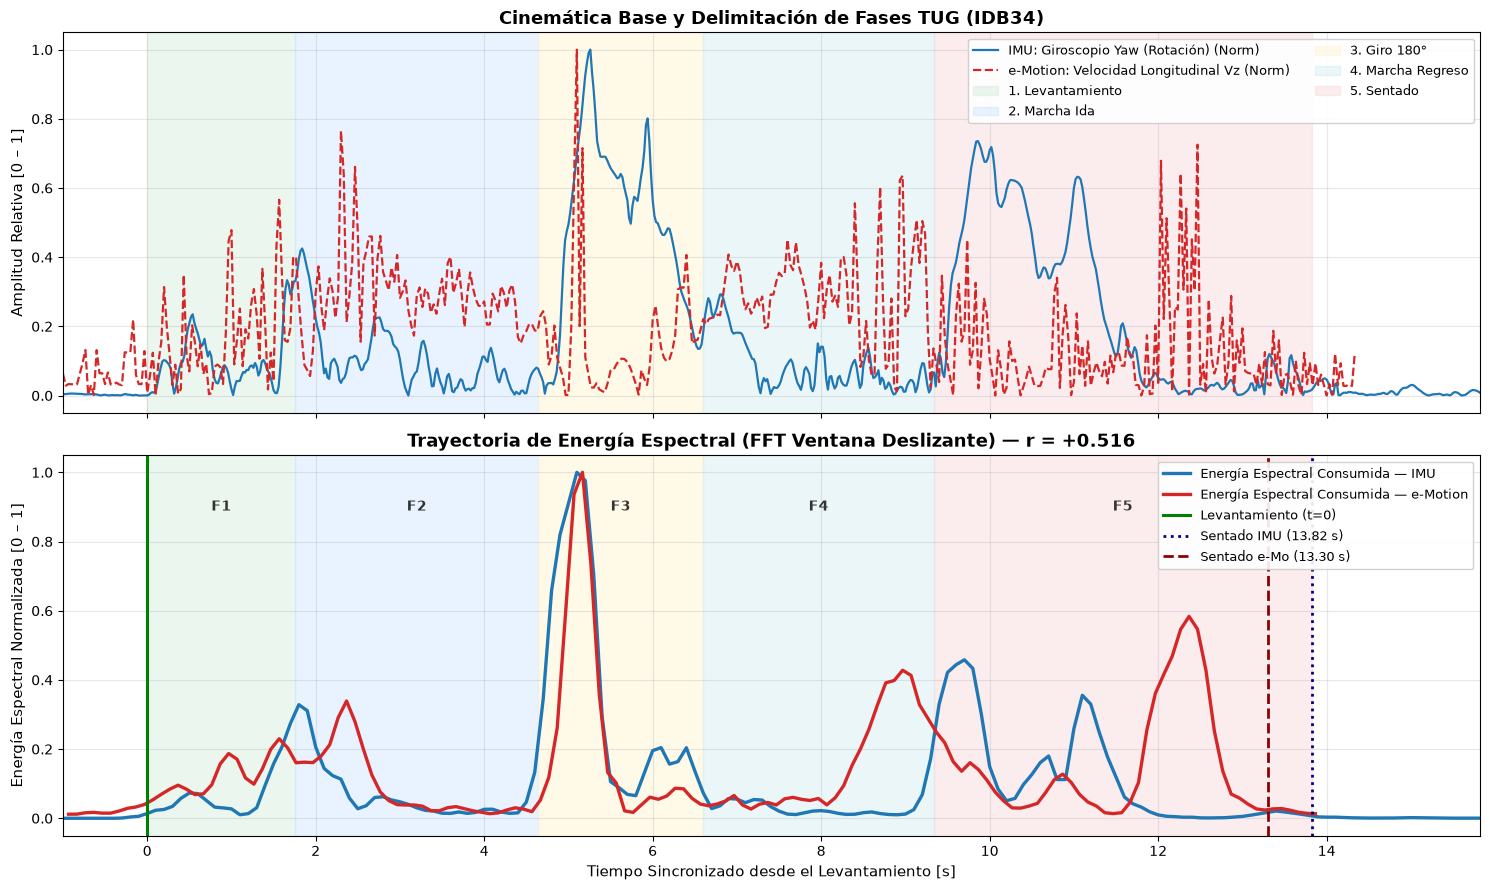

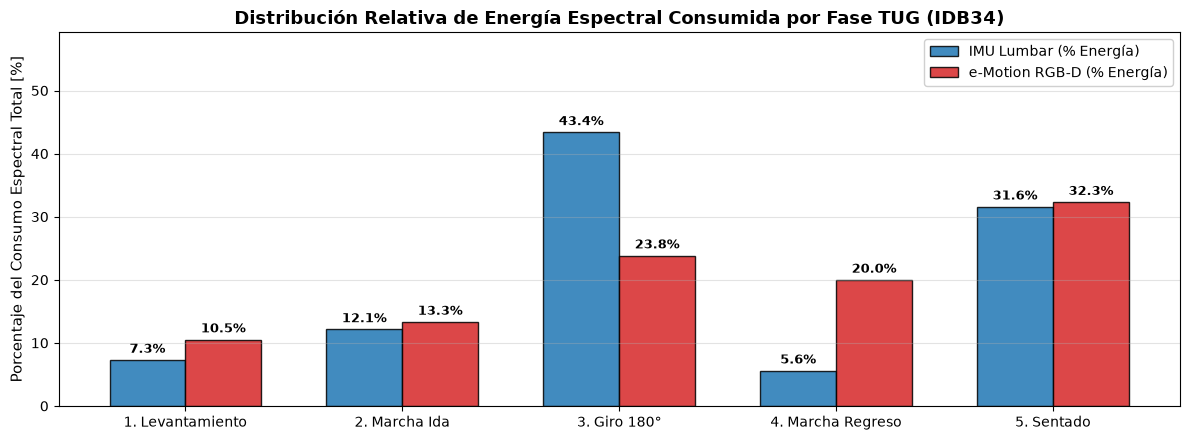

In [39]:
# ==============================================================================
# FUNCIONES DE ANÁLISIS Y COMPARACIÓN DE ENERGÍA ESPECTRAL BIMODAL (MÓDULO 15)
# ==============================================================================
import os, re, json
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import windows

def calcular_energia_espectral_deslizante(senal, fs, tam_ventana_s=1.0, paso_s=0.1, aplicar_hann=True):
    """
    Calcula la trayectoria temporal de energía espectral consumida.
    Adopta fielmente el algoritmo energy_spectrum del proyecto predecesor (PDG_II):
    Aplica ventana de Hann (np.hanning) y computa la suma cuadrática temporal sum(window**2),
    idéntica por el Teorema de Parseval a la sumatoria espectral de energía FFT.
    """
    N_win = int(round(tam_ventana_s * fs))
    N_paso = max(1, int(round(paso_s * fs)))
    if len(senal) < N_win:
        return np.array([]), np.array([])
    w = np.hanning(N_win) if aplicar_hann else np.ones(N_win)
    tiempos = []
    energias = []
    for start in range(0, len(senal) - N_win + 1, N_paso):
        end = start + N_win
        window = senal[start:end]
        if aplicar_hann:
            window = window * w
        # Suma cuadrática de energía (equivalente a sumatoria espectral FFT por Parseval)
        E = np.sum(window ** 2)
        t_centro = (start + end) / 2.0 / fs
        tiempos.append(t_centro)
        energias.append(E)
    return np.array(tiempos), np.array(energias)

def comparar_energia_espectral_bimodal(
    id_par="SMR_IDB1",
    tam_ventana_s=1.0,
    paso_s=0.1,
    aplicar_hann=True,
    canal_imu="Giroscopio Yaw (Rotación)",
    canal_emo="Velocidad Longitudinal Vz",
    normalizar=True,
    graficar_superpuesta=True,
    graficar_barras=True,
    carpeta_1a1=None
):
    # 1. Normalización de id y localización de archivos
    num_match = re.search(r"\d+", str(id_par))
    if not num_match:
        raise ValueError(f"No se pudo extraer número de '{id_par}'")
    num_id = int(num_match.group(0))
    id_str = f"IDB{num_id}"
    carpeta = buscar_carpeta_1a1(carpeta_1a1)
    prefijo = "SMR" if num_id <= 47 else ("LAB" if num_id <= 50 else "CST")
    f_imu = os.path.join(carpeta, f"{prefijo}_{id_str}_I.json")
    f_emo = os.path.join(carpeta, f"{prefijo}_{id_str}_eM.json")

    # 2. Carga y acondicionamiento IMU
    with open(f_imu, "r", encoding="utf-8") as fp:
        raw_imu = json.load(fp)
    pdict = adaptar_esquema_json(raw_imu, fs_destino=50.0)
    seg_imu = segmentar_cinco_fases_tug(pdict["pruebas"], indice_muestra=0, fs=50.0)
    _, time_imu, yaw_counts = extraer_senal(pdict["pruebas"], 0, "espina_base", "a", normalizar=False)
    _, _, pitch_counts = extraer_senal(pdict["pruebas"], 0, "espina_base", "b", normalizar=False)
    _, _, ax_counts = extraer_senal(pdict["pruebas"], 0, "espina_base", "x", normalizar=False)
    _, _, ay_counts = extraer_senal(pdict["pruebas"], 0, "espina_base", "y", normalizar=False)
    _, _, az_counts = extraer_senal(pdict["pruebas"], 0, "espina_base", "z", normalizar=False)

    if "Yaw" in canal_imu:
        sig_imu = np.abs(yaw_counts / 1000.0)
        nombre_sig_imu = "Velocidad Angular Yaw [°/s]"
    elif "Pitch" in canal_imu:
        sig_imu = np.abs(pitch_counts / 1000.0)
        nombre_sig_imu = "Velocidad Angular Pitch [°/s]"
    else:
        sig_imu = np.sqrt((ax_counts/4096.0)**2 + (ay_counts/4096.0)**2 + (az_counts/4096.0)**2)
        nombre_sig_imu = "Norma Aceleración [g]"

    # 3. Carga y acondicionamiento e-Motion
    pchip = interpolar_esqueleto_pchip_30hz(f_emo, fs=30.0)
    senales_emo = acondicionar_senales_emotion(pchip)
    macro_emo = segmentar_macro_fases_emotion(senales_emo)
    dt_emo = senales_emo["base"]["dt"]
    # Utilizar series articulares filtradas y suavizadas para evitar artefactos de gradiente
    z_suave = senales_emo["filtradas"]["SpineBase"]["z"]
    y_suave = senales_emo["filtradas"]["SpineBase"]["y"]
    vz_emo = np.gradient(z_suave, dt_emo)
    vy_emo = np.gradient(y_suave, dt_emo)

    if "Longitudinal" in canal_emo:
        sig_emo = np.abs(vz_emo)
        nombre_sig_emo = "Velocidad Longitudinal |Vz| [m/s]"
    elif "Vertical" in canal_emo:
        sig_emo = np.abs(vy_emo)
        nombre_sig_emo = "Velocidad Vertical |Vy| [m/s]"
    else:
        sig_emo = np.sqrt(vz_emo**2 + vy_emo**2)
        nombre_sig_emo = "Rapidez Cinemática 2D [m/s]"

    # 4. Cálculo de energía espectral deslizante
    fs_imu = 50.0
    fs_emo = 30.0
    t_e_imu, E_imu = calcular_energia_espectral_deslizante(sig_imu, fs_imu, tam_ventana_s, paso_s, aplicar_hann)
    t_e_emo, E_emo = calcular_energia_espectral_deslizante(sig_emo, fs_emo, tam_ventana_s, paso_s, aplicar_hann)

    # 5. Sincronización temporal con origen en el levantamiento (t = 0)
    t_lev_imu = seg_imu["fases_5"][0]["inicio"]
    t_lev_emo = macro_emo["tiempos_s"]["lev"][0]
    t_e_imu_rel = t_e_imu - t_lev_imu
    t_e_emo_rel = t_e_emo - t_lev_emo

    # Normalización si está activa
    E_imu_plot = (E_imu / np.max(E_imu)) if (normalizar and np.max(E_imu) > 0) else E_imu
    E_emo_plot = (E_emo / np.max(E_emo)) if (normalizar and np.max(E_emo) > 0) else E_emo

    # 6. Integración de energía por cada una de las 5 fases del TUG (respetando la delimitación propia de cada modalidad)
    fases_imu = seg_imu["fases_5"]
    dur_activa_imu = fases_imu[4]["fin"] - t_lev_imu
    dur_activa_emo = macro_emo["dur_activa_s"]
    nombres_fases = ["1. Levantamiento", "2. Marcha Ida", "3. Giro 180°", "4. Marcha Regreso", "5. Sentado"]

    # Fases ópticas e-Motion (con detección precisa de llegada al cono y comienzo del alejamiento)
    fases_emo_tiempos = [
        (macro_emo["tiempos_s"]["lev"][0] - t_lev_emo, macro_emo["tiempos_s"]["lev"][1] - t_lev_emo),
        (macro_emo["tiempos_s"]["m1"][0] - t_lev_emo, macro_emo["tiempos_s"]["m1"][1] - t_lev_emo),
        (macro_emo["tiempos_s"]["giro"][0] - t_lev_emo, macro_emo["tiempos_s"]["giro"][1] - t_lev_emo),
        (macro_emo["tiempos_s"]["m2"][0] - t_lev_emo, macro_emo["tiempos_s"]["m2"][1] - t_lev_emo),
        (macro_emo["tiempos_s"]["sent"][0] - t_lev_emo, macro_emo["tiempos_s"]["sent"][1] - t_lev_emo)
    ]

    energia_fase_imu = []
    energia_fase_emo = []
    intervalos_fases = []

    for i, f in enumerate(fases_imu):
        ini_imu, fin_imu = f["inicio"] - t_lev_imu, f["fin"] - t_lev_imu
        ini_emo, fin_emo = fases_emo_tiempos[i]
        intervalos_fases.append((ini_imu, fin_imu))
        m_imu = (t_e_imu_rel >= ini_imu) & (t_e_imu_rel <= fin_imu)
        m_emo = (t_e_emo_rel >= ini_emo) & (t_e_emo_rel <= fin_emo)
        e_i = float(np.sum(E_imu[m_imu])) if np.any(m_imu) else 0.0
        e_e = float(np.sum(E_emo[m_emo])) if np.any(m_emo) else 0.0
        energia_fase_imu.append(e_i)
        energia_fase_emo.append(e_e)

    # Porcentajes de energía por fase
    tot_imu = sum(energia_fase_imu) or 1.0
    tot_emo = sum(energia_fase_emo) or 1.0
    pct_imu = [100.0 * e / tot_imu for e in energia_fase_imu]
    pct_emo = [100.0 * e / tot_emo for e in energia_fase_emo]

    # Correlación cruzada espectral en el intervalo activo compartido
    t_max_comun = min(dur_activa_imu, dur_activa_emo)
    t_grid = np.linspace(0.0, max(1.0, t_max_comun), 150)
    e_i_interp = np.interp(t_grid, t_e_imu_rel, E_imu_plot, left=0, right=0)
    e_e_interp = np.interp(t_grid, t_e_emo_rel, E_emo_plot, left=0, right=0)
    r_espectral = float(np.corrcoef(e_i_interp, e_e_interp)[0, 1]) if (np.std(e_i_interp)>0 and np.std(e_e_interp)>0) else 0.0

    # Impresión tabular de resultados
    print("=" * 88)
    print(f"COMPARACIÓN DE ENERGÍA ESPECTRAL BIMODAL (MÓDULO 15) — {id_str}")
    print("=" * 88)
    print(f"• Canal IMU:             {canal_imu} [{nombre_sig_imu}]")
    print(f"• Canal e-Motion:        {canal_emo} [{nombre_sig_emo}]")
    print(f"• Ventana FFT:           {tam_ventana_s:.2f} s | Paso: {paso_s:.2f} s | Ventana Hann: {aplicar_hann}")
    print(f"• Correlación Espectral: r = {r_espectral:+.4f} (en intervalo activo TUG 0 a {t_max_comun:.2f} s)")
    print("-" * 88)
    print(f"{'Fase TUG':<22} | {'Intervalo [s]':<16} | {'Energía IMU (%)':<18} | {'Energía e-Motion (%)':<20}")
    print("-" * 88)
    for i in range(5):
        ini, fin = intervalos_fases[i]
        print(f"{nombres_fases[i]:<22} | [{ini:5.2f}s - {fin:5.2f}s]   | {pct_imu[i]:6.1f} % ({energia_fase_imu[i]:10.1f}) | {pct_emo[i]:6.1f} % ({energia_fase_emo[i]:10.4f})")
    print("=" * 88)

    # 7. Visualizaciones
    colores_fases = ["#d4edda", "#cce5ff", "#fff3cd", "#d1ecf1", "#f8d7da"]
    t_min_p = -1.0
    t_max_p = max(dur_activa_imu, dur_activa_emo) + 2.0

    if graficar_superpuesta:
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

        # Subplot 1: Señales cinemáticas base con sombreado de fases
        t_i_rel = time_imu - t_lev_imu
        t_o_rel = senales_emo["base"]["t_unif"] - t_lev_emo
        m_i = (t_i_rel >= t_min_p) & (t_i_rel <= t_max_p)
        m_o = (t_o_rel >= t_min_p) & (t_o_rel <= t_max_p)

        ax1.plot(t_i_rel[m_i], sig_imu[m_i] / (np.max(sig_imu) or 1.0), color="#1f77b4", lw=1.6, label=f"IMU: {canal_imu} (Norm)")
        ax1.plot(t_o_rel[m_o], sig_emo[m_o] / (np.max(sig_emo) or 1.0), color="#d62728", lw=1.6, linestyle="--", label=f"e-Motion: {canal_emo} (Norm)")
        for i, (ini, fin) in enumerate(intervalos_fases):
            ax1.axvspan(ini, fin, color=colores_fases[i], alpha=0.40)
        # Resaltar en e-Motion la zona de permanencia en el cono y el punto donde comienza a alejarse
        t_ini_g_e, t_fin_g_e = fases_emo_tiempos[2]
        ax1.axvspan(t_ini_g_e, t_fin_g_e, color="gold", alpha=0.22, hatch="//", label=f"e-Motion: Permanencia en Cono ({t_fin_g_e - t_ini_g_e:.1f} s)")
        ax1.axvline(x=t_fin_g_e, color="purple", lw=1.8, linestyle=":", label=f"e-Motion: Comienza a Alejarse ({t_fin_g_e:.1f} s)")
        ax1.set_title(f"Cinemática Base y Delimitación de Fases TUG ({id_str})", fontsize=13, fontweight="bold")
        ax1.set_ylabel("Amplitud Relativa [0 – 1]", fontsize=11)
        ax1.grid(True, alpha=0.3)
        ax1.legend(loc="upper right", framealpha=0.9, ncol=2, fontsize=9)

        # Subplot 2: Energía Espectral Deslizante Consumida
        m_ei = (t_e_imu_rel >= t_min_p) & (t_e_imu_rel <= t_max_p)
        m_eo = (t_e_emo_rel >= t_min_p) & (t_e_emo_rel <= t_max_p)
        ax2.plot(t_e_imu_rel[m_ei], E_imu_plot[m_ei], color="#1f77b4", lw=2.4, label="Energía Espectral Consumida — IMU")
        ax2.plot(t_e_emo_rel[m_eo], E_emo_plot[m_eo], color="#d62728", lw=2.4, linestyle="-", label="Energía Espectral Consumida — e-Motion")
        for i, (ini, fin) in enumerate(intervalos_fases):
            ax2.axvspan(ini, fin, color=colores_fases[i], alpha=0.45)
            ax2.text((ini+fin)/2.0, 0.90, f"F{i+1}", ha="center", va="center", fontsize=10, fontweight="bold", color="#333333")

        ax2.axvline(x=0, color="green", lw=2.2, linestyle="-", label="Levantamiento (t=0)")
        t_ini_g_e, t_fin_g_e = fases_emo_tiempos[2]
        ax2.axvspan(t_ini_g_e, t_fin_g_e, color="gold", alpha=0.20, hatch="//", label=f"e-Motion: Giro en Cono ({t_fin_g_e - t_ini_g_e:.1f} s)")
        ax2.axvline(x=t_fin_g_e, color="purple", lw=1.8, linestyle=":", label=f"e-Motion: Inicio Alejamiento ({t_fin_g_e:.1f} s)")
        ax2.axvline(x=dur_activa_imu, color="navy", lw=2.0, linestyle=":", label=f"Sentado IMU ({dur_activa_imu:.2f} s)")
        ax2.axvline(x=dur_activa_emo, color="darkred", lw=2.0, linestyle="--", label=f"Sentado e-Mo ({dur_activa_emo:.2f} s)")

        ax2.set_title(f"Trayectoria de Energía Espectral (FFT Ventana Deslizante) — r = {r_espectral:+.3f}", fontsize=13, fontweight="bold")
        ax2.set_xlabel("Tiempo Sincronizado desde el Levantamiento [s]", fontsize=11)
        ax2.set_ylabel("Energía Espectral Normalizada [0 – 1]" if normalizar else "Energía Espectral [u.a.]", fontsize=11)
        ax2.set_xlim([t_min_p, t_max_p])
        ax2.legend(loc="upper right", framealpha=0.9, fontsize=9.5)
        ax2.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    if graficar_barras:
        fig, ax = plt.subplots(figsize=(12, 4.5))
        x_idx = np.arange(len(nombres_fases))
        width = 0.35
        b1 = ax.bar(x_idx - width/2, pct_imu, width, label="IMU Lumbar (% Energía)", color="#1f77b4", alpha=0.85, edgecolor="black")
        b2 = ax.bar(x_idx + width/2, pct_emo, width, label="e-Motion RGB-D (% Energía)", color="#d62728", alpha=0.85, edgecolor="black")
        ax.set_ylabel("Porcentaje del Consumo Espectral Total [%]", fontsize=11)
        ax.set_title(f"Distribución Relativa de Energía Espectral Consumida por Fase TUG ({id_str})", fontsize=13, fontweight="bold")
        ax.set_xticks(x_idx)
        ax.set_xticklabels(nombres_fases, fontsize=10)
        ax.set_ylim([0, max(max(pct_imu), max(pct_emo)) * 1.25 + 5])
        ax.legend(framealpha=0.92, fontsize=10)
        ax.grid(True, axis="y", alpha=0.35)

        for rect in b1:
            h = rect.get_height()
            ax.annotate(f"{h:.1f}%", xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
        for rect in b2:
            h = rect.get_height()
            ax.annotate(f"{h:.1f}%", xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

        plt.tight_layout()
        plt.show()

    return {
        "id_par": id_str,
        "r_espectral": r_espectral,
        "pct_imu": pct_imu,
        "pct_emo": pct_emo,
        "energia_fase_imu": energia_fase_imu,
        "energia_fase_emo": energia_fase_emo,
        "dur_activa_imu": dur_activa_imu,
        "dur_activa_emo": dur_activa_emo
    }

# Ejecución del Módulo 15 con las variables configuradas
res_espectral = comparar_energia_espectral_bimodal(
    id_par=par_bimodal_espectral,
    tam_ventana_s=tam_ventana_fft_seg,
    paso_s=paso_deslizante_seg,
    aplicar_hann=aplicar_ventana_hann,
    canal_imu=canal_imu_espectral,
    canal_emo=canal_emo_espectral,
    normalizar=normalizar_energia,
    graficar_superpuesta=mostrar_energia_superpuesta,
    graficar_barras=mostrar_barras_por_fase,
    carpeta_1a1=None
)
